# UE Data Mining – Project: the ecology dataset

Notebook produced as part of the Data Mining course project of the Master 2 Artificial Intelligence and Master 2 Data Science, academic year 2026-2027.

* Group project (group 10)

# Introduction

The project data are fictional and come from four domains: public records, health, ecology and logistics. The goal is to find the hidden story they tell, with the methods seen in the course.

This notebook deals with the **ecology** dataset: the monitoring of bats on 64 natural sites, from 2019 to 2025. We proceed step by step:

| Part | What we do | Course |
|---|---|---|
| 1 | Discover the data, clean them, make a first exploration | 1 |
| 2 | Compare the site KNT-KES, which drops in 2024, with similar sites | 1 |
| 3 | Finish the cleaning and build a single analysis table | 1 |
| 4 | Describe the variables and measure their links | 1 |
| 5 | Compare and group the sites | 2 |
| 6 | Look for regularities and anomalies | 3 |
| 7 | Study time (seasons) and space (map) | 5 |
| 8 | Read the field reports | 6 |
| 9 | Graphs and processes | 4 |
| 10 | Test our hypothesis | — |
| 11 | Synthesis, limits and leads | — |

An appendix, at the end, describes the use of generative AI.

# 1. Discover and prepare the data

## 1.1 The available data

The `data_dictionary.csv` file describes all the columns of all the files. We start with it, to know what each file contains before opening it.

In [1]:
import re
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_dictionary = pd.read_csv("../../data/data_dictionary.csv")
print("Number of files described in each data bundle:")
print(data_dictionary.groupby("source_bundle")["file_name"].nunique().to_string())
data_dictionary[["source_bundle", "source_system_id", "file_name"]].drop_duplicates().reset_index(drop=True)

Number of files described in each data bundle:
source_bundle
SB01    5
SB02    6
SB03    5
SB04    7
SB05    2
SB06    4


,source_bundle,source_system_id,file_name
0,SB02,SYS-CLN-OPS,clinical_encounters.csv
1,SB02,SYS-CLN-OPS,clinical_observations.csv
2,SB02,SYS-CLN-OPS,clinical_procedures.csv
3,SB02,SYS-CLN-OPS,patient_administration.csv
4,SB01,SYS-PR-FAC,licensed_facilities.csv
5,SB01,SYS-PR-PRO,licensed_professionals.csv
6,SB01,SYS-PR-OFF,officer_filings.csv
7,SB01,SYS-PR-APT,public_appointments.csv
8,SB01,SYS-PR-REG,registered_entities.csv
9,SB03,SYS-ECO-RPM,bat_surveys.csv


The dictionary also indicates, for each file, the column(s) that must identify each row uniquely (the **primary keys**). They will help us spot duplicates.

In [3]:
data_dictionary.loc[data_dictionary["key_role"] == "primary_or_composite_key", ["file_name", "field_name"]]

,file_name,field_name
0,clinical_encounters.csv,encounter_number
12,clinical_observations.csv,observation_number
26,clinical_procedures.csv,procedure_record_id
40,patient_administration.csv,patient_number
50,licensed_facilities.csv,facility_license_number
62,licensed_professionals.csv,license_number
72,officer_filings.csv,filing_id
84,public_appointments.csv,appointment_record_id
96,registered_entities.csv,registration_number
106,bat_surveys.csv,survey_id


We then load all the files into a dictionary `dataframes`, one table per file. The table summarises their size and counts, for each of them, the columns that have missing values and those that are not numeric.

In [4]:
domains = ["public_records", "health", "ecology", "logistics"]
dataframes = {}
table_summary = []
for domain in domains:
    for file in list(Path(f"../../data/{domain}").glob("*.csv")):
        df = pd.read_csv(file)
        dataframes[file.stem] = df
        table_summary.append({"domain": domain, "table": file.stem, "rows": df.shape[0], "columns": df.shape[1],
                       "columns with missing values": int((df.isna().sum() > 0).sum()),
                       "non-numeric columns": int(sum(not pd.api.types.is_numeric_dtype(t) for t in df.dtypes))})
pd.DataFrame(table_summary)

,domain,table,rows,columns,columns with missing values,non-numeric columns
0,public_records,institutional_memos,30,12,3,12
1,public_records,licensed_facilities,3,12,1,9
2,public_records,licensed_professionals,53,10,2,9
3,public_records,officer_filings,136,12,1,12
4,public_records,public_and_investigative_documents,40,11,1,11
5,public_records,public_appointments,62,12,3,11
6,public_records,registered_entities,24,10,1,9
7,public_records,regulatory_case_events,233,16,4,16
8,public_records,site_access_case_events,413,15,2,15
9,health,cardiac_recordings,44,19,0,13


The ecology dataset contains six tables: the bat surveys (`bat_surveys`), the monthly environment (`environmental_monthly`), the state of the measuring devices (`monitoring_device_operations`), the orchards (`orchard_surveys`), the description of the sites (`monitoring_sites`) and the field reports (`environmental_field_reports`). Many columns that should contain numbers were read as text: this is the first problem to fix.

## 1.2 Clean the numeric columns

**Why?** A column of numbers read as text does not allow any computation. In general, it is the sign that a few values are badly written.

**How?** For each column, we list the values that cannot be converted to a number, look at what they look like, then correct them. Finally, we check that no unconverted value remains.

We write three small functions for this.

In [5]:
def non_numeric_values(df, column):
    """Values present that cannot be converted to a number."""
    non_num = pd.to_numeric(df[column], errors="coerce").isna() & df[column].notna()
    return df.loc[non_num, [column]].value_counts()


def non_numeric_overview(table, columns):
    """For each column: number of non-numeric values and a few examples."""
    rows = []
    for col in columns:
        values = non_numeric_values(dataframes[table], col)
        examples = [str(v[0]) for v in values.index[:4]]
        rows.append({"column": col, "non-numeric values": int(values.sum()), "examples": " | ".join(examples)})
    return pd.DataFrame(rows)


def clean_mixed_numeric(series, unit):
    """Removes a unit attached to the number ("25.86 C") and replaces the decimal comma with a point."""
    return (
        series.astype(str)
        .str.replace(unit, "", regex=False)
        .str.strip()
        .str.replace(",", ".", regex=False)
        .astype(float)
    )

### The bat surveys (`bat_surveys`)

In [6]:
non_numeric_overview("bat_surveys", ["observation_hours", "observed_bat_count", "acoustic_detection_count",
                                      "nightly_visit_count", "weather_interference"])

,column,non-numeric values,examples
0,observation_hours,30,"24,3 | 37,2 | 30,6 | 35,0"
1,observed_bat_count,25,9 count | 11 count | 16 count | 5 count
2,acoustic_detection_count,25,18 count | 14 count | 12 count | 7 count
3,nightly_visit_count,10,8 count | 7 count | 1 count | 5 count
4,weather_interference,8,"15,0 | 42,4 | 7,7 | 34,1"


There are two different problems:

1. `observation_hours` and `weather_interference` sometimes have a **comma** as decimal separator (`24,3`) instead of a point.
2. The three count columns sometimes have the word **"count"** attached to the number (`9 count`), probably a leftover of the export.

We replace the comma with a point in the first case and remove the word "count" in the second.

In [7]:
bat = dataframes["bat_surveys"]

for col in ["observation_hours", "weather_interference"]:
    bat[col] = bat[col].astype(str).str.replace(",", ".", regex=False).astype(float)

for col in ["observed_bat_count", "acoustic_detection_count", "nightly_visit_count"]:
    bat[col] = bat[col].astype(str).str.replace(" count", "", regex=False).str.strip().astype(float)

bat_columns = ["observation_hours", "observed_bat_count", "acoustic_detection_count",
                "nightly_visit_count", "weather_interference"]
print("Missing values after correction:", bat[bat_columns].isna().sum().to_dict())
bat[bat_columns].describe().round(1)

Missing values after correction:

 {'observation_hours': 0, 'observed_bat_count': 0, 'acoustic_detection_count': 0, 'nightly_visit_count': 0, 'weather_interference': 0}


,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,weather_interference
count,4994.0,4994.0,4994.0,4994.0,4994.0
mean,30.3,14.1,20.5,10.1,37.5
std,5.5,8.2,12.1,6.1,16.7
min,5.0,0.0,0.0,0.0,0.0
25%,26.9,8.0,12.0,6.0,25.1
50%,30.6,13.0,18.0,9.0,36.7
75%,34.1,18.0,26.0,13.0,49.0
max,46.9,73.0,107.0,54.0,100.0


All values are now numbers, and they make sense: no negative count, an observation duration of 5 to 47 hours. The counts sometimes go very high (up to 73 bats observed and 107 acoustic detections). These extreme values are possible; we keep them in mind for the anomaly detection.

### The monthly environment (`environmental_monthly`)

In [8]:
non_numeric_overview("environmental_monthly", ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "pesticide_index"])

,column,non-numeric values,examples
0,mean_temperature_c,40,"23,81 | 26,34 | 29,35 | 26,63"
1,rainfall_mm,50,"201,4 | 102.7 mm | 75,5 | 251.3 mm"
2,mean_humidity_pct,10,"74,8 | 64,7 | 73,5 | 83,2"
3,pesticide_index,0,


The temperature and the rain mix two ways of writing: a decimal comma without unit (`23,81`), or a decimal point followed by the unit (`25.86 C`). The humidity only has commas. We use the function `clean_mixed_numeric` for the first two columns, and a simple replacement of the comma for the humidity. The pesticide index is converted directly; its empty values stay empty.

In [9]:
env_m = dataframes["environmental_monthly"]
env_m["mean_temperature_c"] = clean_mixed_numeric(env_m["mean_temperature_c"], "C")
env_m["rainfall_mm"] = clean_mixed_numeric(env_m["rainfall_mm"], "mm")
env_m["mean_humidity_pct"] = env_m["mean_humidity_pct"].astype(str).str.replace(",", ".", regex=False).astype(float)
env_m["pesticide_index"] = pd.to_numeric(env_m["pesticide_index"], errors="coerce")

env_columns = ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "pesticide_index"]
print("Missing values after correction:", env_m[env_columns].isna().sum().to_dict())

Missing values after correction: {'mean_temperature_c': 0, 'rainfall_mm': 0, 'mean_humidity_pct': 0, 'pesticide_index': 15}


Only the 15 pesticide values that were already empty in the file remain: they will be handled in part 3. This mix of two ways of writing suggests that the table was assembled from two different sources.

### The state of the devices (`monitoring_device_operations`)

The `uptime_pct` column indicates the share of the month during which the measuring device was working.

In [10]:
operations = dataframes["monitoring_device_operations"]
print(non_numeric_overview("monitoring_device_operations", ["uptime_pct"]).to_string(index=False))
operations["uptime_pct"] = operations["uptime_pct"].astype(str).str.replace(",", ".", regex=False).astype(float)
operations["uptime_pct"].describe().round(1)

    column  non-numeric values                   examples
uptime_pct                  50 100,0 | 91,3 | 92,9 | 89,0


count    4994.0
mean       92.5
std         7.9
min        23.1
25%        90.2
50%        93.8
75%        97.3
max       100.0
Name: uptime_pct, dtype: float64

Same comma problem, fixed in the same way. One value draws attention: the minimum is **23.1%**, whereas the mean is 92.5% and the standard deviation 7.9. It is very far from the rest (mean − 3 standard deviations ≈ 68.8). A device that only works a quarter of the time has probably had a failure. To check, we look at all the months when the device worked less than 70% of the time.

In [11]:
low_uptime = operations[operations["uptime_pct"] < 70]
print(f"{len(low_uptime)} months with an uptime below 70%;"
      f" corrective maintenance: {low_uptime['maintenance_type'].str.lower().str.contains('corrective').mean():.0%} ;"
      f" fault code filled in: {low_uptime['fault_code'].notna().mean():.0%}")
low_uptime[["site_code", "device_reference", "operation_start", "uptime_pct", "maintenance_type", "fault_code"]]

129 months with an uptime below 70%; corrective maintenance: 60% ; fault code filled in: 100%


,site_code,device_reference,operation_start,uptime_pct,maintenance_type,fault_code
11,KNT-KES,DEV-KNTKES-2,2019-12-01T00:00:00,69.9,corrective maintenance,STORAGE_LIMIT
17,KNT-KES,DEV-KNTKES-2,2020-06-01T00:00:00,69.4,corrective maintenance,MICROPHONE_DRIFT
20,KNT-KES,DEV-KNTKES-2,2020-09-01T00:00:00,52.9,corrective maintenance,MICROPHONE_DRIFT
101,KNT-LUM,DEV-KNTLUM-3,2020-12-01T00:00:00,62.6,corrective maintenance,MICROPHONE_DRIFT
104,KNT-LUM,DEV-KNTLUM-3,2021-03-01T00:00:00,63.2,corrective maintenance,MICROPHONE_DRIFT
...,...,...,...,...,...,...
4604,TMB-WST,DEV-TMBWST-2,2019-03-01T00:00:00,41.5,corrective maintenance,STORAGE_LIMIT
4754,TMB-SXP,DEV-TMBSXP-3,2025-03-01T00:00:00,69.0,corrective maintenance,MICROPHONE_DRIFT
4823,TMB-WQL,DEV-TMBWQL-1,2024-06-01T00:00:00,55.2,corrective maintenance,STORAGE_LIMIT
4901,TMB-QCB,DEV-TMBQCB-2,2024-06-01T00:00:00,59.8,corrective maintenance,POWER_INTERRUPTION


**Result.** 129 months have an uptime below 70%, and **all have a fault code**: `MICROPHONE_DRIFT` (microphone drift), `STORAGE_LIMIT` (memory full) or `POWER_INTERRUPTION` (power cut). 60% correspond to corrective maintenance, the others to a sensor replacement. These replacements are concentrated on two devices, at KNT-CHP and AVL-TRP, which remained broken for a long time. The low values are therefore not data entry errors: they are real failures.

This also explains why `fault_code` is empty in 96% of the rows: it is only filled in case of failure. It is a rare column, but a useful one.

Finally, the device `DEV-KNTKES-2` of the site KNT-KES appears three times (December 2019, June and September 2020). This site is also cited in a field report: we will come back to it.

### The orchards (`orchard_surveys`)

In [12]:
non_numeric_overview("orchard_surveys", ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"])

,column,non-numeric values,examples
0,orchard_area_ha,5,59.7 ha | 54.7 ha | 6.0 ha | 31.3 ha
1,durian_flower_density,4,"48,4 | 49,7 | 49,5 | 71,2"
2,durian_yield_kg,5,63290.0 kg | 69487.6 kg | 116624.0 kg | 7641.7 kg
3,fertilizer_use_index,4,"50,1 | 46,8 | 44,4 | 29,8"


The area and the yield sometimes have their unit attached (`59.7 ha`, `63290.0 kg`), the flower density and the fertiliser index a decimal comma. We correct them with the same tools.

In [13]:
orchards = dataframes["orchard_surveys"]
orchards["orchard_area_ha"] = clean_mixed_numeric(orchards["orchard_area_ha"], "ha")
orchards["durian_yield_kg"] = clean_mixed_numeric(orchards["durian_yield_kg"], "kg")
for col in ["durian_flower_density", "fertilizer_use_index"]:
    orchards[col] = orchards[col].astype(str).str.replace(",", ".", regex=False).astype(float)

orchard_columns = ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]
print("Missing values after correction:", orchards[orchard_columns].isna().sum().to_dict())
orchards[orchard_columns].describe().round(1)

Missing values after correction: {'orchard_area_ha': 0, 'durian_flower_density': 0, 'durian_yield_kg': 0, 'fertilizer_use_index': 0}


,orchard_area_ha,durian_flower_density,durian_yield_kg,fertilizer_use_index
count,1250.0,1250.0,1250.0,1250.0
mean,45.5,63.1,47127.0,38.3
std,19.0,22.4,21471.4,10.7
min,6.0,17.0,3971.3,5.0
25%,31.3,45.9,31192.7,31.0
50%,47.7,58.6,46713.9,38.1
75%,59.2,84.0,62015.4,45.6
max,84.7,100.0,118638.7,74.4


**Summary of the number cleaning.**

| Table | Corrected columns | Problem |
|---|---|---|
| `bat_surveys` | `observation_hours`, `weather_interference` | decimal comma |
| `bat_surveys` | `observed_bat_count`, `acoustic_detection_count`, `nightly_visit_count` | word "count" attached to the number |
| `environmental_monthly` | `mean_humidity_pct` | decimal comma |
| `environmental_monthly` | `mean_temperature_c`, `rainfall_mm` | comma or attached unit, depending on the rows |
| `monitoring_device_operations` | `uptime_pct` | decimal comma |
| `orchard_surveys` | `durian_flower_density`, `fertilizer_use_index` | decimal comma |
| `orchard_surveys` | `orchard_area_ha`, `durian_yield_kg` | attached unit |

## 1.3 Read the dates correctly

**Why?** The dates are stored as text. To compute durations or group by month, we must convert them. Yet some are written in a different format from the rest.

In `bat_surveys`, almost all the survey end dates follow the international format `2019-01-12T00:00:00`. Ten are an exception.

In [14]:
raw_end = dataframes["bat_surveys"]["survey_end"]
iso_format = raw_end.str.match(r"^\d{4}-\d{2}-\d{2}T")
raw_end[~iso_format]

114      12/01/2022 00:00:00
246      12/01/2020 00:00:00
408      2020/07/12 00:00:00
414      2021/01/12 00:00:00
655      2021/08/12 00:00:00
1200     12/07/2021 00:00:00
1329    12-Apr-2019 00:00:00
2408    12-Sep-2024 00:00:00
3041     12/06/2025 00:00:00
3667    12-Feb-2019 00:00:00
Name: survey_end, dtype: str

We find three other formats: `2020/07/12`, `12-Apr-2019` and `12/01/2022`. The last one is **ambiguous**: is it 12 January or 1 December?

A first automatic reading (`pd.to_datetime(format="mixed")`) chooses the American format, month then day. Result: some surveys seemed to last **330 days**, whereas all the others last 6 days. The reading was therefore wrong.

We write a function that reads **each format explicitly**, with the day first for the `DD/MM/YYYY` format.

In [15]:
def parse_dates_robust(series):
    """Reads each known date format explicitly, without letting pandas guess."""
    s = series.astype(str)
    result = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    # ISO format: 2019-01-12T00:00:00
    mask_iso = s.str.match(r"^\d{4}-\d{2}-\d{2}T")
    result[mask_iso] = pd.to_datetime(s[mask_iso], format="%Y-%m-%dT%H:%M:%S")

    # YYYY/MM/DD format: 2020/07/12 00:00:00
    mask_ymd = s.str.match(r"^\d{4}/\d{2}/\d{2}")
    result[mask_ymd] = pd.to_datetime(s[mask_ymd], format="%Y/%m/%d %H:%M:%S")

    # DD-Mon-YYYY format: 12-Apr-2019 00:00:00
    mask_mon = s.str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}")
    result[mask_mon] = pd.to_datetime(s[mask_mon], format="%d-%b-%Y %H:%M:%S")

    # DD/MM/YYYY format: the day comes first
    mask_dmy = s.str.match(r"^\d{2}/\d{2}/\d{4}") & ~mask_ymd
    result[mask_dmy] = pd.to_datetime(s[mask_dmy], format="%d/%m/%Y %H:%M:%S")

    return result

For the ten dates concerned, we compare the automatic reading and our explicit reading, then we apply the function to the start and end dates of all the surveys.

In [16]:
raw_start = dataframes["bat_surveys"]["survey_start"]
date_comparison = pd.DataFrame({
    "raw value": raw_end[~iso_format],
    "automatic reading": pd.to_datetime(raw_end[~iso_format], format="mixed"),
    "explicit reading": parse_dates_robust(raw_end[~iso_format]),
    "survey start": parse_dates_robust(raw_start[~iso_format]),
})
display(date_comparison)

dataframes["bat_surveys"]["survey_start"] = parse_dates_robust(raw_start)
dataframes["bat_surveys"]["survey_end"] = parse_dates_robust(raw_end)
dataframes["bat_surveys"]["survey_duration"] = (
    dataframes["bat_surveys"]["survey_end"] - dataframes["bat_surveys"]["survey_start"]
)
print("Duration of the surveys after correction:")
dataframes["bat_surveys"]["survey_duration"].describe()

,raw value,automatic reading,explicit reading,survey start
114,12/01/2022 00:00:00,2022-12-01,2022-01-12,2022-01-05 18:00:00
246,12/01/2020 00:00:00,2020-12-01,2020-01-12,2020-01-05 18:00:00
408,2020/07/12 00:00:00,2020-07-12,2020-07-12,2020-07-05 18:00:00
414,2021/01/12 00:00:00,2021-01-12,2021-01-12,2021-01-05 18:00:00
655,2021/08/12 00:00:00,2021-08-12,2021-08-12,2021-08-05 18:00:00
1200,12/07/2021 00:00:00,2021-12-07,2021-07-12,2021-07-05 18:00:00
1329,12-Apr-2019 00:00:00,2019-04-12,2019-04-12,2019-04-05 18:00:00
2408,12-Sep-2024 00:00:00,2024-09-12,2024-09-12,2024-09-05 18:00:00
3041,12/06/2025 00:00:00,2025-12-06,2025-06-12,2025-06-05 18:00:00
3667,12-Feb-2019 00:00:00,2019-02-12,2019-02-12,2019-02-05 18:00:00


Duration of the surveys after correction:


count               4994
mean     6 days 06:00:00
std      0 days 00:00:00
min      6 days 06:00:00
25%      6 days 06:00:00
50%      6 days 06:00:00
75%      6 days 06:00:00
max      6 days 06:00:00
Name: survey_duration, dtype: object

With the explicit reading, **all the surveys last exactly 6 days and 6 hours**, without exception: the end date is now consistent with the start date. This constant duration is only used as a check; we will not use it in the analyses.

We then check the dates of the other tables: are they all in the same format?

In [17]:
date_checks = [("monitoring_device_operations", "operation_start", r"^\d{4}-\d{2}-\d{2}T"),
             ("monitoring_device_operations", "operation_end", r"^\d{4}-\d{2}-\d{2}T"),
             ("environmental_monthly", "reporting_month", r"^\d{4}-\d{2}-\d{2}$"),
             ("orchard_surveys", "survey_period", r"^\d{4}-\d{2}-\d{2}$"),
             ("monitoring_sites", "programme_start_date", r"^\d{4}-\d{2}-\d{2}$"),
             ("environmental_field_reports", "document_date", r"^\d{4}-\d{2}-\d{2}$"),
             ("environmental_field_reports", "reporting_period", r"^\d{4}-\d{2}$")]
pd.DataFrame([{"table": t, "column": c,
               "dates in another format": int((~dataframes[t][c].dropna().astype(str).str.match(pattern)).sum())}
              for t, c, pattern in date_checks])

,table,column,dates in another format
0,monitoring_device_operations,operation_start,0
1,monitoring_device_operations,operation_end,20
2,environmental_monthly,reporting_month,0
3,orchard_surveys,survey_period,0
4,monitoring_sites,programme_start_date,0
5,environmental_field_reports,document_date,0
6,environmental_field_reports,reporting_period,0


Almost all these dates follow a single format. Only the end of the device operations (`operation_end`) has 20 dates in other formats (`31/05/2025`, `31-May-2025`, `2019/04/30`). They are not ambiguous: the day is always 28 or more, so it cannot be mistaken for a month. The automatic reading risks nothing here. We convert the dates, then we check the duration of the device operations, which should be about one month.

In [18]:
dataframes["environmental_monthly"]["reporting_month"] = pd.to_datetime(dataframes["environmental_monthly"]["reporting_month"], format="mixed")
dataframes["monitoring_device_operations"]["operation_start"] = pd.to_datetime(dataframes["monitoring_device_operations"]["operation_start"], format="mixed")
dataframes["monitoring_device_operations"]["operation_end"] = pd.to_datetime(dataframes["monitoring_device_operations"]["operation_end"], format="mixed")
dataframes["orchard_surveys"]["survey_period"] = pd.to_datetime(dataframes["orchard_surveys"]["survey_period"], format="mixed")
dataframes["monitoring_sites"]["programme_start_date"] = pd.to_datetime(dataframes["monitoring_sites"]["programme_start_date"], format="mixed")
dataframes["environmental_field_reports"]["document_date"] = pd.to_datetime(
    dataframes["environmental_field_reports"]["document_date"], format="%Y-%m-%d")
dataframes["environmental_field_reports"]["reporting_period"] = pd.to_datetime(
    dataframes["environmental_field_reports"]["reporting_period"], format="%Y-%m")

operation_duration = (dataframes["monitoring_device_operations"]["operation_end"]
                    - dataframes["monitoring_device_operations"]["operation_start"]).dt.days
print("Duration of the device operations (days):", operation_duration.value_counts().sort_index().to_dict())

Duration of the device operations (days): {27: 320, 28: 128, 29: 1664, 30: 2882}


All the operations last from 27 to 30 days (from the first to the last day of the month), including the 20 rows in the different format: the dates are well read.

## 1.4 Cross the surveys and the environment

**Why?** To know whether the environment influences the bats, we must put side by side, for each site and each month, the bat survey and the conditions of the habitat.

**How?** We add a "month" column to the surveys, then we join the two tables on the (site, month) pair. There are 4,994 surveys: the join should give 4,994 rows.

In [19]:
dataframes["bat_surveys"]["reporting_month"] = (
    dataframes["bat_surveys"]["survey_start"].dt.to_period("M").dt.to_timestamp()
)
trial = dataframes["bat_surveys"].merge(dataframes["environmental_monthly"],
                                        on=["site_code", "reporting_month"], how="inner")
print("First join:", trial.shape[0], "rows, for", len(dataframes["bat_surveys"]), "surveys")

duplicates = dataframes["environmental_monthly"].duplicated(subset=["site_code", "reporting_month"], keep=False)
dataframes["environmental_monthly"][duplicates].sort_values(["site_code", "reporting_month"])

First join: 4996 rows, for 4994 surveys


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
3489,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
4993,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
3490,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1
4992,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1


The join gives 4,996 rows, i.e. 2 too many. The cause: two months of the site AVL-NMQ (October and November 2023) appear twice in `environmental_monthly`. The data dictionary nevertheless forbids having two rows for the same (site, month) pair. Since the two copies are identical on all the columns, we delete one safely, then we redo the join.

In [20]:
dataframes["environmental_monthly"] = dataframes["environmental_monthly"].drop_duplicates(
    subset=["site_code", "reporting_month"], keep="first"
)
merged = dataframes["bat_surveys"].merge(
    dataframes["environmental_monthly"],
    on=["site_code", "reporting_month"],
    how="inner"
)
print("Join after removal of the duplicates:", merged.shape)

Join after removal of the duplicates: (4994, 25)


We indeed obtain 4,994 rows: one per survey.

## 1.5 First correlations

**Why?** A correlation matrix gives an overview: which variables evolve together? We compute the **Pearson** correlation, which measures a linear relationship, between -1 and 1.

We remove the survey duration, which is always 6 days and 6 hours: a constant variable has no correlation.

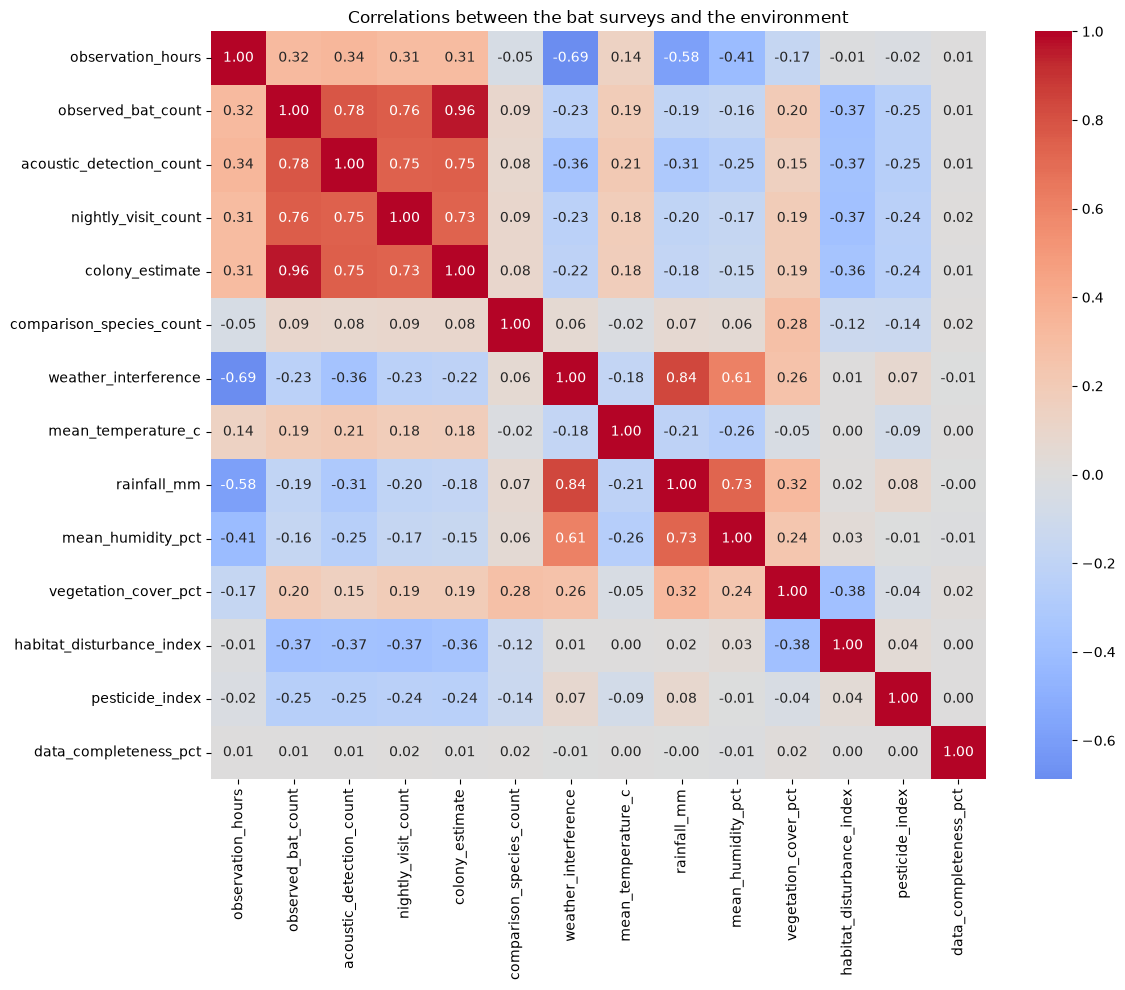

In [21]:
numeric_columns = [c for c in merged.select_dtypes(include="number").columns if c != "survey_duration"]
corr = merged[numeric_columns].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations between the bat surveys and the environment")
plt.tight_layout()
plt.show()

**What the matrix shows.**

- **Obvious links**: the four measures of bat activity (count, acoustic detections, night visits, colony size) are strongly related to each other (0.73 to 0.96). This is normal: they measure the same thing. Likewise, rain, humidity and weather interference evolve together.
- **Interesting links**: two habitat variables are negatively related to the activity:
  - the **habitat disturbance**: about −0.37;
  - the **pesticide index**: about −0.25.

These two variables are almost unrelated to each other (0.04): they are two distinct effects. We look more closely at the relationship between disturbance and activity.

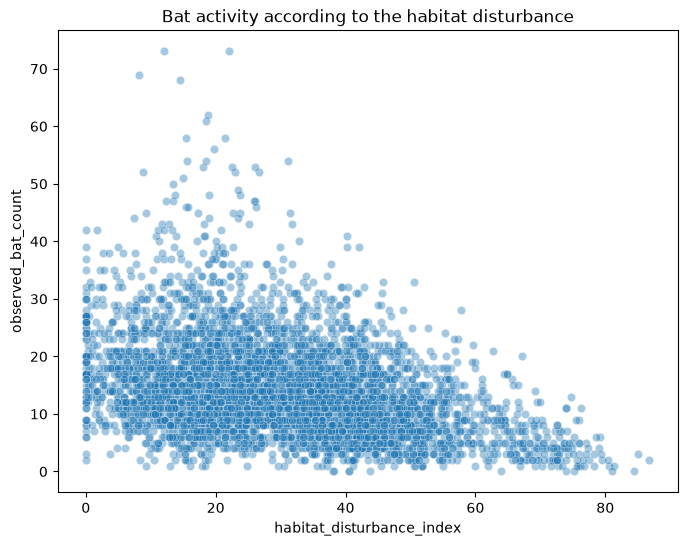

Correlation between disturbance and count:
  Pearson  : -0.375
  Spearman : -0.383


In [22]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=merged, x="habitat_disturbance_index", y="observed_bat_count", alpha=0.4)
plt.title("Bat activity according to the habitat disturbance")
plt.show()

print("Correlation between disturbance and count:")
print("  Pearson  :", round(merged["habitat_disturbance_index"].corr(merged["observed_bat_count"]), 3))
print("  Spearman :", round(merged["habitat_disturbance_index"].corr(merged["observed_bat_count"], method="spearman"), 3))

**What the scatter plot shows.** It is not a straight line. When the habitat is little disturbed, the activity can be very low or very high (from 0 to over 70). When the disturbance increases, it is mostly the **highest values that disappear**. The disturbance therefore seems to limit the maximum number of bats rather than precisely set each value: this is called a **ceiling effect**.

The **Spearman** correlation, computed on ranks, measures any relationship that goes up or down regularly, even if it is not linear. It gives almost the same value as Pearson (−0.38 versus −0.37): the link is real, whatever the method.

**To remember**: the activity decreases when the habitat is disturbed. The link is real but moderate, and a correlation does not prove a cause.

## 1.6 Zoom on the KNT-KES site

**Why this site?** Two clues point to KNT-KES. A field report of April 2024 reports an incident there, and its device `DEV-KNTKES-2` comes back several times among the failures seen in 1.2. We plot the evolution of its activity, month by month.

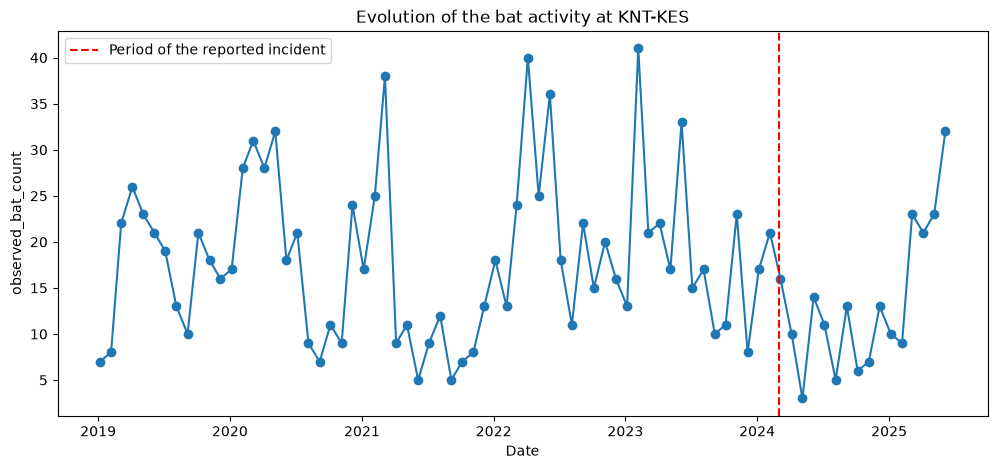

In [23]:
knt_kes = merged[merged["site_code"] == "KNT-KES"].sort_values("survey_start")

plt.figure(figsize=(12, 5))
plt.plot(knt_kes["survey_start"], knt_kes["observed_bat_count"], marker="o")
plt.axvline(pd.Timestamp("2024-03-01"), color="red", linestyle="--", label="Period of the reported incident")
plt.title("Evolution of the bat activity at KNT-KES")
plt.xlabel("Date")
plt.ylabel("observed_bat_count")
plt.legend()
plt.show()

**What the curve shows.**

- **From 2019 to the beginning of 2024**, the activity varies a lot from one month to the next, but the site is clearly active, with regular peaks of 30 to 40 bats (41 at the beginning of 2023).
- **Right after the incident**, the activity collapses: 3 bats, the minimum of the whole 6-year series.
- **Until mid-2025**, it stays low: the peaks no longer exceed 10 to 14, whereas they reached 30 to 40 in the previous years.
- **In 2025**, a slight recovery appears (21 to 32), without returning to the previous level.

The drop therefore coincides with the incident described in the report. But a decrease can also have a general cause, such as a bad year for the whole region. To decide, we must compare KNT-KES with similar sites, **control sites**. We look for the sites that have the same habitat and the same type of monitoring as KNT-KES.

In [24]:
profile = dataframes["monitoring_sites"][dataframes["monitoring_sites"]["site_code"] == "KNT-KES"].iloc[0]
print("KNT-KES :", profile["site_name"], "|", profile["site_category"], "|", profile["habitat_category"], "|", profile["region"])

comparable_sites = dataframes["monitoring_sites"][
    (dataframes["monitoring_sites"]["habitat_category"] == profile["habitat_category"]) &
    (dataframes["monitoring_sites"]["site_category"] == profile["site_category"]) &
    (dataframes["monitoring_sites"]["site_code"] != "KNT-KES")
]
comparable_sites[["site_code", "site_name", "region", "habitat_category", "site_category"]]

KNT-KES : Kestrel Cavern Monitoring Site | cave monitoring | karst_habitat | Kintara Karst Cluster


,site_code,site_name,region,habitat_category,site_category
1,KNT-LUM,Luma Karst Reserve Site,Kintara Karst Cluster,karst_habitat,cave monitoring
2,KNT-SEN,Senna Ridge Cave Site,Kintara Karst Cluster,karst_habitat,cave monitoring
8,KNT-CYP,Dune Reach Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
11,KNT-NNM,Mango Valley Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
12,KNT-JAK,Pandan Grove Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
25,KNT-BME,Ember Garden Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring


Six karst caves of the same region have the same profile as KNT-KES: KNT-LUM, KNT-SEN, KNT-CYP, KNT-NNM, KNT-JAK and KNT-BME. They will be our control sites in part 2.

# 2. KNT-KES versus its control sites

**Why this step?** In part 1, we saw the activity of KNT-KES collapse in spring 2024. But a decrease can have a mundane cause, such as a bad season or unfavourable weather across the region. To find out, we compare KNT-KES with the six **control sites** found in 1.6: karst caves that experience the same climate. If they also drop, the cause is general. Otherwise, something particular happened at KNT-KES.

**How?** We compare, month by month, the count of KNT-KES with the **median** of the controls. The median is preferred to the mean, because a single control with an exceptional month does not move it.

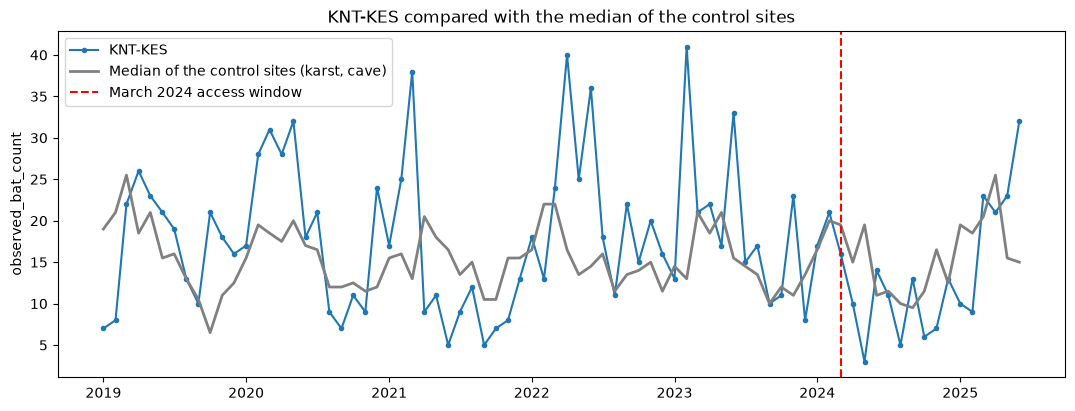

In [25]:
controls = merged[merged["site_code"].isin(comparable_sites["site_code"])]
controls_median = controls.groupby("reporting_month")["observed_bat_count"].median()
kes_series = (merged[merged["site_code"] == "KNT-KES"]
             .set_index("reporting_month")["observed_bat_count"].sort_index())

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(kes_series.index, kes_series.values, marker="o", ms=3, label="KNT-KES")
ax.plot(controls_median.index, controls_median.values, color="grey", lw=2,
        label="Median of the control sites (karst, cave)")
ax.axvline(pd.Timestamp("2024-03-01"), color="red", ls="--", label="March 2024 access window")
ax.set_ylabel("observed_bat_count")
ax.set_title("KNT-KES compared with the median of the control sites")
ax.legend()
plt.show()

We summarise the comparison with one figure: the **ratio** between KNT-KES and the median of the controls, averaged over the months of April to June of each year. A ratio of 1 means "like the controls"; a ratio of 0.5, "twice as low".

In [26]:
kes_table = pd.DataFrame({"KNT-KES": kes_series, "controls median": controls_median})
kes_table["ratio"] = kes_table["KNT-KES"] / kes_table["controls median"]

spring = kes_table[kes_table.index.month.isin([4, 5, 6])]
print("Mean KNT-KES / controls ratio over the months of April to June, per year:")
print(spring.groupby(spring.index.year)["ratio"].mean().round(2))
kes_table.loc["2024-01-01":"2024-09-01"].round(2)

Mean KNT-KES / controls ratio over the months of April to June, per year:
reporting_month
2019    1.29
2020    1.42
2021    0.45
2022    2.25
2023    1.38
2024    0.70
2025    1.48
Name: ratio, dtype: float64


,KNT-KES,controls median,ratio
reporting_month,,,
2024-01-01,17.0,16.5,1.03
2024-02-01,21.0,20.0,1.05
2024-03-01,16.0,19.5,0.82
2024-04-01,10.0,15.0,0.67
2024-05-01,3.0,19.5,0.15
2024-06-01,14.0,11.0,1.27
2024-07-01,11.0,11.5,0.96
2024-08-01,5.0,10.0,0.50
2024-09-01,13.0,9.5,1.37


Finally, we plot each cave separately, with the median of the controls in grey, to see whether other sites also drop.

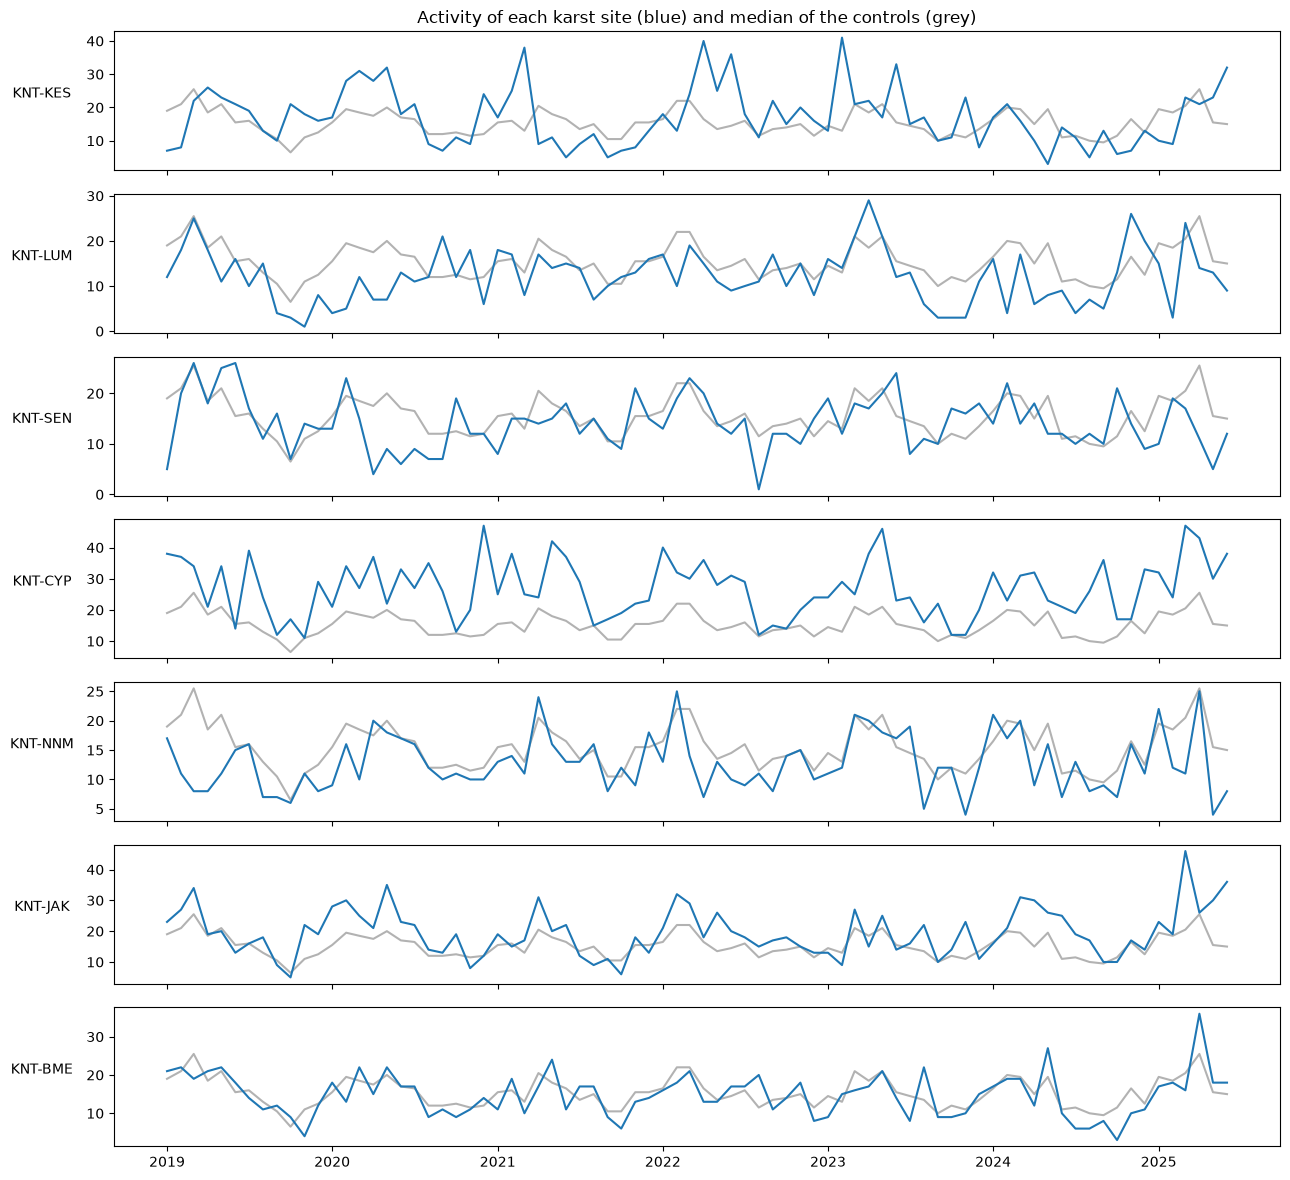

In [27]:
sites_to_plot = ["KNT-KES"] + comparable_sites["site_code"].tolist()
fig, axes = plt.subplots(len(sites_to_plot), 1, figsize=(13, 1.7 * len(sites_to_plot)), sharex=True)
for ax, plot_site in zip(axes, sites_to_plot):
    s = merged[merged["site_code"] == plot_site].set_index("reporting_month")["observed_bat_count"].sort_index()
    ax.plot(controls_median.index, controls_median.values, color="grey", alpha=0.6)
    ax.plot(s.index, s.values, color="tab:blue")
    ax.set_ylabel(plot_site, rotation=0, labelpad=32)
axes[0].set_title("Activity of each karst site (blue) and median of the controls (grey)")
plt.tight_layout()
plt.show()

**What the comparison shows.**

- Usually, in spring, KNT-KES is **more active** than the other caves: depending on the year, the ratio goes from 1.29 to 2.25.
- Two springs are an exception: **2024** (ratio of 0.70) and **2021** (0.45). In May 2024, KNT-KES counts 3 bats when the median of the controls counts 19.5.
- The controls, for their part, do not drop. **The 2024 drop is therefore not due to the climate or to the season.**

**An unexpected point: KNT-KES is not alone.** On the small charts, KNT-LUM drops in autumn 2019 then in autumn 2023, and KNT-SEN in spring 2020. Meanwhile, KNT-CYP, KNT-NNM, KNT-JAK and KNT-BME follow the median. Drops at different dates depending on the site cannot come from a common climatic cause. We keep this lead for later.

# 3. Finish the cleaning (course 1)

Part 1 corrected the numbers and the dates. By rereading the values of each column, four problems remain:

1. **Categories written in several ways**: `routine inspection`, `ROUTINE INSPECTION` and `Routine Inspection` designate the same thing.
2. **Duplicate rows**, with the same identifier.
3. **Inconsistent types or units**: `acoustic_quality` is stored as text, and a few fruit-set rates are written as a fraction (0.47) instead of a percentage (47%).
4. **Missing values**: for each one, we must decide whether to fill it in, or whether its absence means something.

Each cleaning choice can bias what follows. We therefore explain each decision.

We first load all the libraries used in the rest of the report.

In [28]:
# Libraries used in the rest of the report
import re
import warnings
import contextlib
import io
from collections import Counter

import networkx as nx
from networkx.algorithms import bipartite
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA, TruncatedSVD, LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from mlxtend.frequent_patterns import apriori, association_rules
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import pm4py   # pm4py displays a license banner on import

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## 3.1 Harmonise the categories

We first display the categories as they are entered. The columns that contain **codes** (`fault_code`, `observer_team`, `weather_exception_code`, `maintenance_provider`) are not concerned: they are identifiers, already written consistently.

In [29]:
categorical_columns = {
    "bat_surveys": ["survey_method", "survey_quality"],
    "environmental_monthly": ["land_use_category"],
    "monitoring_device_operations": ["maintenance_type", "record_status"],
    "orchard_surveys": ["agricultural_disturbance_note"],
    "monitoring_sites": ["site_category", "habitat_category", "cave_access_category"],
}
for table, columns in categorical_columns.items():
    for col in columns:
        print(f"{table}.{col}:", dataframes[table][col].value_counts().to_dict())

bat_surveys.survey_method: {'acoustic_and_visual': 1743, 'acoustic_transect': 1617, 'fixed_acoustic_station': 1614, 'FIXED_ACOUSTIC_STATION': 9, 'ACOUSTIC_AND_VISUAL': 4, 'ACOUSTIC_TRANSECT': 4, 'Fixed_Acoustic_Station': 2, 'Acoustic_Transect': 1}
bat_surveys.survey_quality: {'high': 2690, 'acceptable': 2166, 'limited': 138}
environmental_monthly.land_use_category: {'mixed_forest': 1481, 'coastal_habitat': 780, 'durian_orchard': 777, 'karst_habitat': 697, 'research_site': 467, 'mixed_agriculture': 388, 'protected_forest': 234, 'degraded_land': 153, 'Karst_Habitat': 4, 'DEGRADED_LAND': 2, 'DURIAN_ORCHARD': 2, 'Degraded_Land': 1, 'KARST_HABITAT': 1, 'Research_Site': 1, 'Durian_Orchard': 1, 'MIXED_AGRICULTURE': 1, 'Mixed_Agriculture': 1, 'Mixed_Forest': 1}
monitoring_device_operations.maintenance_type: {'routine inspection': 4785, 'corrective maintenance': 137, 'sensor replacement': 52, 'ROUTINE INSPECTION': 12, 'Routine Inspection': 8}
monitoring_device_operations.record_status: {'closed

The function `normalize_category` lowercases the text and removes the extra spaces. We apply it to each column, then we count the categories before and after.

In [30]:
def normalize_category(series):
    # lowercase + superfluous spaces removed: "  Routine  Inspection " -> "routine inspection"
    return series.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

for table, columns in categorical_columns.items():
    for col in columns:
        before = dataframes[table][col].nunique()
        dataframes[table][col] = normalize_category(dataframes[table][col])
        print(f"{table}.{col}: {before} -> {dataframes[table][col].nunique()} categories")

bat_surveys.survey_method: 8 -> 3 categories
bat_surveys.survey_quality: 3 -> 3 categories
environmental_monthly.land_use_category: 18 -> 8 categories
monitoring_device_operations.maintenance_type: 5 -> 3 categories
monitoring_device_operations.record_status: 3 -> 1 categories
orchard_surveys.agricultural_disturbance_note: 4 -> 2 categories
monitoring_sites.site_category: 4 -> 3 categories
monitoring_sites.habitat_category: 8 -> 8 categories
monitoring_sites.cave_access_category: 2 -> 2 categories


For each category, we keep the lowercase version, which was already the most frequent. No category was merged wrongly: after correction, the number of categories matches the really different categories.

## 3.2 Remove the duplicates

The data dictionary indicates, for each table, the column that must identify each row uniquely (the primary key). We look for the identifiers that appear several times, and we check whether the rows concerned are identical.

In [31]:
primary_keys = [("bat_surveys", "survey_id"), ("monitoring_device_operations", "device_operation_id"),
                  ("orchard_surveys", "orchard_survey_id")]
for table, key in primary_keys:
    df = dataframes[table]
    affected = df[df[key].duplicated(keep=False)].sort_values(key)
    print(f"{table}: {len(affected)} rows share an identifier; "
          f"strictly identical rows (all columns): {df.duplicated().sum()}")
    display(affected.iloc[:, :8])

bat_surveys: 4 rows share an identifier; strictly identical rows (all columns): 2


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count
3182,BAT-0003183,AVL-ABG,2024-03-05 18:00:00,2024-03-12,acoustic_and_visual,38.7,8.0,18.0
4992,BAT-0003183,AVL-ABG,2024-03-05 18:00:00,2024-03-12,acoustic_and_visual,38.7,8.0,18.0
3566,BAT-0003567,AVL-FNQ,2023-09-05 18:00:00,2023-09-12,acoustic_transect,28.9,13.0,4.0
4993,BAT-0003567,AVL-FNQ,2023-09-05 18:00:00,2023-09-12,acoustic_transect,28.9,13.0,4.0


monitoring_device_operations: 4 rows share an identifier; strictly identical rows (all columns): 2


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type
1225,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01,2023-08-31 23:59:59,93.2,73.5,routine inspection
4993,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01,2023-08-31 23:59:59,93.2,73.5,routine inspection
1390,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01,2024-05-31 23:59:59,92.7,78.6,routine inspection
4992,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01,2024-05-31 23:59:59,92.7,78.6,routine inspection


orchard_surveys: 4 rows share an identifier; strictly identical rows (all columns): 2


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity
892,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7
1248,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7
1189,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0
1249,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0


The duplicate rows are identical on all the columns: we keep the first of each pair.

In [32]:
for table, key in primary_keys:
    dataframes[table] = dataframes[table].drop_duplicates(subset=key, keep="first").reset_index(drop=True)
    print(table, "->", dataframes[table].shape)

bat_surveys -> (4992, 16)
monitoring_device_operations -> (4992, 11)
orchard_surveys -> (1248, 11)


**Result.** The duplicate rows are **identical on all the columns** and reuse an identifier that should be unique (`survey_id`, `device_operation_id`, `orchard_survey_id`). We delete them, like the duplicates of `environmental_monthly` in part 1. Keeping them would have counted the same surveys twice for six sites: AVL-ABG, AVL-FNQ, KNT-CHP, KNT-WUQ, and the orchards AVL-NMQ and TMB-HQL.

## 3.3 Fix the types and the units

`acoustic_quality` is converted to a number, with the same comma correction as in part 1. For the fruit-set rate (the share of flowers that give a fruit), we spot the values lower than or equal to 1, which look like fractions.

In [33]:
dataframes["monitoring_device_operations"]["acoustic_quality"] = pd.to_numeric(
    dataframes["monitoring_device_operations"]["acoustic_quality"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
print("acoustic_quality : values non convertibles =",
      dataframes["monitoring_device_operations"]["acoustic_quality"].isna().sum())

orc = dataframes["orchard_surveys"]
fractions = orc["fruit_set_rate_pct"] <= 1
print("Number of fruit-set rates <= 1:", fractions.sum())
display(orc.loc[fractions, ["orchard_survey_id", "site_code", "survey_period", "fruit_set_rate_pct"]])
print("Autres values :", orc.loc[~fractions, "fruit_set_rate_pct"].describe().round(1).to_dict())

acoustic_quality : values non convertibles = 0
Number of fruit-set rates <= 1: 8


,orchard_survey_id,site_code,survey_period,fruit_set_rate_pct
269,ORC-0000270,AVL-TRP,2021-12-01,0.568
412,ORC-0000413,AVL-GRB,2020-11-01,0.543
454,ORC-0000455,AVL-GRB,2024-05-01,0.549
716,ORC-0000717,AVL-YAU,2020-03-01,0.561
718,ORC-0000719,AVL-YAU,2020-05-01,0.595
919,ORC-0000920,AVL-NMQ,2024-02-01,0.467
1060,ORC-0001061,TMB-BRC,2022-11-01,0.581
1180,ORC-0001181,TMB-HQL,2019-11-01,0.555


Autres values : {'count': 1240.0, 'mean': 53.5, 'std': 9.3, 'min': 27.3, '25%': 47.0, '50%': 52.9, '75%': 59.4, 'max': 87.7}


We multiply these values by 100 to bring them back to a percentage.

In [34]:
orc.loc[fractions, "fruit_set_rate_pct"] = orc.loc[fractions, "fruit_set_rate_pct"] * 100
orc["fruit_set_rate_pct"].describe().round(1)

count    1248.0
mean       53.6
std         9.3
min        27.3
25%        47.0
50%        53.0
75%        59.4
max        87.7
Name: fruit_set_rate_pct, dtype: float64

Eight fruit-set rates are between 0.47 and 0.60, whereas the others range from about 13 to 88%. A rate below 1% would make no sense for a producing orchard. On the other hand, 0.47 to 0.60 matches very well 47 to 60% written **as a fraction**: it is a unit problem (course 1). We convert these 8 values to a percentage rather than deleting them.

## 3.4 Handle the missing values

We first count the missing values, table by table.

In [35]:
eco_tables = ["bat_surveys", "environmental_monthly", "monitoring_device_operations", "orchard_surveys",
              "monitoring_sites", "environmental_field_reports"]
missing_vals = pd.concat({t: dataframes[t].isna().sum() for t in eco_tables}, names=["table", "column"])
missing_vals = missing_vals[missing_vals > 0].to_frame("n_missing")
missing_vals["pct"] = [round(100 * n / len(dataframes[t]), 2)
                    for (t, _), n in zip(missing_vals.index, missing_vals["n_missing"])]
missing_vals

n_missing     pct
table                        column                                          
bat_surveys                  observer_team                         20    0.40
environmental_monthly        vegetation_cover_pct                  10    0.20
                             pesticide_index                       15    0.30
                             weather_exception_code              4788   95.91
monitoring_device_operations fault_code                          4803   96.21
                             maintenance_provider                  30    0.60
orchard_surveys              agricultural_disturbance_note       1225   98.16
monitoring_sites             elevation_m                            1    1.56
                             programme_end_date                    64  100.00
environmental_field_reports  author_name                            1    3.33

For each column, we decide whether to fill the missing values or leave them empty:

| Column | Decision | Why |
|---|---|---|
| `fault_code`, `weather_exception_code`, `agricultural_disturbance_note`, `programme_end_date` | left empty | Here the absence **is information**: no failure, no weather exception, nothing to report, programme still ongoing. Inventing a value would be wrong. |
| `vegetation_cover_pct`, `pesticide_index` | filled with the site median, in a new `_impute` column | Less than 0.3% missing. These variables mostly depend on the site, and the median is not influenced by extreme values. The original columns stay intact: only the methods that require complete data (PCA, clustering) use the filled versions. |
| `elevation_m` (KNT-CYP) | filled with the median of the karst sites of Kintara | A single site concerned, with a karst profile. |
| `observer_team`, `maintenance_provider`, `author_name` | left empty | These are identifiers: they are used neither for computations nor for distances. |

In [36]:
env = dataframes["environmental_monthly"]
for col in ["vegetation_cover_pct", "pesticide_index"]:
    env[col + "_impute"] = env[col].fillna(env.groupby("site_code")[col].transform("median"))
    print(f"{col}: {env[col].isna().sum()} -> {env[col + '_impute'].isna().sum()} missing")

sites = dataframes["monitoring_sites"]
display(sites.loc[sites["elevation_m"].isna(), ["site_code", "site_name", "habitat_category", "region"]])
karst_elevation = sites.loc[(sites["habitat_category"] == "karst_habitat")
                      & (sites["region"] == "Kintara Karst Cluster"), "elevation_m"].median()
sites["elevation_m"] = sites["elevation_m"].fillna(karst_elevation)
print("Imputed elevation:", karst_elevation)

vegetation_cover_pct: 10 -> 0 missing
pesticide_index: 15 -> 0 missing


,site_code,site_name,habitat_category,region
8,KNT-CYP,Dune Reach Monitoring Site,karst_habitat,Kintara Karst Cluster


Imputed elevation: 185.4


## 3.5 A single analysis table: `eco`

For the rest, it is simpler to work on a single table. We gather the bat surveys, the environment of the month, the state of the device and the characteristics of the site, with one row per site and per month.

We add one variable: the **hourly rate**, i.e. the number of bats observed per hour of observation. The observation duration varies from 5 to 47 hours depending on the month, and the longer we observe, the more bats we count. Dividing by the duration corrects this **effort bias**.

In [37]:
dev = dataframes["monitoring_device_operations"].copy()
dev["reporting_month"] = dev["operation_start"].dt.to_period("M").dt.to_timestamp()

eco = (
    dataframes["bat_surveys"]
    .merge(dataframes["environmental_monthly"], on=["site_code", "reporting_month"], how="inner")
    .merge(dev[["site_code", "reporting_month", "device_reference", "uptime_pct", "acoustic_quality",
                "maintenance_type", "fault_code"]], on=["site_code", "reporting_month"], how="left")
    .merge(dataframes["monitoring_sites"][["site_code", "site_name", "site_category", "region", "habitat_category",
                                           "latitude", "longitude", "elevation_m"]], on="site_code", how="left")
    .sort_values(["site_code", "reporting_month"]).reset_index(drop=True)
)
eco["calendar_month"] = eco["reporting_month"].dt.month
eco["year"] = eco["reporting_month"].dt.year
eco["hourly_rate"] = eco["observed_bat_count"] / eco["observation_hours"]

print("Dimensions:", eco.shape)
print("A single row per (site, month):", not eco.duplicated(["site_code", "reporting_month"]).any())
print("Number of months per site:", eco.groupby("site_code").size().unique())
print("Period covered:", eco["reporting_month"].min().date(), "->", eco["reporting_month"].max().date())
print("Device missing for a month:", eco["uptime_pct"].isna().sum())
eco[["observed_bat_count", "observation_hours", "hourly_rate"]].corr(method="spearman").round(2)

Dimensions: (4992, 42)
A single row per (site, month): True
Number of months per site: [78]
Period covered: 2019-01-01 -> 2025-06-01
Device missing for a month: 0


,observed_bat_count,observation_hours,hourly_rate
observed_bat_count,1.00,0.32,0.94
observation_hours,0.32,1.00,0.02
hourly_rate,0.94,0.02,1.00


We also prepare a table for the orchards: each orchard survey is associated with the bat activity of the same month. It will be used in part 10.

In [38]:
orchard = (dataframes["orchard_surveys"].rename(columns={"survey_period": "reporting_month"})
          .merge(eco[["site_code", "reporting_month", "observed_bat_count", "hourly_rate",
                      "comparison_species_count"]], on=["site_code", "reporting_month"], how="left"))
print(orchard.shape, "-", orchard["observed_bat_count"].isna().sum(), "orchard months without a bat survey")
print("Sites de orchards :", orchard["site_code"].nunique())

(1248, 14) - 0 orchard months without a bat survey
Sites de orchards : 16


**Summary of the cleaning.**

- Harmonised categories: `land_use_category` goes from 18 to 8 categories, `survey_method` from 8 to 3, `record_status` from 3 to 1.
- 6 duplicate rows removed: 2 bat surveys, 2 device operations and 2 orchard surveys.
- 8 fruit-set rates converted from fraction to percentage.
- 25 environmental values and 1 elevation filled with a median, in separate columns.

The `eco` table has **4,992 rows, exactly 64 sites × 78 months** (from January 2019 to June 2025), without any missing month. The hourly rate was the right choice: the raw count increases with the observation duration (Spearman 0.32), the hourly rate does not (0.02).

# 4. Describe the variables (course 1)

Before looking for links, we must know each variable: its order of magnitude, its dispersion, the shape of its distribution. As recommended by course 1, we give the **mean with the standard deviation**, and the **median with the minimum, the maximum and the quartiles**. We add the **skewness**: when it is clearly positive, the distribution has a long tail towards the large values, and the mean becomes misleading.

In [39]:
key_variables = ["observed_bat_count", "hourly_rate", "colony_estimate", "comparison_species_count",
                  "observation_hours", "weather_interference", "mean_temperature_c", "rainfall_mm",
                  "mean_humidity_pct", "vegetation_cover_pct", "habitat_disturbance_index",
                  "pesticide_index", "uptime_pct", "acoustic_quality"]
desc = eco[key_variables].describe().T
desc["skewness"] = eco[key_variables].skew()
desc[["mean", "std", "min", "25%", "50%", "75%", "max", "skewness"]].round(2)

,mean,std,min,25%,50%,75%,max,skewness
observed_bat_count,14.13,8.25,0.0,8.00,13.00,18.00,73.00,1.42
hourly_rate,0.47,0.26,0.0,0.29,0.42,0.60,2.42,1.40
colony_estimate,15.83,9.60,0.0,9.30,14.20,20.50,99.60,1.48
comparison_species_count,10.71,3.45,1.0,8.00,11.00,13.00,26.00,0.33
observation_hours,30.33,5.50,5.0,26.90,30.60,34.10,46.90,-0.37
weather_interference,37.49,16.66,0.0,25.10,36.70,49.00,100.00,0.33
mean_temperature_c,26.38,1.67,21.3,25.19,26.35,27.61,32.00,-0.03
rainfall_mm,159.89,74.90,5.0,95.70,156.25,221.70,384.30,0.18
mean_humidity_pct,75.84,7.25,56.7,70.30,75.90,81.50,96.40,-0.01
vegetation_cover_pct,61.01,14.00,15.0,52.70,62.30,70.90,98.00,-0.44


The histograms show the shape of each distribution. The red line is the mean, the dotted black line the median: when they differ, the distribution is asymmetric.

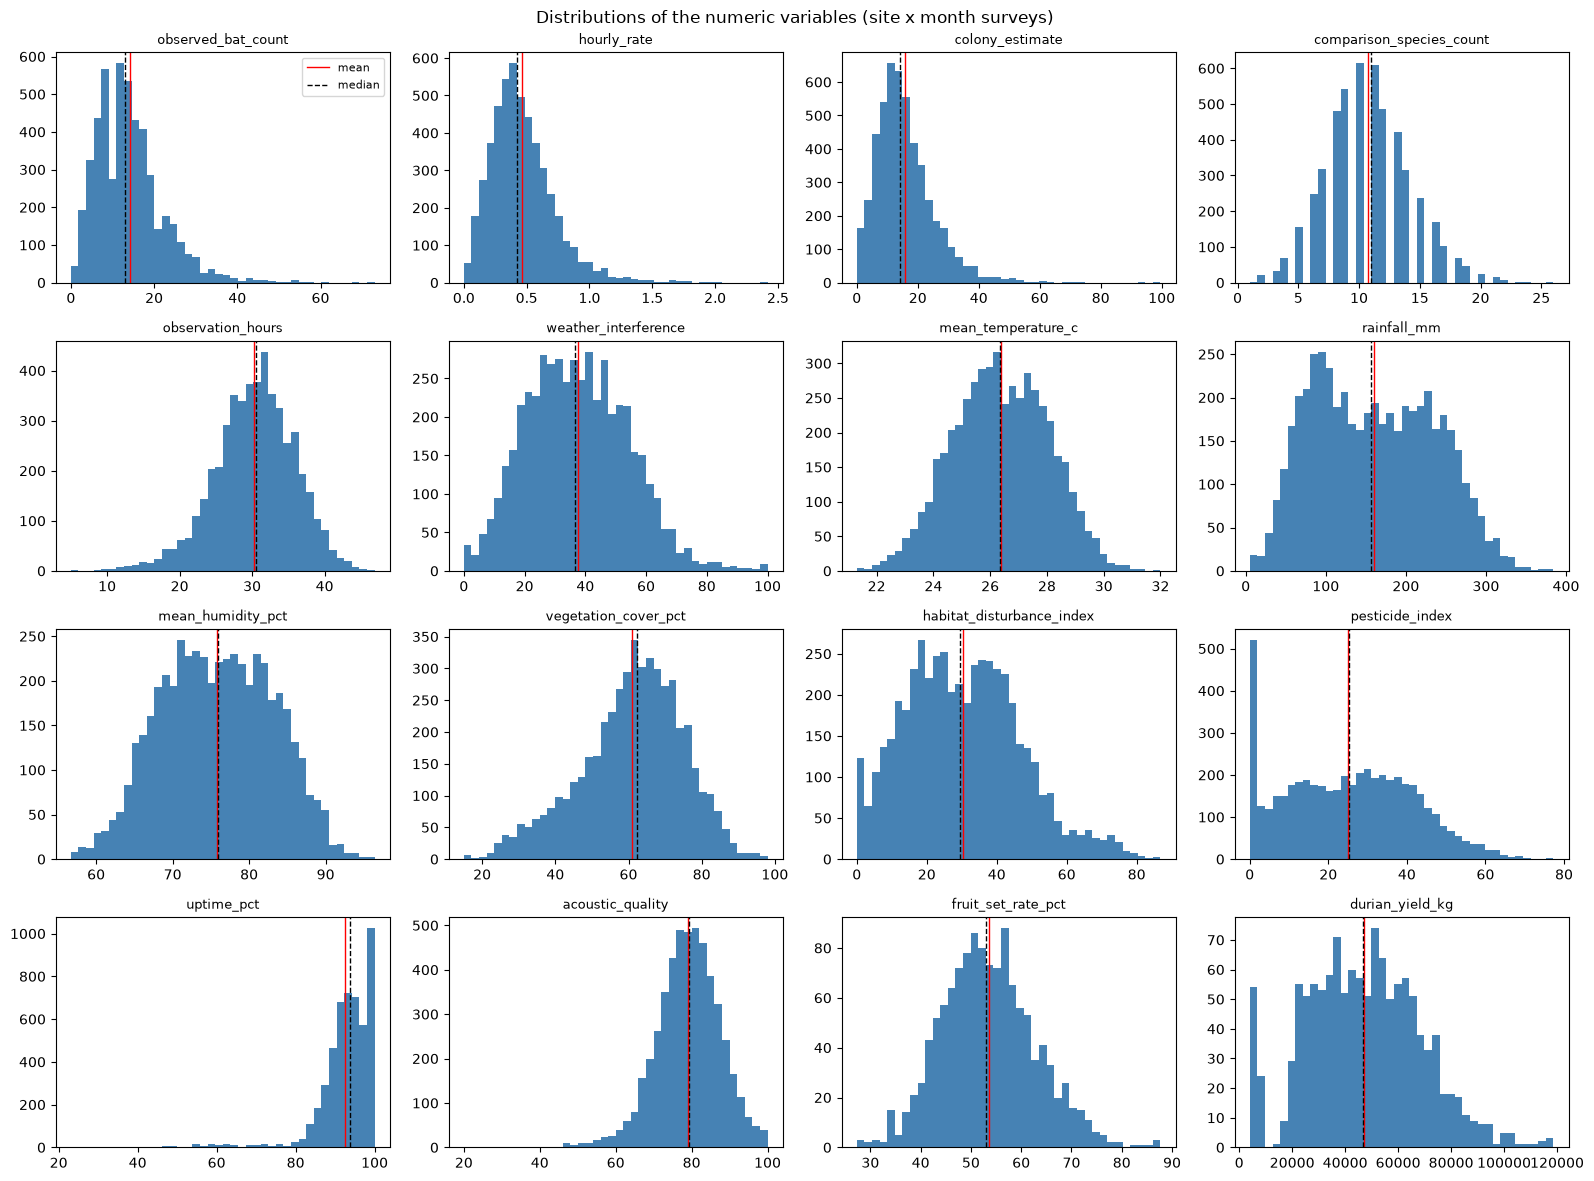

In [40]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, key_variables + ["fruit_set_rate_pct", "durian_yield_kg"]):
    data = eco[col] if col in eco.columns else orchard[col]
    ax.hist(data.dropna(), bins=40, color="steelblue")
    ax.axvline(data.mean(), color="red", lw=1, label="mean")
    ax.axvline(data.median(), color="black", lw=1, ls="--", label="median")
    ax.set_title(col, fontsize=9)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Distributions of the numeric variables (site x month surveys)")
plt.tight_layout()
plt.show()

**What the distributions show.**

- **Bat counts** (count, hourly rate, colony size): most values are average, but a few months go very high, up to 73 bats (skewness ≈ 1.4). The mean is therefore pulled upwards. To compare, we will rather use **medians** and a **logarithm** (`log1p`), which reduces the weight of the large values.
- **Environmental variables** (temperature, rain, humidity, disturbance, pesticides): roughly symmetric distributions. The mean and the standard deviation describe them well.
- **`uptime_pct`**: almost all months exceed 90%, but a few failures go down to 23%.
- **Fruit-set rate**: centred on 53%. There are no more values close to 0 since the correction of part 3.3.

We now compare the activity by site type (boxplots) and by region (violin plots, which show the whole shape of the distribution).

C:\Users\Tanguy\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


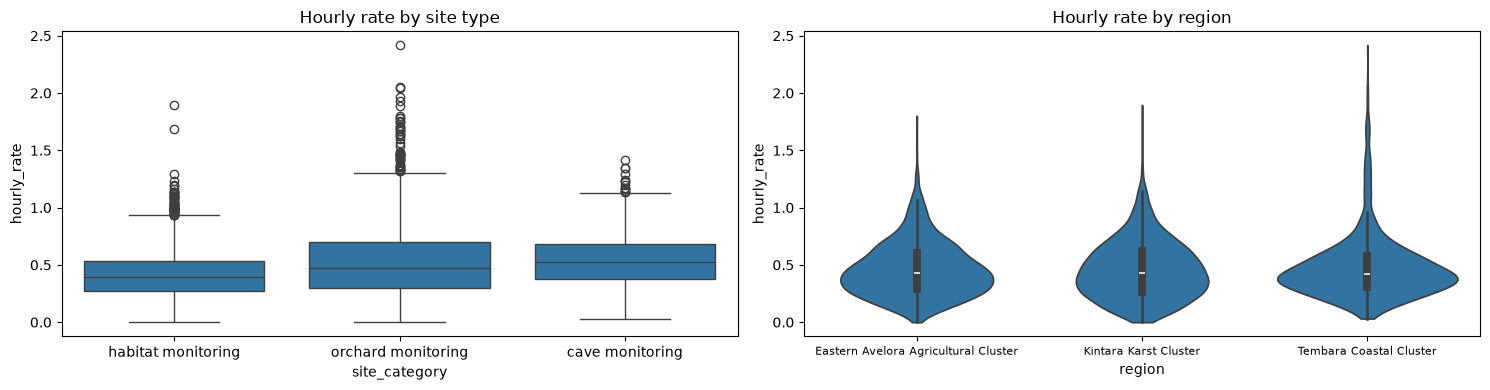

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=eco, x="site_category", y="hourly_rate", ax=axes[0])
axes[0].set_title("Hourly rate by site type")
sns.violinplot(data=eco, x="region", y="hourly_rate", ax=axes[1], cut=0)
axes[1].set_title("Hourly rate by region")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

For the nominal variables, i.e. categories without order, we simply count how many times each category appears.

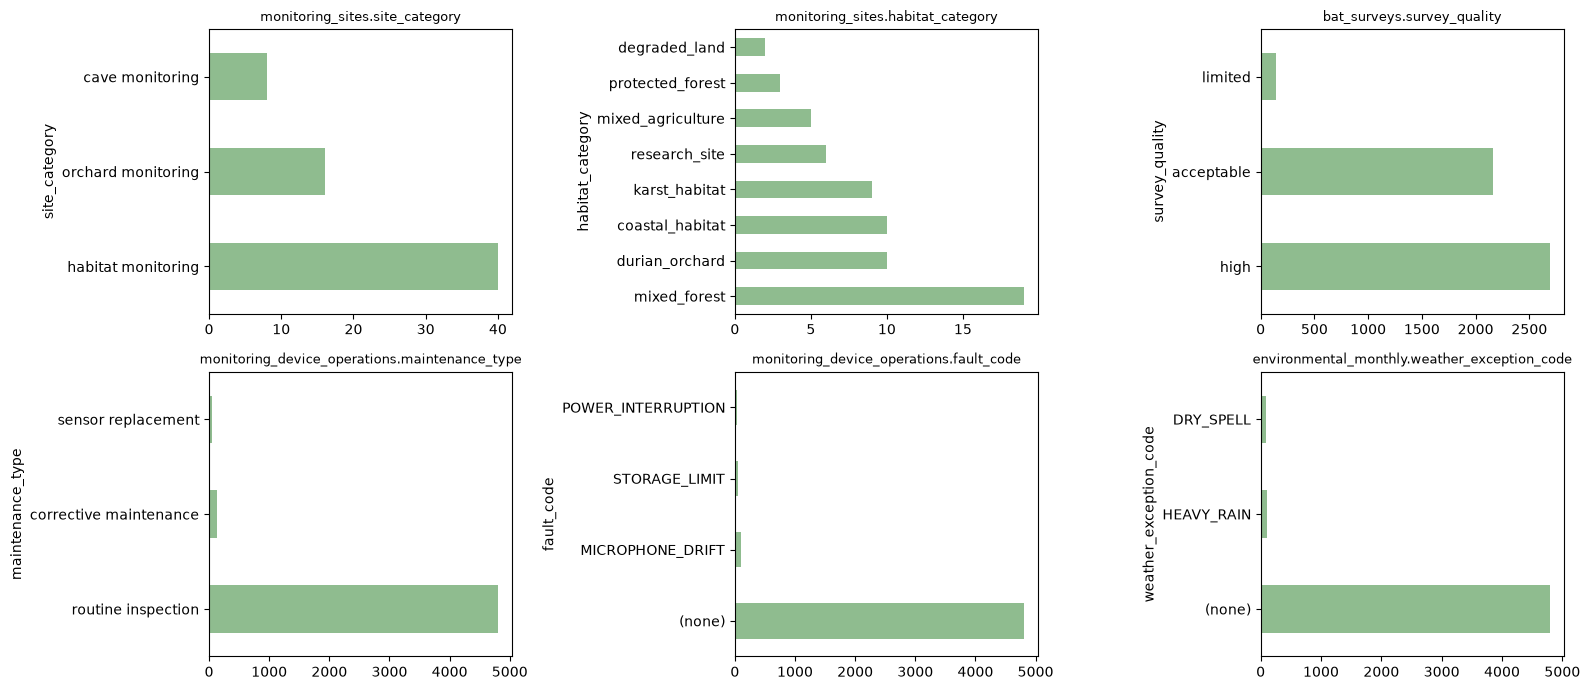

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (table, col) in zip(axes.flat, [("monitoring_sites", "site_category"), ("monitoring_sites", "habitat_category"),
                                        ("bat_surveys", "survey_quality"), ("monitoring_device_operations", "maintenance_type"),
                                        ("monitoring_device_operations", "fault_code"),
                                        ("environmental_monthly", "weather_exception_code")]):
    dataframes[table][col].fillna("(none)").value_counts().plot.barh(ax=ax, color="darkseagreen")
    ax.set_title(f"{table}.{col}", fontsize=9)
plt.tight_layout()
plt.show()

**By site type and by region.** The orchards have the most variable activity, with many high values (up to 2.4 bats per hour). The caves have the highest median. The three regions have almost identical distributions: the region alone does not explain the activity.

**Nominal variables.** There are 40 habitat sites, 16 orchards and 8 caves; mixed forest is the most frequent habitat. The technical events are rare:

- surveys of "limited" quality: 2.8%;
- corrective maintenance: 2.7%;
- fault codes: 3.8%;
- weather exceptions: 4.1%.

These few months nevertheless risk producing abnormal values **because of the measurement**, unrelated to the bats. We will take this into account in part 6.

## 4.1 Correlations: Pearson and Spearman

In part 1, we had only computed the Spearman correlation for a single pair of variables. The course recommends computing both coefficients everywhere:

- **Pearson** measures a **linear**, straight-line relationship;
- **Spearman** works on ranks: it measures any relationship that goes up or down regularly, even if it is not straight, and is more robust to extreme values.

If the two coefficients are very different, the relationship is not linear, or extreme values weigh on the result.

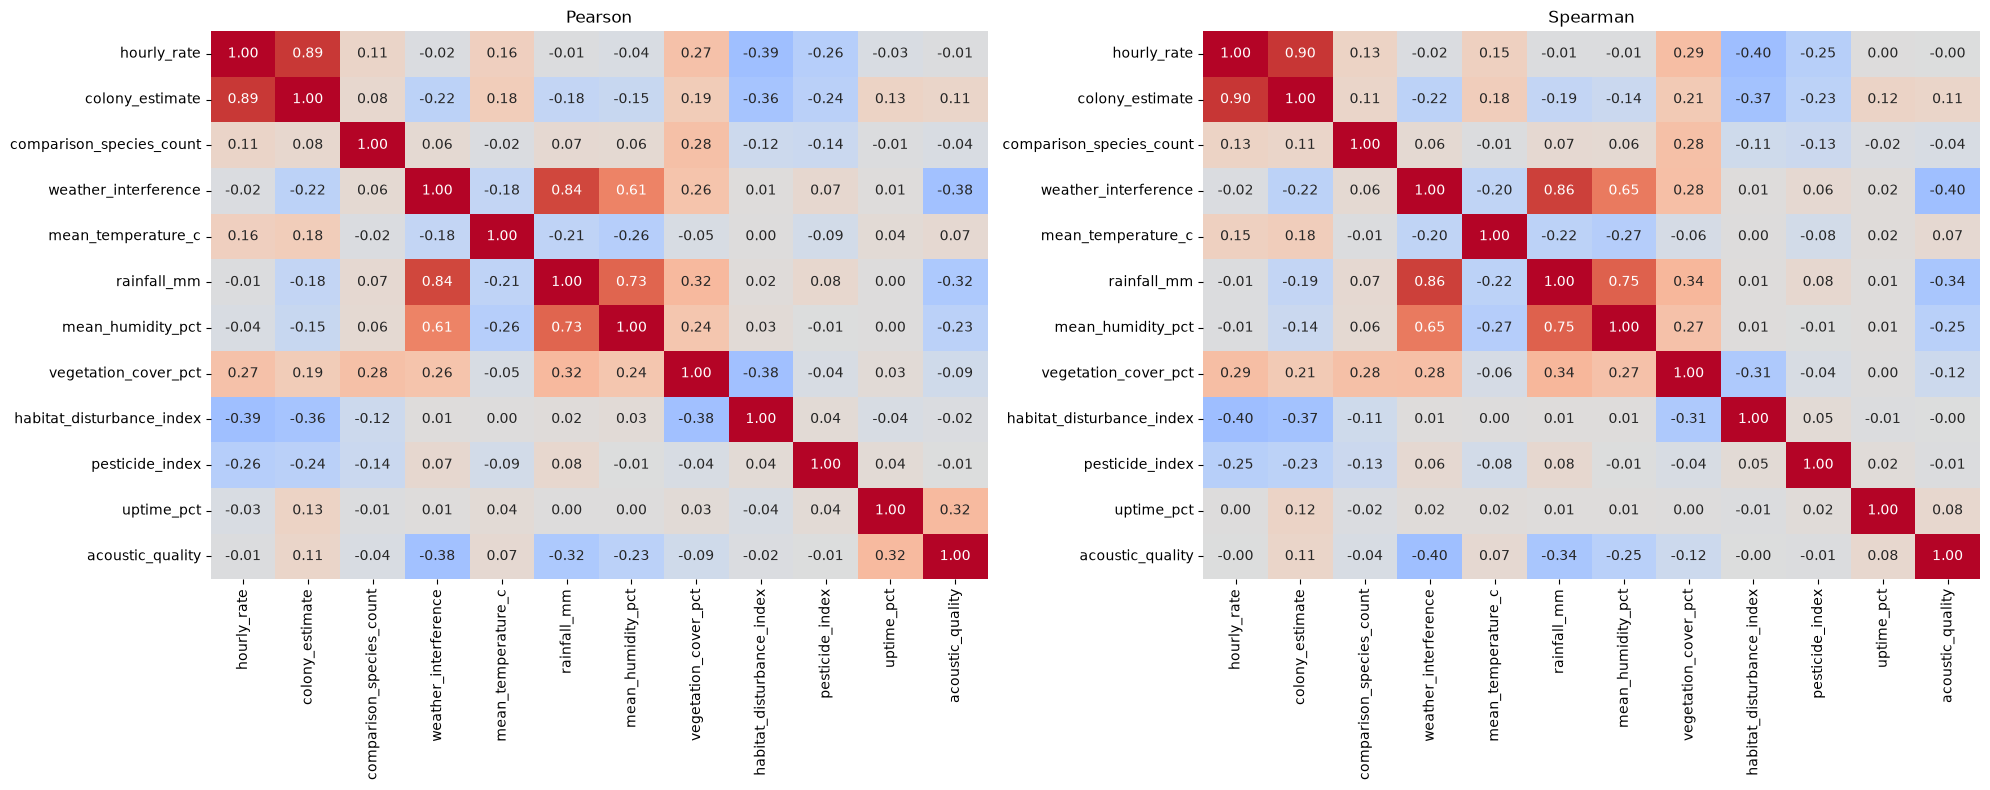

In [43]:
vars_corr = ["hourly_rate", "colony_estimate", "comparison_species_count", "weather_interference",
             "mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "vegetation_cover_pct",
             "habitat_disturbance_index", "pesticide_index", "uptime_pct", "acoustic_quality"]
corr_p = eco[vars_corr].corr(method="pearson")
corr_s = eco[vars_corr].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (label, c) in zip(axes, [("Pearson", corr_p), ("Spearman", corr_s)]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(label)
plt.tight_layout()
plt.show()

We look for the pairs of variables where Pearson and Spearman differ the most, then we list the correlations of each variable with the hourly rate.

In [44]:
triangle = np.triu(np.ones(corr_p.shape, dtype=bool), k=1)
corr_gaps = (corr_s - corr_p).where(triangle).stack()
print("Largest Spearman - Pearson gaps:")
print(corr_gaps.reindex(corr_gaps.abs().sort_values(ascending=False).index).head(6).round(2))
print("\nSpearman correlations with the hourly rate:")
print(corr_s["hourly_rate"].drop("hourly_rate").sort_values().round(2))

Largest Spearman - Pearson gaps:
uptime_pct                 acoustic_quality            -0.23
vegetation_cover_pct       habitat_disturbance_index    0.08
weather_interference       mean_humidity_pct            0.04
hourly_rate                uptime_pct                   0.03
habitat_disturbance_index  uptime_pct                   0.03
vegetation_cover_pct       acoustic_quality            -0.03
dtype: float64

Spearman correlations with the hourly rate:
habitat_disturbance_index   -0.40
pesticide_index             -0.25
weather_interference        -0.02
mean_humidity_pct           -0.01
rainfall_mm                 -0.01
acoustic_quality            -0.00
uptime_pct                   0.00
comparison_species_count     0.13
mean_temperature_c           0.15
vegetation_cover_pct         0.29
colony_estimate              0.90
Name: hourly_rate, dtype: float64


**Result.** Pearson and Spearman are almost identical everywhere. The largest gap (−0.23) concerns `uptime_pct` and `acoustic_quality`, precisely the two most asymmetric variables.

With the **hourly rate**, three links stand out (Spearman):

- **habitat disturbance: −0.40**;
- **pesticides: −0.25**;
- **vegetation cover: +0.29**.

In other words, the more a habitat is disturbed or treated, the fewer bats there are; the more vegetated it is, the more there are. This confirms part 1, with a slightly clearer effect once the observation effort is corrected.

The weather and the state of the devices are **not** related to the activity (|r| ≤ 0.02).

Reminder: **a correlation is not a causation.** These figures say that two variables vary together, not why.

# 5. Compare and group the sites (course 2)

## 5.1 Describe each site with a profile

To compare sites with each other, we summarise each by its mean over 2019-2025: one row per site, i.e. 64 rows. Here are the variables retained, and why:

- **The bat activity**: the four available measures are strongly correlated with each other (0.73 to 0.96, part 1). They say the same thing, so we keep only one, the **hourly rate**.
- **The seasonal amplitude**: the gap between the most active and the least active month. It describes the *rhythm* of the site, not only its level.
- **The comparison species and the environment**: temperature, rain, humidity, vegetation, disturbance, pesticides, elevation.
- **Discarded**: `uptime_pct` and `acoustic_quality`, which describe the device and not the habitat, and `weather_interference`, which repeats the information of the rain and the humidity.
- **The nominal variables** (site type and habitat): since they are categories, we compare them with the **Hamming distance**, i.e. the share of characteristics that differ between two sites.

In [45]:
site_profiles = eco.groupby("site_code").agg(
    hourly_rate=("hourly_rate", "mean"),
    comparison_species=("comparison_species_count", "mean"),
    temperature=("mean_temperature_c", "mean"),
    rain=("rainfall_mm", "mean"),
    humidity=("mean_humidity_pct", "mean"),
    vegetation=("vegetation_cover_pct_impute", "mean"),
    disturbance=("habitat_disturbance_index", "mean"),
    pesticide=("pesticide_index_impute", "mean"),
)
rhythm = eco.groupby(["site_code", "calendar_month"])["hourly_rate"].mean().unstack()
site_profiles["seasonal_amplitude"] = rhythm.max(axis=1) - rhythm.min(axis=1)
site_profiles = site_profiles.join(
    dataframes["monitoring_sites"].set_index("site_code")[["elevation_m", "site_category", "habitat_category",
                                                           "region", "latitude", "longitude"]])
profile_vars = ["hourly_rate", "comparison_species", "seasonal_amplitude", "temperature", "rain",
               "humidity", "vegetation", "disturbance", "pesticide", "elevation_m"]

c = site_profiles[profile_vars].corr(method="spearman")
print("Pairs of profile variables with |Spearman| > 0.8:")
print(c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().loc[lambda s: s.abs() > 0.8].round(2))
site_profiles[profile_vars].describe().round(2)

Pairs of profile variables with |Spearman| > 0.8:
comparison_species  vegetation    0.84
dtype: float64


,hourly_rate,comparison_species,seasonal_amplitude,temperature,rain,humidity,vegetation,disturbance,pesticide,elevation_m
count,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00
mean,0.47,10.71,0.30,26.38,159.89,75.84,61.01,30.36,25.02,148.44
std,0.19,1.01,0.13,1.03,18.27,3.26,12.55,15.06,14.61,96.44
min,0.10,8.13,0.05,23.85,121.61,67.85,28.68,5.27,2.12,5.00
25%,0.35,10.16,0.21,25.58,146.00,74.35,54.52,19.32,13.62,82.35
50%,0.45,10.94,0.27,26.45,157.86,75.98,62.85,31.32,26.15,148.00
75%,0.54,11.40,0.38,27.08,171.67,77.59,69.82,39.59,35.54,221.95
max,1.38,12.74,0.63,29.39,205.35,83.66,83.51,72.80,52.21,418.80


## 5.2 Put the variables on the same scale

Rain is counted in hundreds of millimetres and elevation in hundreds of metres, whereas the hourly rate is below 1. If we compute a distance between sites without precaution, the variables with large numbers crush the others. To check, we compute the share of each variable in the distance between KNT-KES and the other sites, on the **raw** data.

In [46]:
X_raw = site_profiles[profile_vars]
squares = (X_raw - X_raw.loc["KNT-KES"]) ** 2
(squares.sum() / squares.sum().sum()).sort_values(ascending=False).round(3).to_frame("share of the raw distance")

,share of the raw distance
elevation_m,0.939
rain,0.021
disturbance,0.016
vegetation,0.013
pesticide,0.011
humidity,0.001
temperature,0.000
comparison_species,0.000
hourly_rate,0.000
seasonal_amplitude,0.000


We then standardise the variables (mean 0, standard deviation 1), then we compare several distances: Euclidean, Manhattan, cosine, Hamming, and a **mixed** distance that combines the numeric variables and the categories. For each, we list the 5 sites closest to KNT-KES.

In [47]:
X_std = pd.DataFrame(StandardScaler().fit_transform(X_raw), index=X_raw.index, columns=profile_vars)
X_nom = pd.get_dummies(site_profiles[["site_category", "habitat_category"]]).astype(bool)

distances = {
    "euclidean (raw)": pairwise_distances(X_raw, metric="euclidean"),
    "euclidean (standardised)": pairwise_distances(X_std, metric="euclidean"),
    "manhattan (standardised)": pairwise_distances(X_std, metric="cityblock"),
    "cosine (standardised)": pairwise_distances(X_std, metric="cosine"),
    "hamming (nominal)": pairwise_distances(X_nom.values, metric="hamming"),
}
# mixed distance: half numeric (rescaled to [0, 1]) + half nominal (Hamming)
d_num = distances["euclidean (standardised)"] / distances["euclidean (standardised)"].max()
distances["mixed (num. + nominal)"] = 0.5 * d_num + 0.5 * distances["hamming (nominal)"]

i_kes = site_profiles.index.get_loc("KNT-KES")


def nearest(D, i, n=5):
    order = [j for j in np.argsort(D[i], kind="stable") if j != i]   # excludes the site itself
    return site_profiles.index[order[:n]].tolist()


kes_neighbors = pd.DataFrame({label: nearest(D, i_kes) for label, D in distances.items()},
                           index=[f"neighbour {k}" for k in range(1, 6)])
kes_neighbors

,euclidean (raw),euclidean (standardised),manhattan (standardised),cosine (standardised),hamming (nominal),mixed (num. + nominal)
neighbour 1,AVL-SEY,KNT-XAC,KNT-XAC,KNT-CHP,KNT-BME,KNT-JAK
neighbour 2,AVL-ORR,KNT-JAK,KNT-TEX,KNT-XAC,KNT-CYP,KNT-NNM
neighbour 3,AVL-HTY,KNT-TEX,KNT-VLB,KNT-VLB,KNT-JAK,KNT-CYP
neighbour 4,KNT-XAC,TMB-QCB,TMB-HVD,KNT-JAK,KNT-LUM,KNT-SEN
neighbour 5,TMB-BRC,KNT-NNM,KNT-JAK,KNT-CYP,KNT-NNM,KNT-BME


**Without scaling, a single variable counts.** On the raw data, the **elevation accounts for 94% of the distance** between KNT-KES and the other sites. Comparing sites then amounts to looking for those with the same elevation: the distance designates as neighbours sites of Avelora (AVL-SEY, AVL-ORR, AVL-HTY), more than 1,000 km away, which makes no ecological sense.

**We therefore standardise the variables**: each then has a mean of 0 and a standard deviation of 1, and weighs as much as the others. The comparison with the other method of the course, min-max normalisation, is done right after.

**Which distance to choose?**

| Distance | Nearest neighbours of KNT-KES | Remark |
|---|---|---|
| Euclidean / Manhattan (standardised) | KNT-XAC, KNT-TEX, KNT-JAK… | sites of the same region, whatever their type |
| Cosine | brings up KNT-CHP | compares the *shape* of the profile rather than its level |
| Hamming (categories only) | the other karst caves | many ties, hence an arbitrary order |
| **Mixed** (half numeric, half categories) | **KNT-JAK, KNT-NNM, KNT-CYP, KNT-SEN, KNT-BME** | karst caves in a similar environment |

The mixed distance is the most suitable to choose control sites: it confirms after the fact those of part 2.

**Standardisation or min-max?** The course presents another way of putting the variables on the same scale: **min-max** normalisation, which brings each variable between 0 and 1. We redo the same computation with both methods.

In [48]:
# Standardisation or min-max normalisation? (slide 7): the two scalings of the course, compared
from sklearn.preprocessing import MinMaxScaler
X_mm = pd.DataFrame(MinMaxScaler().fit_transform(X_raw), index=X_raw.index, columns=profile_vars)
scale_shares = {}
for label, X in [("raw", X_raw), ("standardised", X_std), ("min-max", X_mm)]:
    squares_e = (X - X.loc["KNT-KES"]) ** 2
    scale_shares[f"share of the distance ({label})"] = squares_e.sum() / squares_e.sum().sum()
scale_comparison = pd.DataFrame(scale_shares)
scale_comparison["standard deviation after min-max"] = X_mm.std()

D_mm = pairwise_distances(X_mm, metric="euclidean")
D_std = distances["euclidean (standardised)"]
iu_e = np.triu_indices(len(X_mm), 1)
print(f"Agreement between the standardised and min-max distances (Spearman over {len(iu_e[0])} pairs of sites): "
      f"{pd.Series(D_std[iu_e]).corr(pd.Series(D_mm[iu_e]), method='spearman'):.2f}")
print("5 nearest neighbours of KNT-KES: standardised", nearest(D_std, i_kes), "/ min-max", nearest(D_mm, i_kes))
print("Common neighbours:", len(set(nearest(D_std, i_kes)) & set(nearest(D_mm, i_kes))), "out of 5")
scale_comparison.sort_values("share of the distance (min-max)", ascending=False).round(3)

Agreement between the standardised and min-max distances (Spearman over 2016 pairs of sites): 0.97
5 nearest neighbours of KNT-KES: standardised ['KNT-XAC', 'KNT-JAK', 'KNT-TEX', 'TMB-QCB', 'KNT-NNM'] / min-max ['KNT-XAC', 'KNT-TEX', 'KNT-VLB', 'TMB-QCB', 'KNT-JAK']
Common neighbours: 4 out of 5


,share of the distance (raw),share of the distance (standardised),share of the distance (min-max),standard deviation after min-max
elevation_m,0.939,0.140,0.158,0.233
seasonal_amplitude,0.000,0.141,0.140,0.219
vegetation,0.013,0.119,0.129,0.229
pesticide,0.011,0.069,0.121,0.292
disturbance,0.016,0.098,0.101,0.223
comparison_species,0.000,0.087,0.087,0.219
rain,0.021,0.086,0.085,0.218
temperature,0.000,0.110,0.079,0.186
humidity,0.001,0.069,0.061,0.206
hourly_rate,0.000,0.082,0.039,0.152


**Result.**

- Both methods solve the elevation problem: after standardisation, no variable exceeds 14% of the distance; after min-max, none exceeds 16%.
- But min-max does not give the same weight to all variables. The hourly rate has a few very high values (TMB-BRC for example): min-max squashes all the others towards 0. Its share in the distance falls to 3.9%, versus 8.2% with standardisation.
- The conclusions, however, do not change: the two distances rank the pairs of sites almost the same way (Spearman of 0.97 over 2,016 pairs), and KNT-KES keeps 4 of its 5 nearest neighbours.

**Decision: we keep standardisation.** It gives the same weight to each variable and is more robust to an extreme site, which matters here, since the activity variable is precisely the most asymmetric.

## 5.3 Summarise and visualise: PCA then t-SNE

We move on to the month-by-month surveys: 4,992 rows and 9 standardised variables. With 9 variables, we cannot draw everything. Two methods of course 2 project the data onto a plane:

- **PCA** (principal component analysis) looks for the axes that summarise the most information;
- **t-SNE** places side by side, on the plane, the points that look alike, to bring out possible groups.

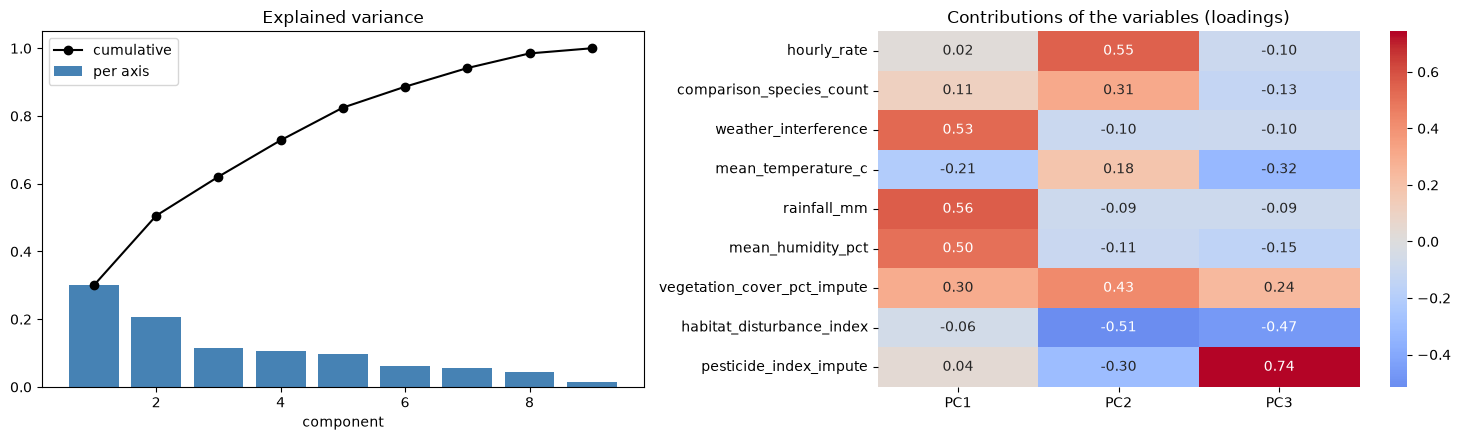

Explained variance (%): [30.  20.5 11.5 10.7  9.6  6.2  5.5  4.3  1.5]


In [49]:
month_vars = ["hourly_rate", "comparison_species_count", "weather_interference", "mean_temperature_c",
             "rainfall_mm", "mean_humidity_pct", "vegetation_cover_pct_impute", "habitat_disturbance_index",
             "pesticide_index_impute"]
X_months = StandardScaler().fit_transform(eco[month_vars])
pca_model = PCA().fit(X_months)
pca_coords = pca_model.transform(X_months)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(1, len(month_vars) + 1), pca_model.explained_variance_ratio_, color="steelblue", label="per axis")
axes[0].plot(range(1, len(month_vars) + 1), np.cumsum(pca_model.explained_variance_ratio_), "o-", color="black", label="cumulative")
axes[0].set_xlabel("component")
axes[0].set_title("Explained variance")
axes[0].legend()
loadings = pd.DataFrame(pca_model.components_[:3].T, index=month_vars, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Contributions of the variables (loadings)")
plt.tight_layout()
plt.show()
print("Explained variance (%):", (100 * pca_model.explained_variance_ratio_).round(1))

We draw the surveys on the first two PCA axes, coloured by region then by habitat.

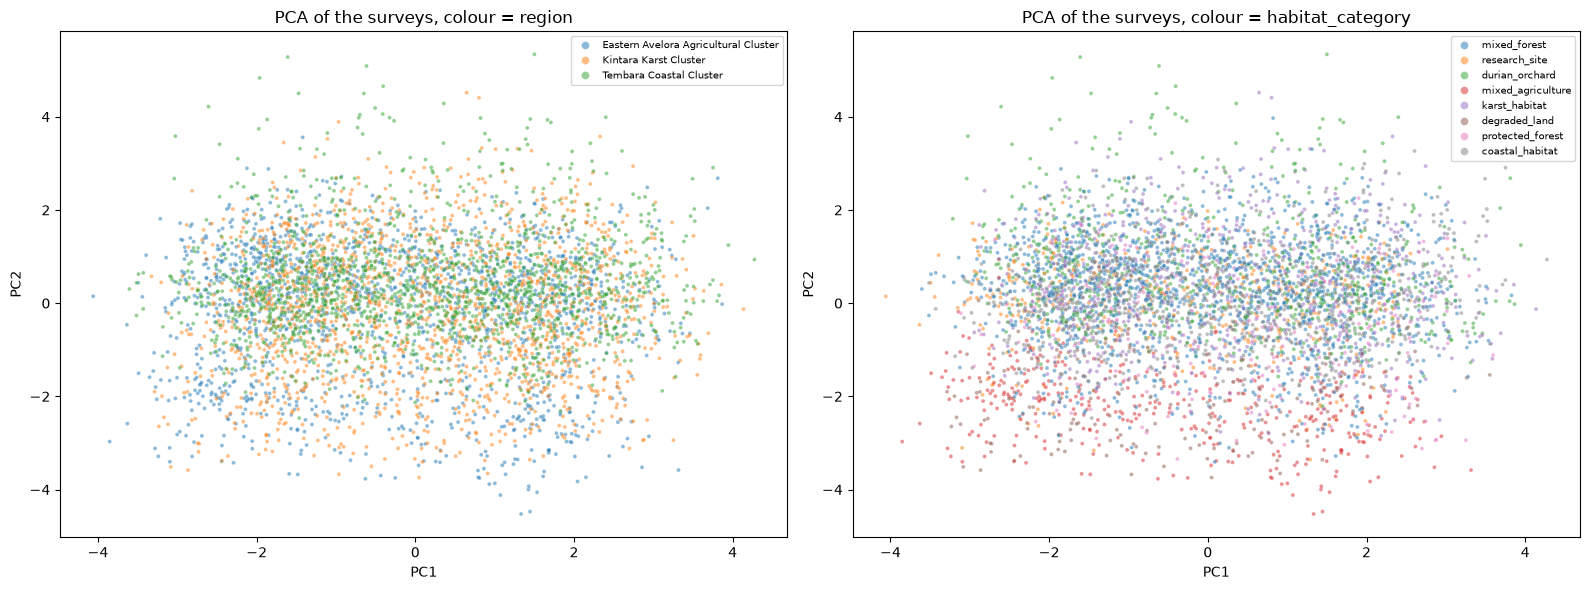

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, color in zip(axes, ["region", "habitat_category"]):
    sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], hue=eco[color], s=8, alpha=0.5, ax=ax)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"PCA of the surveys, colour = {color}")
    ax.legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

**What the PCA shows.** The first two axes summarise 50% of the information, and 5 are needed to reach 83%. The 9 variables therefore bring rather different information: it was justified to keep them all.

- **Axis 1 (30%): the weather.** It gathers the rain, the weather interference and the humidity. The weather interference is therefore mostly an effect of the rain.
- **Axis 2 (20%): the ecological quality.** On one side the hourly rate, the vegetation and the comparison species; on the other, the disturbance and the pesticides. We find, without having looked for it, the relationship "disturbed habitat, fewer bats".
- **Axis 3**: mostly the pesticides.

The three regions overlap completely on the chart. The **mixed agriculture** surveys (in red) are at the bottom of axis 2: these are the most degraded habitats and the poorest in bats.

**Ranking the sites.** Applied to the site profiles, the PCA gives a first axis (29% of the information) that opposes the preserved sites (activity, comparison species, vegetation) to the disturbed sites (disturbance, pesticides). It allows ranking the 64 sites on **a single scale**:

- at the bottom: AVL-GRB, KNT-GGN, AVL-FNQ, AVL-TRP, AVL-HUA, almost all in mixed agriculture or in a degraded habitat;
- at the top: TMB-BRC, KNT-CHP, KNT-TLQ.

In [51]:
# Order the sites on a single dimension: the 1st component of the PCA of the profiles
pca_sites = PCA(n_components=2).fit(X_std)
print("Variance explained by the 2 axes (site profiles):", (100 * pca_sites.explained_variance_ratio_).round(1))
print("Loadings of PC1:", dict(zip(profile_vars, pca_sites.components_[0].round(2))))
score_cp1 = pd.Series(pca_sites.transform(X_std)[:, 0], index=X_std.index, name="score_PC1").sort_values()
pd.concat([score_cp1.head(5), score_cp1.tail(5)]).to_frame().join(site_profiles[["habitat_category", "region"]])

Variance explained by the 2 axes (site profiles): [29.3 16.9]
Loadings of PC1: {'hourly_rate': np.float64(0.46), 'comparison_species': np.float64(0.5), 'seasonal_amplitude': np.float64(0.3), 'temperature': np.float64(-0.02), 'rain': np.float64(-0.13), 'humidity': np.float64(-0.1), 'vegetation': np.float64(0.45), 'disturbance': np.float64(-0.4), 'pesticide': np.float64(-0.23), 'elevation_m': np.float64(0.05)}


,score_PC1,habitat_category,region
site_code,,,
AVL-GRB,-4.472150,mixed_agriculture,Eastern Avelora Agricultural Cluster
KNT-GGN,-4.335277,degraded_land,Kintara Karst Cluster
AVL-FNQ,-2.952078,mixed_agriculture,Eastern Avelora Agricultural Cluster
AVL-TRP,-2.888488,mixed_agriculture,Eastern Avelora Agricultural Cluster
AVL-HUA,-2.876924,mixed_agriculture,Eastern Avelora Agricultural Cluster
TMB-NAC,2.232706,coastal_habitat,Tembara Coastal Cluster
KNT-CYP,2.420831,karst_habitat,Kintara Karst Cluster
KNT-TLQ,2.526254,mixed_forest,Kintara Karst Cluster
KNT-CHP,4.058902,karst_habitat,Kintara Karst Cluster


The t-SNE depends on a setting, the **perplexity**, which roughly fixes the number of neighbours that each point "looks at". We try it with three values: 5, 30 and 100.

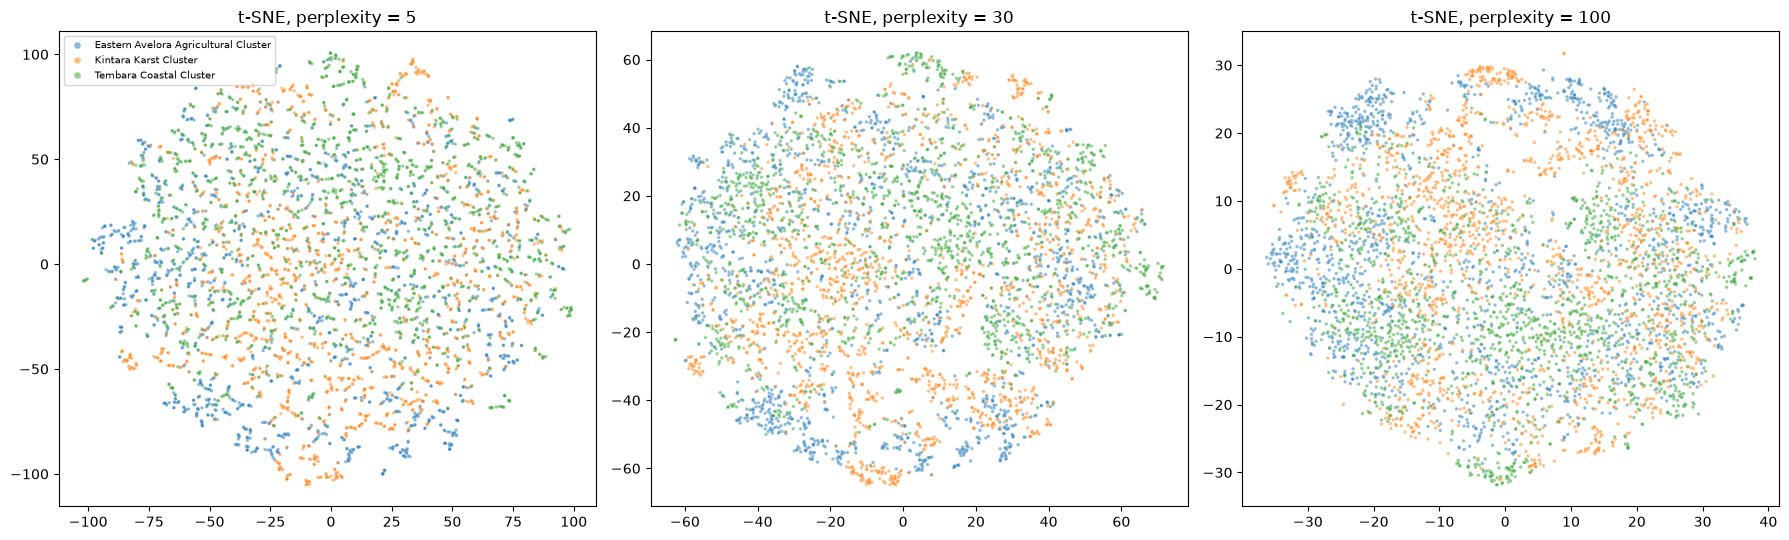

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perplexity in zip(axes, [5, 30, 100]):
    emb = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=0).fit_transform(X_months)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=eco["region"], s=6, alpha=0.5, ax=ax, legend=(perplexity == 5))
    ax.set_title(f"t-SNE, perplexity = {perplexity}")
axes[0].legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

**What the t-SNE shows.**

- With a perplexity of 5, we only see small filaments, without overall organisation.
- With 30 then 100, small islands of the same colour appear: a site keeps close conditions from one month to the next, so its surveys group together.
- No separation into large groups appears.

Neither the PCA nor the t-SNE brings out **natural groups of surveys**: the data vary continuously. The clearest structure remains the ecological quality axis. This leads us towards an analysis **site by site and over time**, rather than a global clustering.

## 5.4 Group the sites: HAC, k-means and DBSCAN

Are there families of sites that look alike? We test the three clustering methods of course 2 on the 64 standardised site profiles:

- **HAC** (hierarchical agglomerative clustering) merges the closest sites step by step and gives a tree, the **dendrogram**. We use the **Ward** criterion, which merges at each step the two groups whose union remains the most homogeneous;
- **k-means** distributes the sites into k groups around k centres;
- **DBSCAN** looks for dense zones and leaves aside the isolated points, called "noise".

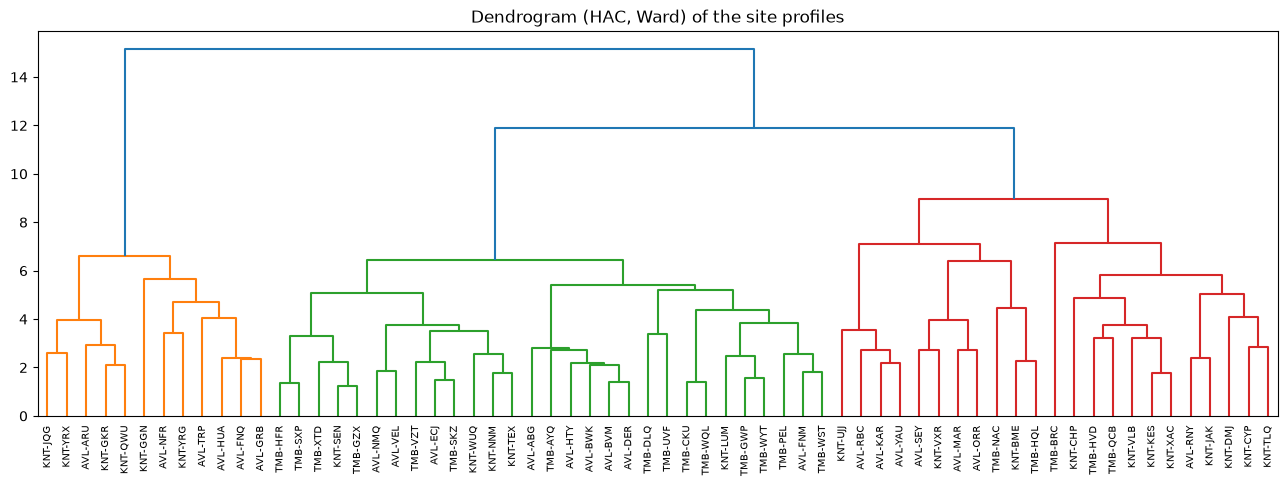

In [53]:
Z = linkage(X_std.values, method="ward")
fig, ax = plt.subplots(figsize=(16, 5))
dendrogram(Z, labels=X_std.index.tolist(), leaf_font_size=7, ax=ax)
ax.set_title("Dendrogram (HAC, Ward) of the site profiles")
plt.show()

To choose the number of groups k, we compute the **silhouette** for k from 2 to 10. It goes from −1 to 1: close to 1, the groups are well separated; close to 0, they overlap.

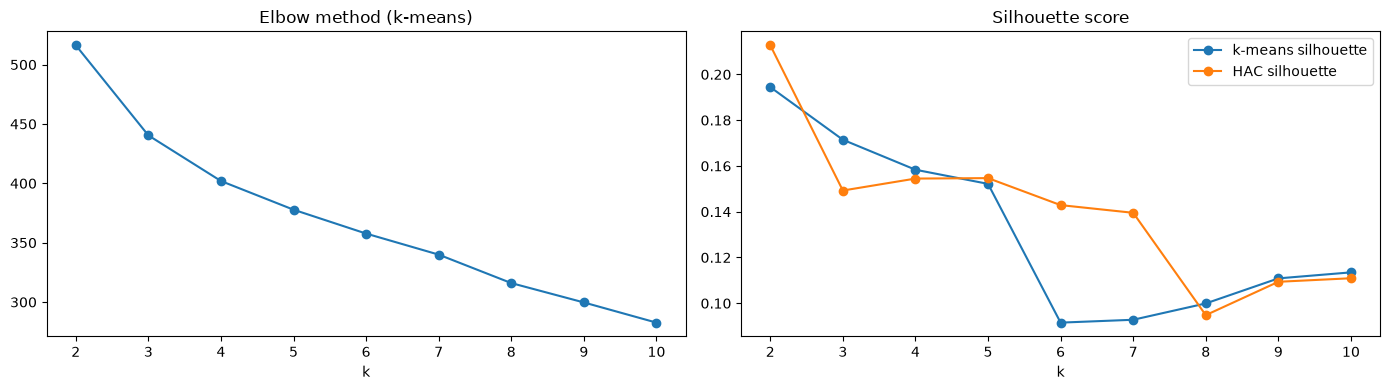

,k-means inertia,k-means silhouette,HAC silhouette
k,,,
2,516.349,0.194,0.213
3,440.408,0.171,0.149
4,401.961,0.158,0.154
5,377.797,0.152,0.155
6,357.681,0.092,0.143
7,339.943,0.093,0.140
8,315.975,0.100,0.095
9,299.658,0.111,0.109
10,282.668,0.113,0.111


In [54]:
k_results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=0).fit(X_std)
    cah = fcluster(Z, k, criterion="maxclust")
    k_results.append({"k": k, "k-means inertia": km.inertia_,
                        "k-means silhouette": silhouette_score(X_std, km.labels_),
                        "HAC silhouette": silhouette_score(X_std, cah)})
k_results = pd.DataFrame(k_results).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
k_results["k-means inertia"].plot(marker="o", ax=axes[0], title="Elbow method (k-means)")
k_results[["k-means silhouette", "HAC silhouette"]].plot(marker="o", ax=axes[1], title="Silhouette score")
plt.tight_layout()
plt.show()
k_results.round(3)

We keep the number of groups that gives the best silhouette for k-means.

In [55]:
chosen_k = int(k_results["k-means silhouette"].idxmax())
print("k retained (best k-means silhouette):", chosen_k)
site_profiles["cluster_kmeans"] = KMeans(n_clusters=chosen_k, init="k-means++", n_init=20,
                                        random_state=0).fit_predict(X_std)
site_profiles["cluster_hac"] = fcluster(Z, chosen_k, criterion="maxclust")

for col in ["habitat_category", "site_category", "region"]:
    print(f"ARI k-means vs {col}: {adjusted_rand_score(site_profiles[col], site_profiles['cluster_kmeans']):.2f}"
          f"   |   ARI HAC vs {col}: {adjusted_rand_score(site_profiles[col], site_profiles['cluster_hac']):.2f}")
display(pd.crosstab(site_profiles["habitat_category"], site_profiles["cluster_kmeans"]))
display(pd.crosstab(site_profiles["region"], site_profiles["cluster_kmeans"]))

k retained (best k-means silhouette): 2
ARI k-means vs habitat_category: 0.06   |   ARI HAC vs habitat_category: 0.08
ARI k-means vs site_category: -0.02   |   ARI HAC vs site_category: 0.00
ARI k-means vs region: -0.00   |   ARI HAC vs region: 0.02


cluster_kmeans,0,1
habitat_category,,
coastal_habitat,7,3
degraded_land,0,2
durian_orchard,9,1
karst_habitat,8,1
mixed_agriculture,0,5
mixed_forest,16,3
protected_forest,2,1
research_site,5,1


cluster_kmeans,0,1
region,,
Eastern Avelora Agricultural Cluster,15,7
Kintara Karst Cluster,15,7
Tembara Coastal Cluster,17,3


To understand each group, we display its mean profile: in red, the variables above average; in blue, those below.

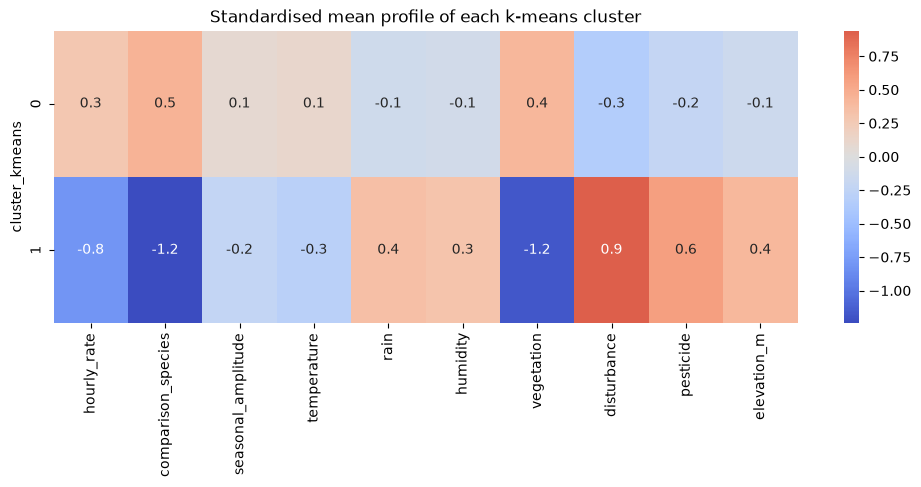

Size of the clusters: {0: 47, 1: 17}
Sites of the smallest cluster: ['AVL-ARU', 'AVL-FNQ', 'AVL-GRB', 'AVL-HUA', 'AVL-KAR', 'AVL-NFR', 'AVL-TRP', 'KNT-GGN', 'KNT-GKR', 'KNT-JQG', 'KNT-QWU', 'KNT-UJJ', 'KNT-YRG', 'KNT-YRX', 'TMB-DLQ', 'TMB-PEL', 'TMB-WST']


In [56]:
centers = X_std.groupby(site_profiles["cluster_kmeans"]).mean()
plt.figure(figsize=(12, 3 + 0.4 * chosen_k))
sns.heatmap(centers, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Standardised mean profile of each k-means cluster")
plt.show()
print("Size of the clusters:", site_profiles["cluster_kmeans"].value_counts().to_dict())
print("Sites of the smallest cluster:", site_profiles.index[site_profiles["cluster_kmeans"]
      == site_profiles["cluster_kmeans"].value_counts().idxmin()].tolist())

For DBSCAN, the main setting is **epsilon**, the distance below which two sites are considered neighbours. We choose it from the chart of the distances to the 4th neighbour, as the course recommends.

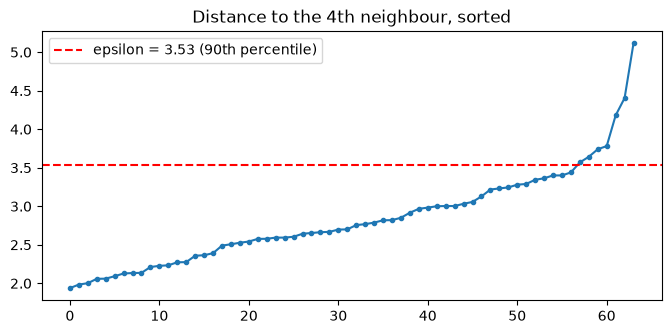

cluster_dbscan
0        62
noise     2
Name: count, dtype: int64
Sites classified as noise: ['KNT-GGN', 'TMB-BRC']


In [57]:
# DBSCAN: epsilon chosen from the k-distance graph (k = min_samples = 4)
dist_k = np.sort(NearestNeighbors(n_neighbors=5).fit(X_std).kneighbors(X_std)[0][:, 4])
eps = float(np.quantile(dist_k, 0.90))

plt.figure(figsize=(8, 3.5))
plt.plot(dist_k, marker=".")
plt.axhline(eps, color="red", ls="--", label=f"epsilon = {eps:.2f} (90th percentile)")
plt.title("Distance to the 4th neighbour, sorted")
plt.legend()
plt.show()

site_profiles["cluster_dbscan"] = DBSCAN(eps=eps, min_samples=4).fit_predict(X_std)
print(site_profiles["cluster_dbscan"].value_counts().rename({-1: "noise"}))
print("Sites classified as noise:", site_profiles.index[site_profiles["cluster_dbscan"] == -1].tolist())

Finally, we place the sites on the PCA plane, coloured according to their k-means group, with the sites isolated by DBSCAN circled in red.

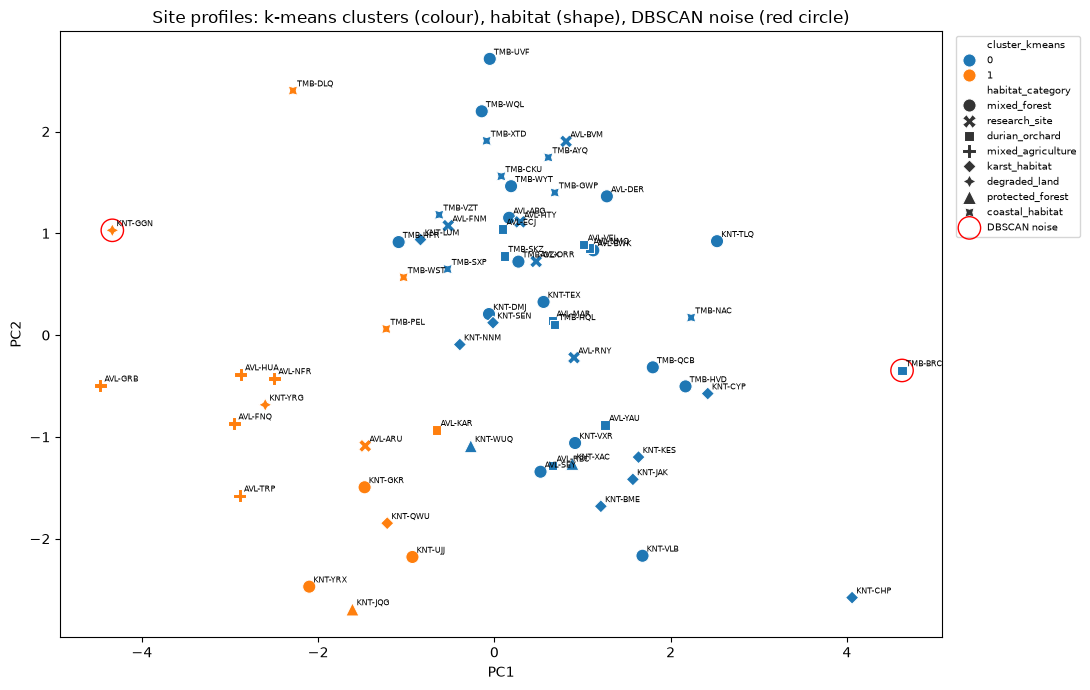

In [58]:
site_coords = pca_sites.transform(X_std)
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(x=site_coords[:, 0], y=site_coords[:, 1], hue=site_profiles["cluster_kmeans"].astype(str),
                style=site_profiles["habitat_category"], s=90, ax=ax)
noise = site_profiles["cluster_dbscan"].values == -1
ax.scatter(site_coords[noise, 0], site_coords[noise, 1], s=260, facecolors="none", edgecolors="red",
           label="DBSCAN noise")
for (x, y), label in zip(site_coords, site_profiles.index):
    ax.annotate(label, (x, y), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Site profiles: k-means clusters (colour), habitat (shape), DBSCAN noise (red circle)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Results.**

- **The groups are weakly marked.** The best silhouette is only 0.19 with k-means (for k = 2), and 0.21 with HAC. The dendrogram shows no obvious cut: the sites vary continuously.
- **K-means separates 47 "preserved" sites from 17 "degraded" sites.** The degraded sites have a lower activity, fewer comparison species and less vegetation, more disturbance and pesticides. They include the 5 mixed-agriculture sites, the 2 degraded sites and a few sites of other habitats.
- **These groups do not match the official categories**: the ARI is at most 0.08 with the habitat, and about 0 with the region and the site type. The ARI measures the agreement between two classifications: 1 if they are identical, 0 if they agree no more than by chance. The declared category of a site therefore says very little about its real state.
- **DBSCAN** puts 62 sites in a single group and isolates **2 sites**: KNT-GGN, the most degraded, and TMB-BRC, the most active. These are the two ends of the ranking of part 5.3.

Among the 8 sites that will be at the centre of what follows, 7 are in the "preserved" group. **On average, they have nothing abnormal**: what will distinguish them are occasional episodes in time.

# 6. Look for regularities and anomalies (course 3)

## 6.1 The surveys seen as "baskets"

Association rules (Apriori) come from the analysis of shopping baskets: which products are often bought together? Here, each survey (a site, a month) becomes a basket, and its characteristics become "items" that are present or absent. The numeric variables are cut into three equal-size bands (the **tertiles**: low, medium, high):

- the **relative activity** is the hourly rate divided by the median of the site. Thus, a site that is naturally poor in bats is not always classified "low";
- the disturbance, the pesticides, the rain and the weather interference are "high" in their upper third; the vegetation is "low" in its lower third;
- the events are taken as they are: weather exceptions, fault codes, corrective maintenance, survey of limited quality, uptime below 80%, habitat.

In [59]:
eco["relative_activity"] = eco["hourly_rate"] / eco.groupby("site_code")["hourly_rate"].transform("median")

def upper_third(col):
    return eco[col] >= eco[col].quantile(2 / 3)

def lower_third(col):
    return eco[col] <= eco[col].quantile(1 / 3)

items = pd.DataFrame({
    "activity=low": lower_third("relative_activity"),
    "activity=high": upper_third("relative_activity"),
    "disturbance=high": upper_third("habitat_disturbance_index"),
    "pesticide=high": upper_third("pesticide_index_impute"),
    "vegetation=low": lower_third("vegetation_cover_pct_impute"),
    "rain=heavy": upper_third("rainfall_mm"),
    "weather_interference=high": upper_third("weather_interference"),
    "maintenance=corrective": eco["maintenance_type"].eq("corrective maintenance"),
    "maintenance=sensor_replacement": eco["maintenance_type"].eq("sensor replacement"),
    "survey=limited_quality": eco["survey_quality"].eq("limited"),
    "uptime<80": eco["uptime_pct"] < 80,
})
for code_ in eco["weather_exception_code"].dropna().unique():
    items[f"exception={code_}"] = eco["weather_exception_code"].eq(code_)
for code_ in eco["fault_code"].dropna().unique():
    items[f"fault={code_}"] = eco["fault_code"].eq(code_)
for h in eco["habitat_category"].unique():
    items[f"habitat={h}"] = eco["habitat_category"].eq(h)
items = items.fillna(False).astype(bool)
print(items.shape)
items.mean().sort_values(ascending=False).round(3).to_frame("support")

(4992, 24)


,support
pesticide=high,0.335
disturbance=high,0.334
vegetation=low,0.334
weather_interference=high,0.334
rain=heavy,0.334
activity=high,0.333
activity=low,0.333
habitat=mixed_forest,0.297
habitat=coastal_habitat,0.156
habitat=durian_orchard,0.156


First step: the **co-occurrence matrix**. Each cell gives, among the surveys that have the characteristic of the row, the percentage that also have that of the column.

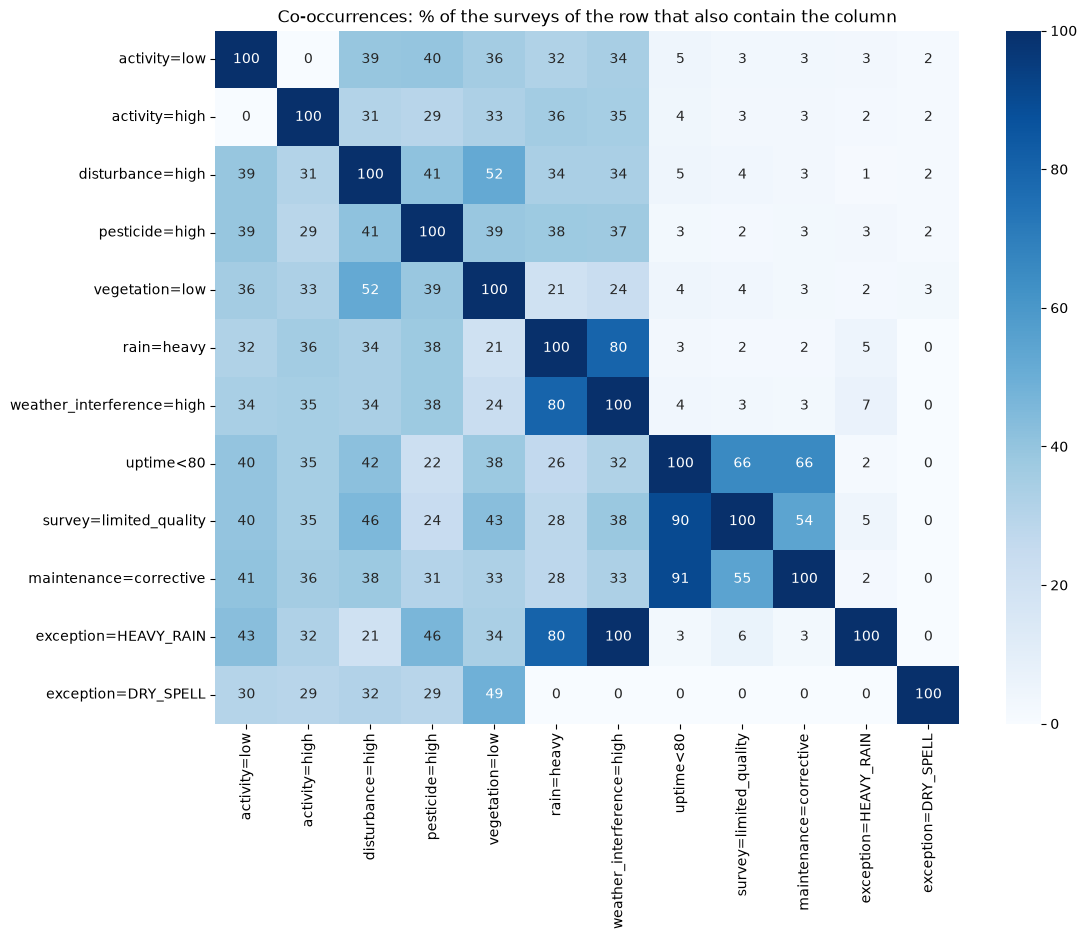

In [60]:
# Co-occurrence matrix in percentage per row: P(column | row)
selection = ["activity=low", "activity=high", "disturbance=high", "pesticide=high", "vegetation=low",
             "rain=heavy", "weather_interference=high", "uptime<80", "survey=limited_quality",
             "maintenance=corrective", "exception=HEAVY_RAIN", "exception=DRY_SPELL"]
B_items = items[selection].astype(int)
cooc = B_items.T @ B_items
cooc_pct = cooc.div(np.diag(cooc), axis=0)

plt.figure(figsize=(12, 9))
sns.heatmap(100 * cooc_pct, annot=True, fmt=".0f", cmap="Blues")
plt.title("Co-occurrences: % of the surveys of the row that also contain the column")
plt.show()

**What the matrix shows.**

- **Obvious links**:
  - 80% of the very rainy months also have a strong weather interference, and this is the case for 100% of the "heavy rain" exceptions;
  - 91% of the corrective maintenance and 90% of the limited-quality surveys fall in a month when the device worked less than 80% of the time.

  The device variables form a separate block, unrelated to ecology.
- **Low activity**: it is found in 39% of the highly disturbed surveys and in 39% of those with high pesticides, versus 33% on average. The link exists, but it is moderate.
- **Faulty device**: when the uptime is below 80%, the activity is low in 40% of the cases. A failure lowers the *measured* count, without the bats necessarily being fewer.

Limit: the matrix only looks at pairs. For combinations of three characteristics, Apriori is needed.

Apriori looks for frequent combinations and derives **rules** of the form "if A, then B". Three measures describe a rule:

- the **support**: the share of surveys where A and B are present together;
- the **confidence**: when A is present, the share of cases where B is also present;
- the **lift**: how many times more often A and B go together than if they were independent (1 = no link).

In [61]:
itemsets = apriori(items, min_support=0.01, use_colnames=True, max_len=3)
rules = association_rules(itemsets, num_itemsets=len(items), metric="lift", min_threshold=1.0)
print(len(itemsets), "frequent itemsets,", len(rules), "rules with lift >= 1")
rule_columns = ["antecedents", "consequents", "support", "confidence", "lift", "leverage"]

to_low = rules[rules["consequents"] == frozenset({"activity=low"})]
print("\nRules leading to a low activity:")
display(to_low.sort_values("lift", ascending=False)[rule_columns].head(10).round(3))

269 frequent itemsets, 716 rules with lift >= 1

Rules leading to a low activity:


,antecedents,consequents,support,confidence,lift,leverage
271,"frozenset({weather_interference=high, habitat=...",frozenset({activity=low}),0.016,0.488,1.463,0.005
135,"frozenset({pesticide=high, disturbance=high})",frozenset({activity=low}),0.062,0.448,1.343,0.016
259,"frozenset({rain=heavy, habitat=mixed_agricultu...",frozenset({activity=low}),0.012,0.446,1.338,0.003
192,"frozenset({pesticide=high, weather_interferenc...",frozenset({activity=low}),0.055,0.442,1.327,0.014
282,"frozenset({maintenance=corrective, uptime<80})",frozenset({activity=low}),0.011,0.427,1.282,0.002
207,"frozenset({pesticide=high, habitat=mixed_agric...",frozenset({activity=low}),0.025,0.426,1.277,0.005
224,"frozenset({vegetation=low, weather_interferenc...",frozenset({activity=low}),0.033,0.418,1.255,0.007
170,"frozenset({disturbance=high, habitat=mixed_agr...",frozenset({activity=low}),0.029,0.416,1.248,0.006
153,"frozenset({weather_interference=high, disturba...",frozenset({activity=low}),0.047,0.414,1.242,0.009
198,"frozenset({pesticide=high, habitat=mixed_forest})",frozenset({activity=low}),0.019,0.413,1.239,0.004


We look at the rules that lead to a high activity, then those with the highest lift.

In [62]:
to_high = rules[rules["consequents"] == frozenset({"activity=high"})]
print("Rules leading to a high activity:")
display(to_high.sort_values("lift", ascending=False)[rule_columns].head(6).round(3))
print("Rules with the highest lift, all consequents combined:")
display(rules.sort_values("lift", ascending=False)[rule_columns].head(8).round(3))

Rules leading to a high activity:


,antecedents,consequents,support,confidence,lift,leverage
366,"frozenset({habitat=coastal_habitat, rain=heavy})",frozenset({activity=high}),0.024,0.415,1.244,0.005
386,"frozenset({habitat=coastal_habitat, weather_in...",frozenset({activity=high}),0.023,0.401,1.204,0.004
33,frozenset({habitat=degraded_land}),frozenset({activity=high}),0.012,0.378,1.135,0.001
372,"frozenset({weather_interference=high, habitat=...",frozenset({activity=high}),0.010,0.376,1.128,0.001
361,"frozenset({rain=heavy, habitat=karst_habitat})",frozenset({activity=high}),0.017,0.375,1.125,0.002
342,"frozenset({habitat=degraded_land, vegetation=l...",frozenset({activity=high}),0.012,0.374,1.123,0.001


Rules with the highest lift, all consequents combined:


,antecedents,consequents,support,confidence,lift,leverage
699,"frozenset({survey=limited_quality, fault=MICRO...",frozenset({maintenance=sensor_replacement}),0.01,0.654,62.769,0.01
702,frozenset({maintenance=sensor_replacement}),"frozenset({survey=limited_quality, fault=MICRO...",0.01,0.981,62.769,0.01
707,frozenset({maintenance=sensor_replacement}),"frozenset({fault=MICROPHONE_DRIFT, uptime<80})",0.01,1.000,53.677,0.01
706,"frozenset({fault=MICROPHONE_DRIFT, uptime<80})",frozenset({maintenance=sensor_replacement}),0.01,0.559,53.677,0.01
708,frozenset({fault=MICROPHONE_DRIFT}),"frozenset({maintenance=sensor_replacement, upt...",0.01,0.536,51.464,0.01
703,frozenset({fault=MICROPHONE_DRIFT}),"frozenset({survey=limited_quality, maintenance...",0.01,0.526,51.464,0.01
122,frozenset({maintenance=sensor_replacement}),frozenset({fault=MICROPHONE_DRIFT}),0.01,1.000,51.464,0.01
698,"frozenset({survey=limited_quality, maintenance...",frozenset({fault=MICROPHONE_DRIFT}),0.01,1.000,51.464,0.01


**Apriori results** (minimum support of 1%, combinations of at most 3 items): 269 frequent combinations and 716 rules with lift greater than or equal to 1.

- **The strongest rules (lift of about 50 to 63) describe how the devices work**, for example "sensor replacement → microphone fault" (confidence of 1). They are strong but **of no interest to us**: they describe a maintenance procedure, not the habitat.
- **The rules leading to a low activity have a modest lift** (1.24 to 1.46). The most frequent is **{high disturbance, high pesticides} → low activity** (lift 1.34): when the two pressures add up, a low activity is 34% more likely than usual. The rule {uptime < 80, corrective maintenance} → low activity is a reminder that part of the low counts comes from the measurement.
- **The rules leading to a high activity** mostly combine coastal or karst habitats and rain (lift ≤ 1.24).

**Conclusion.** The environment influences the activity, but no rule explains a strong drop: the confidence stays below 50%. The drops we are looking for are not situations that repeat under certain conditions: they are **one-off events**. Hence the anomaly detection that follows.

## 6.2 Spot the abnormal values, one variable at a time

We look for abnormal counts with the three methods of the course:

- the **IQR** rule: a value is abnormal if it falls outside the interval [Q1 − 1.5 × IQR ; Q3 + 1.5 × IQR], where the IQR is the gap between the first and the third quartile;
- the **z-score**: the number of standard deviations between the value and the mean (abnormal beyond 3);
- the **modified z-score**: the same idea with the median and the **MAD** (the median absolute deviation from the median), less sensitive to extreme values (abnormal beyond 3.5).

We first apply them to **all the surveys together**, then **site by site**. An anomaly is what does not match the usual behaviour; for a site, the usual behaviour is its own history.

In [63]:
x = eco["observed_bat_count"]
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
z = (x - x.mean()) / x.std()
mad = (x - x.median()).abs().median()
z_mod = 0.6745 * (x - x.median()) / mad

global_ = pd.DataFrame({
    "IQR (outside [Q1-1.5IQR ; Q3+1.5IQR])": [(x < q1 - 1.5 * iqr).sum(), (x > q3 + 1.5 * iqr).sum()],
    "z-score (|z| > 3)": [(z < -3).sum(), (z > 3).sum()],
    "modified z-score (|z| > 3.5)": [(z_mod < -3.5).sum(), (z_mod > 3.5).sum()],
}, index=["values too low", "values too high"])
print(f"IQR bounds: [{q1 - 1.5 * iqr:.1f} ; {q3 + 1.5 * iqr:.1f}]")
global_

IQR bounds: [-7.0 ; 33.0]


,IQR (outside [Q1-1.5IQR ; Q3+1.5IQR]),z-score (|z| > 3),modified z-score (|z| > 3.5)
values too low,0,0,0
values too high,128,68,68


Same computation, but site by site, and on the logarithm of the counts to reduce the weight of the very high values.

In [64]:
# Same computation, but site by site, on the log of the counts (asymmetric distribution)
log_count = np.log1p(eco["observed_bat_count"])
site_median = log_count.groupby(eco["site_code"]).transform("median")
mad_site = (log_count - site_median).abs().groupby(eco["site_code"]).transform("median")
eco["z_mod_site"] = 0.6745 * (log_count - site_median) / mad_site

print("Surveys abnormally low for their site (modified z < -3.5):", (eco["z_mod_site"] < -3.5).sum())
eco.nsmallest(12, "z_mod_site")[["site_code", "reporting_month", "observed_bat_count", "z_mod_site",
                                 "uptime_pct", "fault_code", "survey_quality"]].round(2)

Surveys abnormally low for their site (modified z < -3.5): 30


,site_code,reporting_month,observed_bat_count,z_mod_site,uptime_pct,fault_code,survey_quality
1618,AVL-VEL,2023-11-01,2.0,-6.15,85.4,NaN,acceptable
4173,TMB-NAC,2022-04-01,2.0,-6.02,93.5,NaN,acceptable
2643,KNT-QWU,2024-10-01,0.0,-5.92,96.4,NaN,high
3018,KNT-VLB,2023-07-01,1.0,-5.82,96.5,NaN,acceptable
2695,KNT-SEN,2022-08-01,1.0,-5.75,80.8,NaN,acceptable
3309,KNT-YRG,2021-10-01,0.0,-5.22,93.7,NaN,acceptable
4172,TMB-NAC,2022-03-01,3.0,-5.06,94.1,NaN,acceptable
1571,AVL-VEL,2019-12-01,4.0,-4.53,95.8,NaN,high
1621,AVL-VEL,2024-02-01,4.0,-4.53,90.9,NaN,high
1370,AVL-RNY,2022-09-01,4.0,-4.19,94.7,NaN,acceptable


**All the surveys together.** The three methods flag **only values that are too high** (128 with the IQR, 68 with each z-score), and never values that are too low. The lower bound of the IQR is even negative (−7). When very different sites are mixed, a month with 0 or 3 bats is nothing exceptional.

**Site by site**, the modified z-score brings out **30 surveys abnormally low for their site**. None has a failure, and their quality is always good. They include for example AVL-VEL (November 2023, February 2024), TMB-NAC (March-April 2022) and KNT-SEN (August 2022).

**What we take from it**: each site must be compared with itself, otherwise the drops go unnoticed. The season must also be removed, because a low month can just be a normal seasonal trough: this is the object of part 7.

## 6.3 Spot the abnormal combinations

A survey can look normal variable by variable, but be abnormal through its *combination* of values. We apply the four multivariate methods of the course to 10 standardised variables (activity relative to the site, comparison species, uptime, acoustic quality, weather interference, disturbance, pesticides, vegetation, rain, temperature):

- the **Isolation Forest** cuts the data at random, again and again: an abnormal point ends up isolated in very few cuts;
- the **LOF** compares the density around a point with that around its neighbours;
- **DBSCAN** flags the points that belong to no dense zone;
- **ABOD** looks at the angles under which a point "sees" the others: a point on the edge sees them all in the same direction.

The Isolation Forest, the LOF and ABOD each flag the 2% most suspect surveys. For DBSCAN, epsilon is set at the 98th percentile of the distance to the 10th neighbour. The exact version of ABOD is too slow, because it examines all the triplets of points: we program its fast version, limited to the 10 nearest neighbours.

In [65]:
eco["log_relative_activity"] = np.log1p(eco["observed_bat_count"]) - site_median
anomaly_vars = ["log_relative_activity", "comparison_species_count", "uptime_pct", "acoustic_quality",
                 "weather_interference", "habitat_disturbance_index", "pesticide_index_impute",
                 "vegetation_cover_pct_impute", "rainfall_mm", "mean_temperature_c"]
X_anom = StandardScaler().fit_transform(eco[anomaly_vars])
suspect_share = 0.02

eco["iforest"] = IsolationForest(contamination=suspect_share, random_state=0).fit_predict(X_anom) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=suspect_share)
eco["lof"] = lof.fit_predict(X_anom) == -1
eco["score_lof"] = -lof.negative_outlier_factor_

dist_k_anom = np.sort(NearestNeighbors(n_neighbors=11).fit(X_anom).kneighbors(X_anom)[0][:, 10])
eco["dbscan_noise"] = DBSCAN(eps=float(np.quantile(dist_k_anom, 0.98)), min_samples=10).fit_predict(X_anom) == -1


def fast_abod(X, k=10):
    """ABOD restricted to the k nearest neighbours: variance of the (distance-weighted) angles
    under which a point sees its neighbours. Low variance = point on the periphery = suspect."""
    neighbors = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    upper = np.triu_indices(k, 1)
    scores = np.empty(len(X))
    for i in range(len(X)):
        V = X[neighbors[i]] - X[i]
        norms2 = (V ** 2).sum(axis=1) + 1e-12
        scores[i] = ((V @ V.T) / np.outer(norms2, norms2))[upper].var()
    return scores


eco["score_abod"] = fast_abod(X_anom)
eco["abod"] = eco["score_abod"] <= eco["score_abod"].quantile(suspect_share)

methods = ["iforest", "lof", "dbscan_noise", "abod"]
print(eco[methods].sum())
overlap = pd.DataFrame([[(eco[a] & eco[b]).sum() / (eco[a] | eco[b]).sum() for b in methods] for a in methods],
                            index=methods, columns=methods)
print("\nJaccard index between the sets of flagged surveys:")
overlap.round(2)

iforest         100
lof             100
dbscan_noise     25
abod            100
dtype: int64

Jaccard index between the sets of flagged surveys:


,iforest,lof,dbscan_noise,abod
iforest,1.00,0.14,0.21,0.31
lof,0.14,1.00,0.11,0.37
dbscan_noise,0.21,0.11,1.00,0.24
abod,0.31,0.37,0.24,1.00


We then compare the surveys flagged by each method, and count how many correspond to a measurement problem (uptime below 80%, fault or survey of limited quality).

In [66]:
# An outlier is not necessarily an ecological anomaly: many can come from the device
eco["measurement_issue"] = (eco["uptime_pct"] < 80) | eco["fault_code"].notna() | eco["survey_quality"].eq("limited")
summary = pd.DataFrame({m: [eco.loc[eco[m], "measurement_issue"].mean(),
                          eco.loc[eco[m], "log_relative_activity"].mean()] for m in methods},
                     index=["share with a measurement problem", "mean relative activity (log)"])
summary["all surveys"] = [eco["measurement_issue"].mean(), eco["log_relative_activity"].mean()]
display(summary.round(2))

eco["n_methods"] = eco[methods].sum(axis=1)
print("Surveys flagged by at least 3 methods:")
eco[eco["n_methods"] >= 3].sort_values("log_relative_activity")[
    ["site_code", "reporting_month", "observed_bat_count", "log_relative_activity", "uptime_pct",
     "fault_code", "survey_quality", "n_methods"]].head(15).round(2)

,iforest,lof,dbscan_noise,abod,all surveys
share with a measurement problem,0.77,0.34,0.92,0.57,0.04
mean relative activity (log),-0.62,-0.61,-0.91,-0.73,-0.04


Surveys flagged by at least 3 methods:


,site_code,reporting_month,observed_bat_count,log_relative_activity,uptime_pct,fault_code,survey_quality,n_methods
3423,KNT-YRX,2024-10-01,0.0,-2.25,73.1,STORAGE_LIMIT,acceptable,4
605,AVL-FNQ,2023-12-01,0.0,-1.95,58.5,MICROPHONE_DRIFT,limited,4
697,AVL-GRB,2025-02-01,0.0,-1.95,94.9,NaN,high,4
693,AVL-GRB,2024-10-01,0.0,-1.95,91.7,NaN,high,3
968,AVL-MAR,2021-09-01,1.0,-1.95,85.3,NaN,limited,4
1827,KNT-CHP,2021-10-01,2.0,-1.79,41.7,MICROPHONE_DRIFT,limited,4
2332,KNT-JQG,2024-11-01,1.0,-1.61,78.7,NaN,acceptable,3
4172,TMB-NAC,2022-03-01,3.0,-1.50,94.1,NaN,acceptable,4
2081,KNT-GGN,2023-06-01,0.0,-1.39,99.0,NaN,high,3
2126,KNT-GKR,2020-09-01,1.0,-1.32,99.4,NaN,acceptable,3


**Results.**

- The methods flag rather different surveys. The Jaccard index, which measures the overlap between two lists, goes from 0.11 to 0.37: each method has its own idea of what an "isolated" point is.
- **Most of the flagged surveys are measurement problems**: 92% of the points isolated by DBSCAN, 77% of the alerts of the Isolation Forest and 57% of those of ABOD, whereas these problems only concern 4% of the surveys. A failure produces a very atypical survey (low uptime, poor acoustic quality, low count), which the algorithms spot easily. The LOF is the least sensitive to it (34%).

This is the lesson of course 3: **an outlier is not necessarily an anomaly.** The surveys flagged by at least 3 methods are mostly failures: KNT-YRX in October 2024, AVL-FNQ in December 2023, KNT-CHP in October 2021. We set them aside. A few, however, have a reliable measurement and correspond to real drops, for example TMB-NAC in March 2022 (3 bats, with a device working 94% of the time).

# 7. Time and space (course 5)

## 7.1 Separate the trend, the season and the rest

A drop can be just a **seasonal** effect: there are fewer bats each year at the same period. To avoid mistaking a seasonal trough for an anomaly, we **decompose** the series into three parts:

- the **trend**: the underlying evolution;
- the **seasonality**: the pattern that repeats every year;
- the **residual**: what remains.

We start with the average of all the sites, with a period of 12 months. We also plot the **autocorrelation** (ACF), which indicates whether the series looks like itself shifted by 1, 2… 36 months.

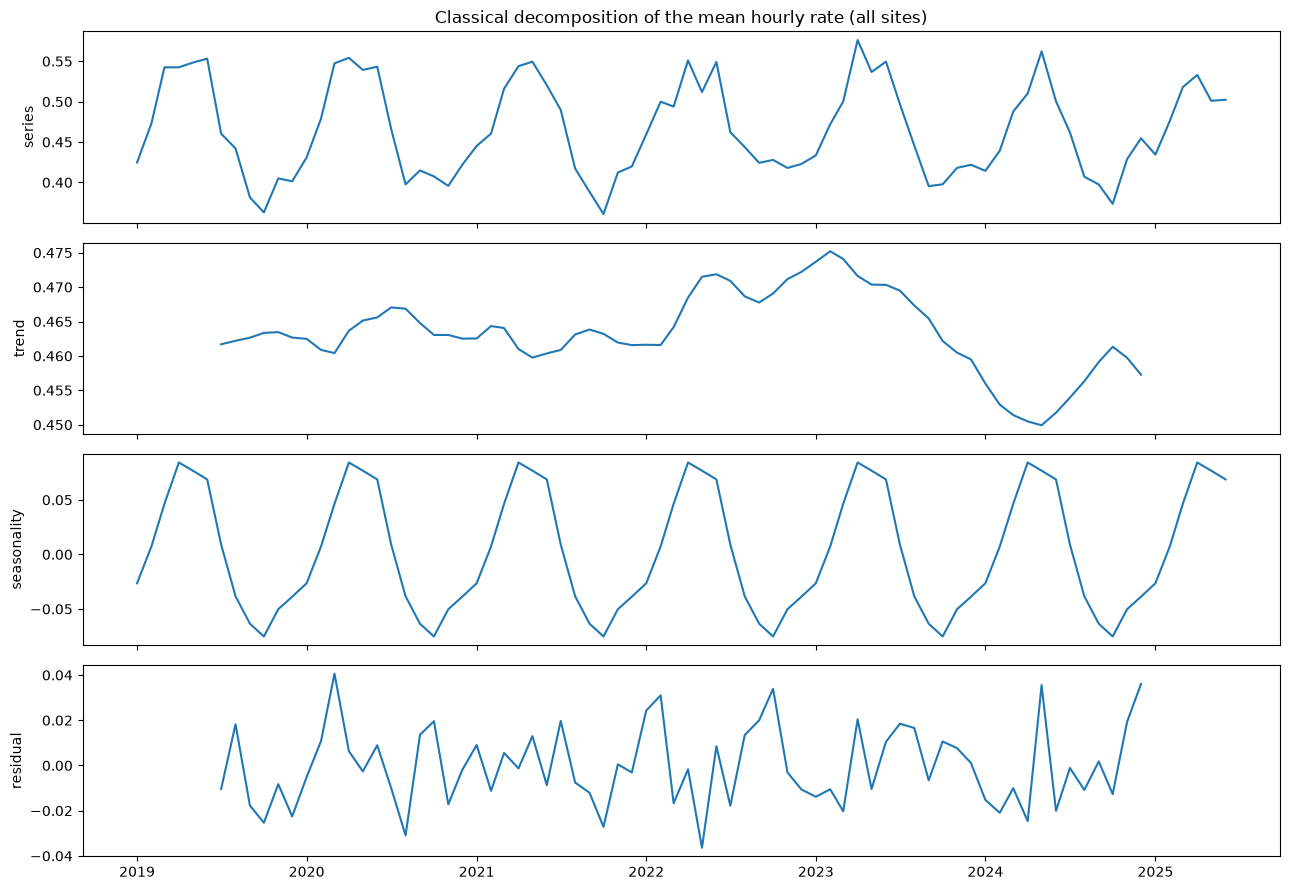

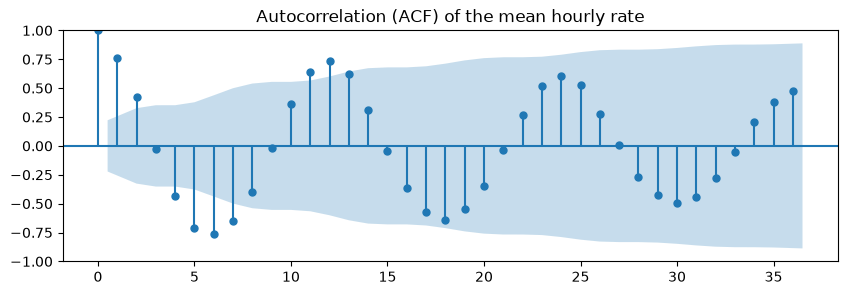

In [67]:
global_series = eco.groupby("reporting_month")["hourly_rate"].mean().asfreq("MS")
decomp = seasonal_decompose(global_series, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (label, component) in zip(axes, [("series", decomp.observed), ("trend", decomp.trend),
                                       ("seasonality", decomp.seasonal), ("residual", decomp.resid)]):
    ax.plot(component)
    ax.set_ylabel(label)
axes[0].set_title("Classical decomposition of the mean hourly rate (all sites)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
plot_acf(global_series, lags=36, ax=ax)
ax.set_title("Autocorrelation (ACF) of the mean hourly rate")
plt.show()

**What the decomposition shows.**

- **A very marked season**: the activity is at its highest from March to June (about 0.55 bats per hour) and at its lowest in September-October (about 0.37). The ACF confirms it, with peaks every 12 months: the cycle is **annual**.
- **A stable trend** until 2023, then a slight decrease in 2024, before a recovery. The decrease is small on average because it only affects a few sites, but it falls at the period of the KNT-KES incident.
- **A small residual** (± 0.04).

Comparing September with April would therefore amount to mistaking a seasonal trough for an anomaly. **The season must be removed before looking for anomalies.**

We now apply the **STL** to KNT-KES. It is a more flexible decomposition than the previous one, and robust to extreme values. We then compare each residual with those of the 13 months around it (a **rolling window**): a month is abnormal if its modified z-score, computed on this window, is below −3.5.

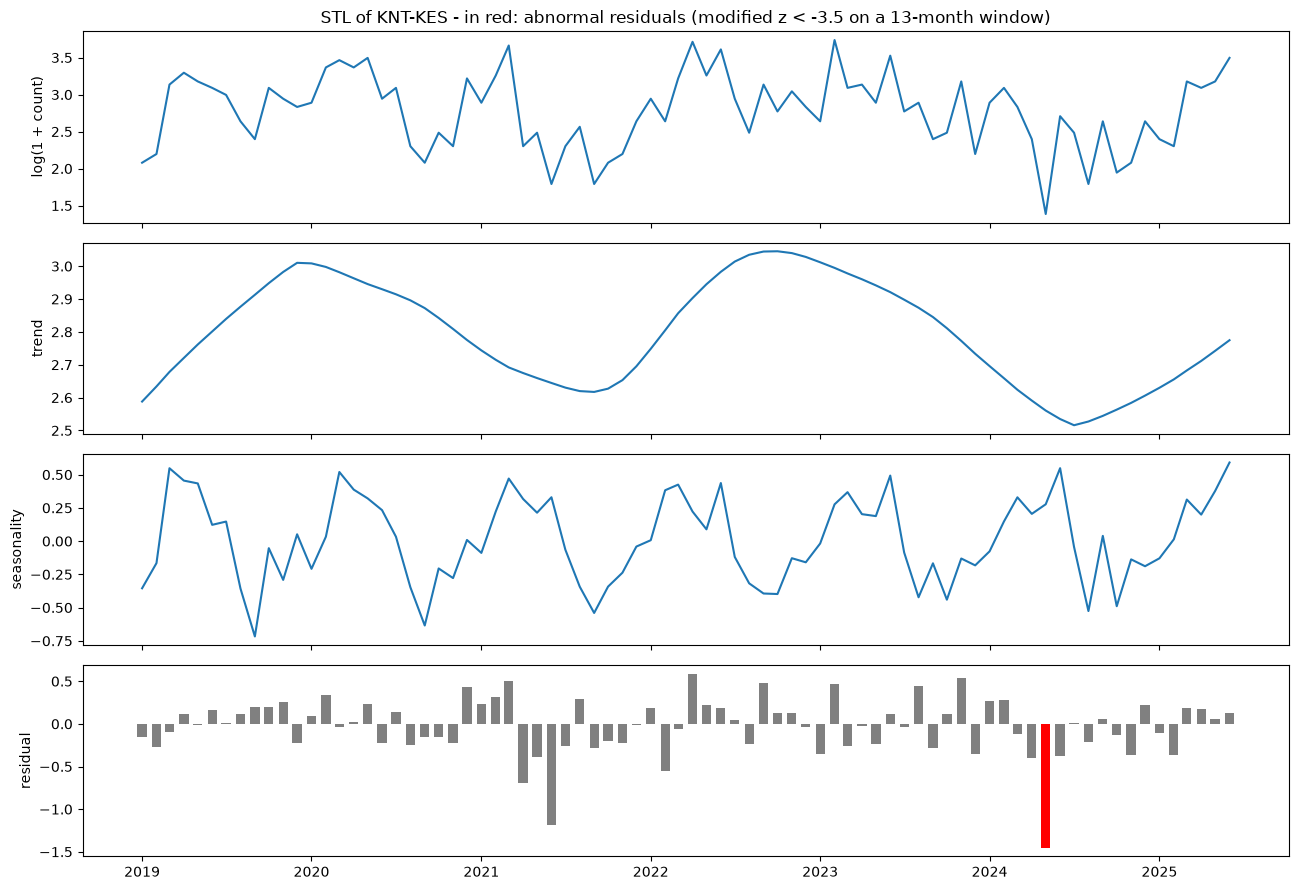

Abnormal months at KNT-KES: {Timestamp('2024-05-01 00:00:00'): -3.7}


In [68]:
# STL (robust LOESS decomposition) applied to KNT-KES, on the log of the counts
kes_log_series = np.log1p(eco[eco["site_code"] == "KNT-KES"].set_index("reporting_month")["observed_bat_count"]).asfreq("MS")
stl_kes = STL(kes_log_series, period=12, robust=True).fit()

# Rolling window (slide 20): each residual is compared with the residuals of [t - 6 months ; t + 6 months]
window = stl_kes.resid.rolling(13, center=True, min_periods=7)
med_window = window.median()
mad_window = window.apply(lambda w: np.median(np.abs(w - np.median(w))), raw=True)
z_window = 0.6745 * (stl_kes.resid - med_window) / mad_window

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axes[0].plot(kes_log_series)
axes[0].set_ylabel("log(1 + count)")
axes[1].plot(stl_kes.trend)
axes[1].set_ylabel("trend")
axes[2].plot(stl_kes.seasonal)
axes[2].set_ylabel("seasonality")
axes[3].bar(stl_kes.resid.index, stl_kes.resid, width=20,
            color=np.where(z_window < -3.5, "red", "grey"))
axes[3].set_ylabel("residual")
axes[0].set_title("STL of KNT-KES - in red: abnormal residuals (modified z < -3.5 on a 13-month window)")
plt.tight_layout()
plt.show()
print("Abnormal months at KNT-KES:", z_window[z_window < -3.5].round(1).to_dict())

**Result for KNT-KES.** Once the season and the trend are removed, the rolling window flags **only one month out of 78: May 2024** (z = −3.7, with 3 bats). The method therefore finds, **without knowing what to look for**, the incident described in the April 2024 field report.

Spring 2021, spotted in part 2, does not reach this threshold, because the drop is more spread out in time. It does stand out, however, with the method of part 7.2 (June 2021, z = −3.4).

## 7.2 The same method on the 64 sites

We apply the STL to each site and standardise its residual. We also compute a simpler indicator to read, the **seasonal gap**: the logarithm of the count of the month, minus the usual value of the **same site** for the **same month of the year** (the median over the seven years). A gap of −0.7 means about twice fewer bats than usual at this period (e^−0.7 ≈ 0.5).

Months flagged with the modified z (MAD) < -3.5: 360 (7.2%)
Months flagged with the z (standard deviation) < -3: 81 (1.6%)


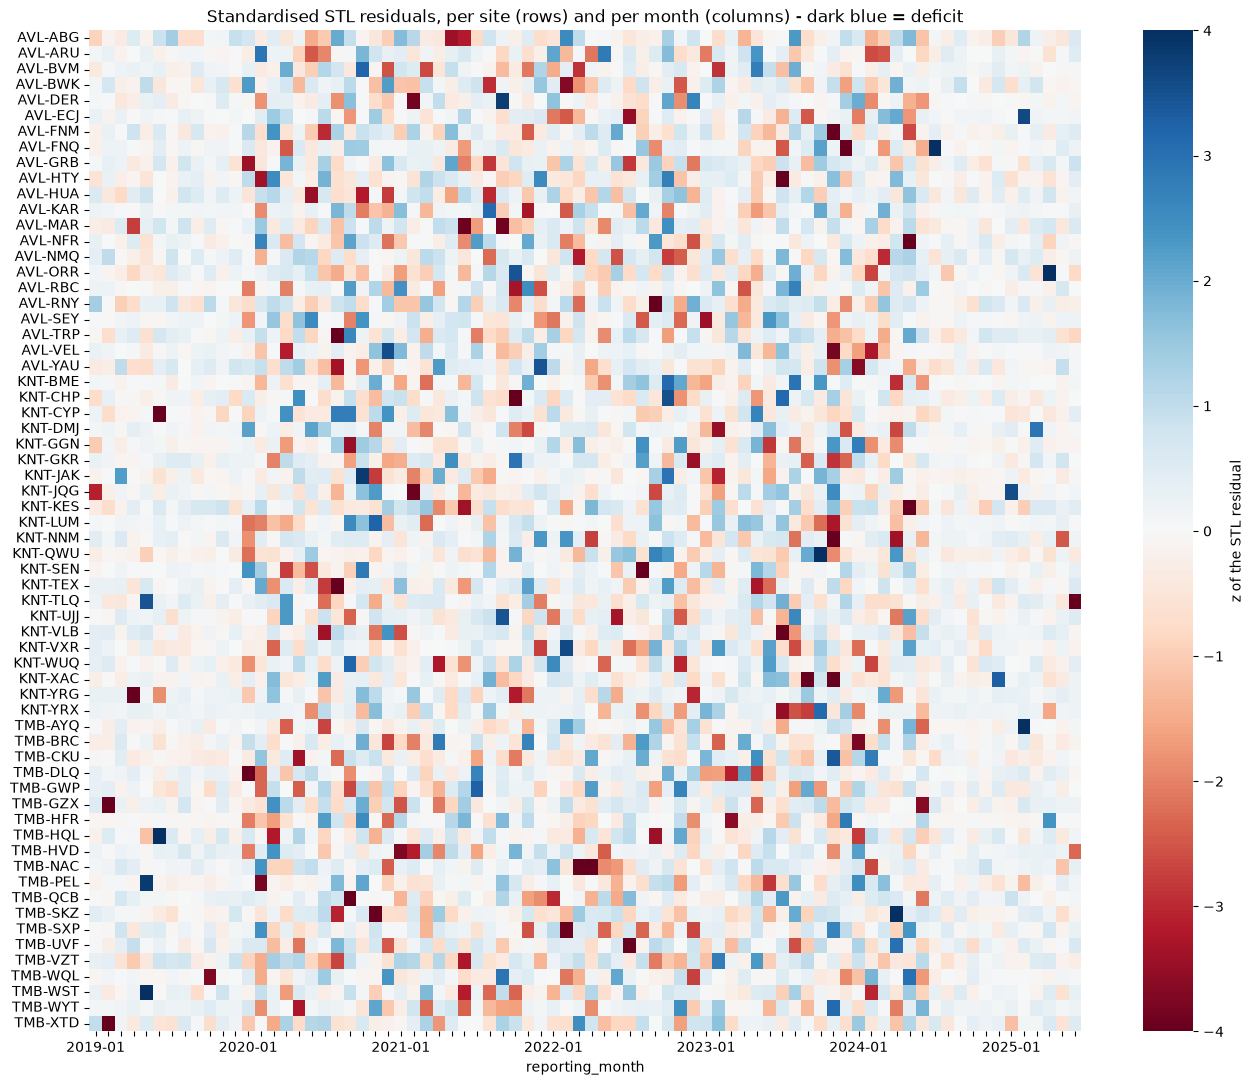

In [69]:
log_count = np.log1p(eco["observed_bat_count"])
eco["seasonal_gap"] = log_count - log_count.groupby([eco["site_code"], eco["calendar_month"]]).transform("median")

residuals = []
for plot_site, group in eco.groupby("site_code"):
    s = np.log1p(group.set_index("reporting_month")["observed_bat_count"]).asfreq("MS")
    residuals.append(STL(s, period=12, robust=True).fit().resid.rename(plot_site))
residuals = pd.concat(residuals, axis=1)

# Choice of the residual standardisation: the robust STL fits the "normal" months very tightly,
# so that the MAD of the residuals is tiny and the modified z-score flags far too many months.
z_mad = 0.6745 * (residuals - residuals.median()) / (residuals - residuals.median()).abs().median()
z_stl = (residuals - residuals.mean()) / residuals.std()
n_months = residuals.size
print(f"Months flagged with the modified z (MAD) < -3.5: {(z_mad < -3.5).sum().sum()} ({100 * (z_mad < -3.5).sum().sum() / n_months:.1f}%)")
print(f"Months flagged with the z (standard deviation) < -3: {(z_stl < -3).sum().sum()} ({100 * (z_stl < -3).sum().sum() / n_months:.1f}%)")
eco = eco.merge(z_stl.stack().rename("z_stl").reset_index().rename(columns={"level_1": "site_code"}),
                on=["reporting_month", "site_code"], how="left")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(z_stl.T.clip(-4, 4), cmap="RdBu", center=0, ax=ax, cbar_kws={"label": "z of the STL residual"},
            xticklabels=[d.strftime("%Y-%m") if d.month == 1 else "" for d in z_stl.index])
ax.set_title("Standardised STL residuals, per site (rows) and per month (columns) - dark blue = deficit")
plt.show()

We keep the months whose standardised residual is below −3, then we remove those where the measurement was doubtful (uptime below 80%, fault or survey of limited quality).

In [70]:
deficits = eco[eco["z_stl"] < -3].copy()
print("Months in deficit (STL z < -3):", len(deficits), "of which", deficits["measurement_issue"].sum(),
      "with a measurement problem (uptime < 80, fault or limited survey)")
retained_deficits = deficits[~deficits["measurement_issue"]]
print("Deficits retained (reliable measurement):", len(retained_deficits), "over", retained_deficits["site_code"].nunique(), "sites")
print("\nMost affected sites:")
print(retained_deficits["site_code"].value_counts().head(10))
retained_deficits.sort_values("z_stl")[["site_code", "reporting_month", "observed_bat_count", "z_stl",
                                       "seasonal_gap", "uptime_pct", "survey_quality"]].head(20).round(2)

Months in deficit (STL z < -3): 81 of which 9 with a measurement problem (uptime < 80, fault or limited survey)
Deficits retained (reliable measurement): 72 over 49 sites

Most affected sites:
site_code
AVL-HUA    3
AVL-VEL    3
KNT-YRG    3
AVL-ABG    2
AVL-YAU    2
KNT-JQG    2
KNT-KES    2
KNT-NNM    2
KNT-TEX    2
KNT-VLB    2
Name: count, dtype: int64


,site_code,reporting_month,observed_bat_count,z_stl,seasonal_gap,uptime_pct,survey_quality
3018,KNT-VLB,2023-07-01,1.0,-5.52,-2.08,96.5,acceptable
4310,TMB-QCB,2020-09-01,1.0,-5.46,-1.83,90.3,high
4915,TMB-XTD,2019-02-01,3.0,-5.16,-1.18,91.4,high
2885,KNT-TLQ,2025-06-01,12.0,-5.12,-0.65,88.9,high
2695,KNT-SEN,2022-08-01,1.0,-5.06,-1.79,80.8,acceptable
1877,KNT-CYP,2019-06-01,14.0,-5.02,-0.76,93.3,acceptable
4566,TMB-UVF,2022-07-01,1.0,-4.79,-1.70,92.2,acceptable
1501,AVL-TRP,2020-08-01,2.0,-4.70,-1.14,88.6,acceptable
1370,AVL-RNY,2022-09-01,4.0,-4.48,-0.90,94.7,acceptable
3279,KNT-YRG,2019-04-01,1.0,-4.37,-1.25,94.9,acceptable


**Results on the 64 sites.**

- **Why the standard deviation and not the MAD?** The STL fits the ordinary months very closely, so the MAD of the residuals is tiny. With the modified z-score, 7.2% of the months would be "abnormal", far too many. We therefore standardise with the standard deviation, with a threshold of −3: **81 months in deficit, i.e. 1.6%**.
- **9 of these months** have a measurement problem and are set aside. There remain **72 reliable deficits, spread over 49 sites**, and no site has more than 3.
- **No common event**: on the heatmap, the strong deficits are scattered. No month sees many sites drop at the same time. These deficits therefore do not come from a general climatic event: they are **local** events.

KNT-KES appears there with May 2024 (z = −4.2) and June 2021 (−3.4). But out of 4,992 surveys, part of these 72 deficits is just chance. To know which ones have a cause, we need information **external** to the counts: this is the object of parts 8 to 10.

**Clustering the series.** The 64 series cover the same 78 months. We standardise each one, to compare their shape and not their level, then we group them with a k-means.

Missing values in the series matrix: 0


Silhouette per k: {2: 0.088, 3: 0.032, 4: 0.024, 5: 0.02, 6: 0.031, 7: 0.019} -> k = 2


series_group,0,1
region,,
Eastern Avelora Agricultural Cluster,16,6
Kintara Karst Cluster,21,1
Tembara Coastal Cluster,7,13


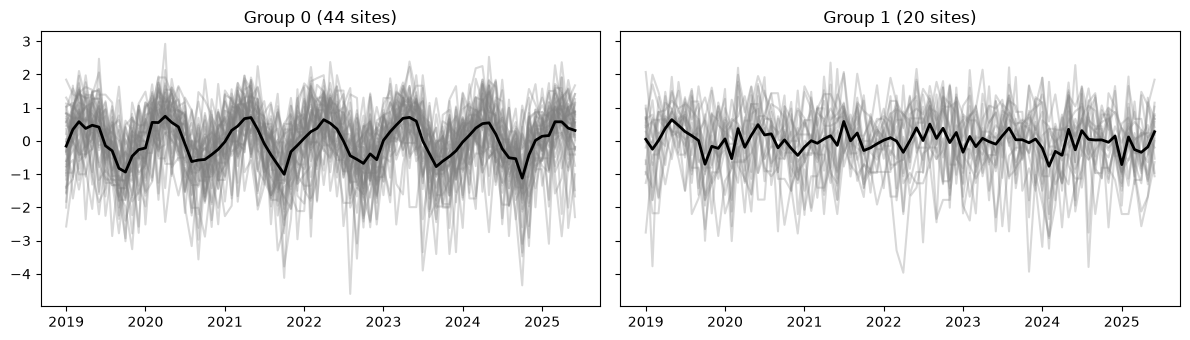

Mean seasonal profile (z) of each group, per calendar month:


reporting_month,1,2,3,4,5,6,7,8,9,10,11,12
series_group,,,,,,,,,,,,
0,-0.03,0.30,0.48,0.60,0.56,0.38,-0.09,-0.45,-0.66,-0.82,-0.41,-0.25
1,-0.19,-0.17,-0.06,-0.11,0.16,0.16,0.25,0.22,0.03,-0.08,-0.12,-0.05


In [71]:
# Cluster the time series: they are aligned (same 78 months for each site),
# so each series can be treated as a vector (slide 18); time warping (DTW) is not needed.
series = eco.pivot(index="site_code", columns="reporting_month", values="observed_bat_count")
series_z = np.log1p(series)
series_z = series_z.sub(series_z.mean(axis=1), axis=0).div(series_z.std(axis=1), axis=0)
print("Missing values in the series matrix:", int(series_z.isna().sum().sum()))

sil_series = {k: silhouette_score(series_z, KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(series_z))
              for k in range(2, 8)}
k_series = max(sil_series, key=sil_series.get)
print("Silhouette per k:", {k: round(v, 3) for k, v in sil_series.items()}, "-> k =", k_series)
series_groups = pd.Series(KMeans(n_clusters=k_series, n_init=20, random_state=0).fit_predict(series_z),
                           index=series_z.index, name="series_group")
display(pd.crosstab(site_profiles["region"], series_groups))

fig, axes = plt.subplots(1, k_series, figsize=(6 * k_series, 3.5), sharey=True)
for g, ax in zip(range(k_series), np.atleast_1d(axes)):
    members = series_z[series_groups == g]
    ax.plot(members.columns, members.T.values, color="grey", alpha=0.3)
    ax.plot(members.columns, members.mean(), color="black", lw=2)
    ax.set_title(f"Group {g} ({len(members)} sites)")
plt.tight_layout()
plt.show()

mean_profile = series_z.T.groupby(series_z.columns.month).mean().T.groupby(series_groups).mean()
print("Mean seasonal profile (z) of each group, per calendar month:")
mean_profile.round(2)

**Result.** The silhouette is low (0.09 for k = 2), but the two groups make sense:

- **Group 0** (44 sites: 21 in Kintara, 16 in Avelora, 7 in Tembara): it follows the main cycle, with a peak from March to May and a trough in September-October.
- **Group 1** (20 sites, 13 of them in Tembara): its cycle is weaker and **shifted**, with a maximum in July-August.

The coastal region of Tembara therefore has **its own season**, which the average of all the sites was hiding. This is one more reason to compute the seasonal gap **site by site and month by month**, rather than with a common calendar.

## 7.3 Space: map, neighbours and regions

Each site has coordinates (latitude, longitude). To measure the distance between two points on Earth, we use the **Haversine** distance, which takes into account the curvature of the globe. A Euclidean distance on degrees would be wrong.

Distances between region centres (km):


region,Eastern Avelora Agricultural Cluster,Kintara Karst Cluster,Tembara Coastal Cluster
region,,,
Eastern Avelora Agricultural Cluster,0.0,1218.0,658.0
Kintara Karst Cluster,1218.0,0.0,933.0
Tembara Coastal Cluster,658.0,933.0,0.0


Median distance from a site to its nearest neighbour (km): 6.6


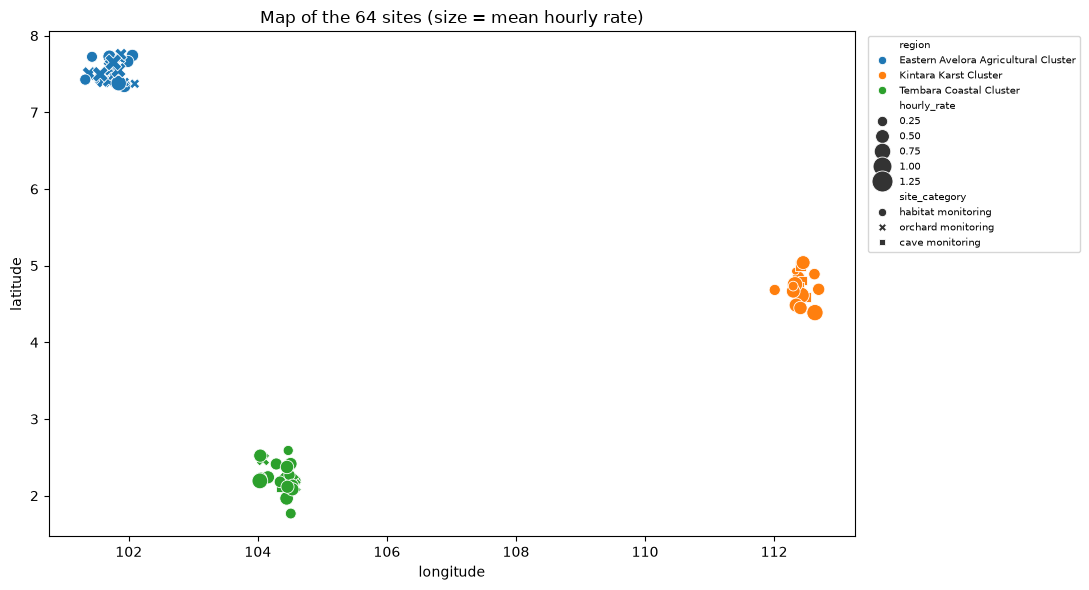

In [72]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

coords = site_profiles[["latitude", "longitude"]]
D_km = pd.DataFrame(haversine_km(coords["latitude"].values[:, None], coords["longitude"].values[:, None],
                                 coords["latitude"].values[None, :], coords["longitude"].values[None, :]),
                    index=coords.index, columns=coords.index)
region_centers = site_profiles.groupby("region")[["latitude", "longitude"]].mean()
print("Distances between region centres (km):")
display(pd.DataFrame(haversine_km(region_centers["latitude"].values[:, None], region_centers["longitude"].values[:, None],
                                  region_centers["latitude"].values[None, :], region_centers["longitude"].values[None, :]),
                     index=region_centers.index, columns=region_centers.index).round(0))
print("Median distance from a site to its nearest neighbour (km):",
      round(float(np.median(np.sort(D_km.values, axis=1)[:, 1])), 1))

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=site_profiles, x="longitude", y="latitude", hue="region", style="site_category",
                size="hourly_rate", sizes=(30, 250), ax=ax)
ax.set_title("Map of the 64 sites (size = mean hourly rate)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

We map the **mean seasonal gap since April 2024** of each site. To see the zones better, we add a **Voronoi tessellation**: each site receives the zone of the points to which it is the closest.

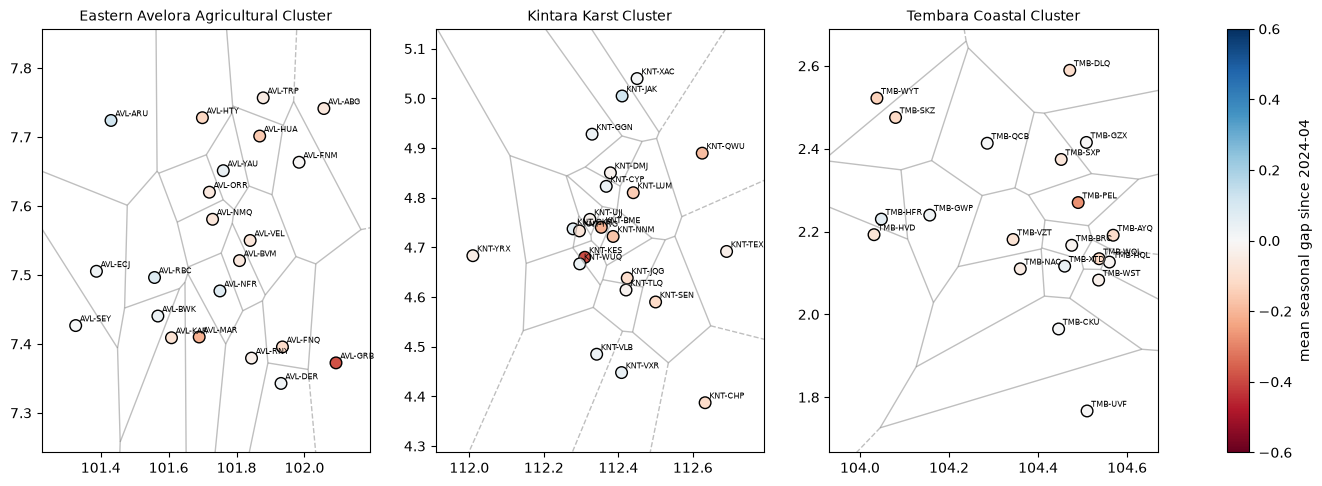

In [73]:
# Variable of interest for what follows: mean seasonal gap since April 2024 (period following the documented incident)
site_profiles["gap_post_2024"] = eco[eco["reporting_month"] >= "2024-04-01"].groupby("site_code")["seasonal_gap"].mean()

# Voronoi tessellation per region (slide 8): each site receives the zone of the points closest to it
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
norm = plt.Normalize(-0.6, 0.6)
for ax, (region, group) in zip(axes, site_profiles.groupby("region")):
    pts = group[["longitude", "latitude"]].values
    voronoi_plot_2d(Voronoi(pts), ax=ax, show_points=False, show_vertices=False, line_colors="grey", line_alpha=0.5)
    sc = ax.scatter(pts[:, 0], pts[:, 1], c=group["gap_post_2024"], cmap="RdBu", norm=norm, s=70, edgecolors="black")
    for (lon, lat), label in zip(pts, group.index):
        ax.annotate(label, (lon, lat), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ax.set_xlim(pts[:, 0].min() - 0.1, pts[:, 0].max() + 0.1)
    ax.set_ylim(pts[:, 1].min() - 0.1, pts[:, 1].max() + 0.1)
    ax.set_title(region, fontsize=10)
fig.colorbar(sc, ax=axes, label="mean seasonal gap since 2024-04")
plt.show()

Do close sites look alike? To find out, we define the neighbours of each site (its 4 nearest) and compute **Moran's I**: it is positive if the neighbours look alike, and close to 0 otherwise. To know whether the result is significant, we compare it with 999 draws where the values are shuffled at random between the sites.

In [74]:
# Neighbourhood matrix: the 4 nearest neighbours (Haversine), made symmetric
k_neighbors = 4
W = np.zeros(D_km.shape)
for i, row in enumerate(D_km.values):
    W[i, np.argsort(row)[1:k_neighbors + 1]] = 1
W = np.maximum(W, W.T)
print("Links between different regions:",
      int(sum(W[i, j] for i in range(len(W)) for j in range(len(W))
              if site_profiles["region"].iloc[i] != site_profiles["region"].iloc[j]) / 2))


def moran_I(y, W):
    zc = y - y.mean()
    return len(y) / W.sum() * (zc @ W @ zc) / (zc @ zc)


def moran_permutation(y, W, n=999, seed=0):
    rng = np.random.default_rng(seed)
    obs = moran_I(y, W)
    sims = np.array([moran_I(rng.permutation(y), W) for _ in range(n)])
    p = (1 + (sims >= obs).sum()) / (n + 1) if obs > sims.mean() else (1 + (sims <= obs).sum()) / (n + 1)
    return obs, p


rows = []
for var in ["hourly_rate", "disturbance", "pesticide", "vegetation", "gap_post_2024"]:
    y = site_profiles[var].values.astype(float)
    I_glob, p_glob = moran_permutation(y, W)
    I_intra = []
    for region in site_profiles["region"].unique():
        m = (site_profiles["region"] == region).values
        I_intra.append(moran_I(y[m], W[np.ix_(m, m)]))
    rows.append({"variable": var, "Moran's I (64 sites)": I_glob, "p (permutations)": p_glob,
                   "mean intra-region I": np.mean(I_intra)})
pd.DataFrame(rows).set_index("variable").round(3)

Links between different regions: 0


,Moran's I (64 sites),p (permutations),mean intra-region I
variable,,,
hourly_rate,-0.074,0.201,-0.086
disturbance,-0.071,0.238,-0.098
pesticide,0.100,0.059,0.008
vegetation,0.029,0.244,0.004
gap_post_2024,0.046,0.167,0.032


Moran's I gives a global answer. The **LISA** indicators give the same information site by site, to spot possible "hot spots" or "cold spots".

In [75]:
def lisa(y, W, n=999, seed=0, seuil=0.05):
    """Local indicators of spatial association (local Moran's I) with conditional permutations."""
    rng = np.random.default_rng(seed)
    Wn = W / W.sum(axis=1, keepdims=True)
    zs = (y - y.mean()) / y.std()
    lag_value = Wn @ zs
    I_local = zs * lag_value
    p = np.empty(len(y))
    for i in range(len(y)):
        neighbors_i = np.flatnonzero(W[i])
        others = np.delete(zs, i)
        sims = zs[i] * np.array([rng.choice(others, len(neighbors_i), replace=False).mean() for _ in range(n)])
        p[i] = (1 + (np.abs(sims) >= abs(I_local[i])).sum()) / (n + 1)
    quadrant = np.select([(zs > 0) & (lag_value > 0), (zs < 0) & (lag_value < 0), (zs > 0) & (lag_value < 0)],
                         ["HH (hot spot)", "LL (cold spot)", "HL"], "LH")
    return pd.DataFrame({"z": zs, "decalage_spatial": lag_value, "I_local": I_local, "p": p,
                         "quadrant": np.where(p < seuil, quadrant, "not significant")})

lisa_post = lisa(site_profiles["gap_post_2024"].values, W).set_index(site_profiles.index)
print(lisa_post["quadrant"].value_counts())
lisa_post[lisa_post["quadrant"] != "not significant"].sort_values("z").round(3)

quadrant
not significant    62
HH (hot spot)       1
LL (cold spot)      1
Name: count, dtype: int64


,z,decalage_spatial,I_local,p,quadrant
site_code,,,,,
KNT-NNM,-1.18,-0.819,0.967,0.007,LL (cold spot)
AVL-ECJ,0.78,1.112,0.867,0.032,HH (hot spot)


Finally, the **regionalisation** groups sites that are both neighbouring and similar: it is a Ward HAC where only neighbouring sites can be merged.

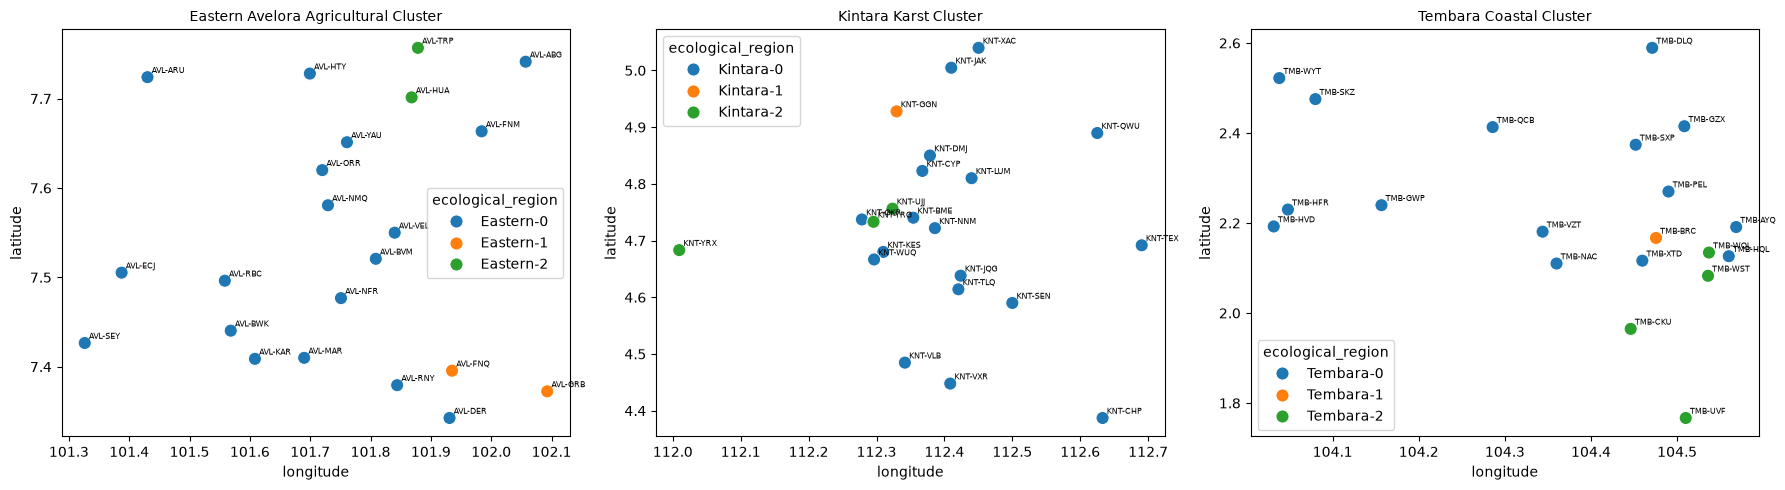

,hourly_rate,comparison_species,seasonal_amplitude,temperature,rain,humidity,vegetation,disturbance,pesticide,elevation_m
ecological_region,,,,,,,,,,
Eastern-0,0.2,0.0,-0.1,0.3,-0.4,-0.5,0.2,-0.3,0.2,0.0
Eastern-1,-1.2,-2.3,-0.7,0.5,0.4,0.0,-1.7,1.6,1.7,0.9
Eastern-2,-0.6,-1.9,0.2,0.1,0.8,0.4,-1.9,1.6,0.5,0.2
Kintara-0,0.1,0.4,0.6,-0.9,-0.1,0.3,0.4,-0.1,-0.1,0.4
Kintara-1,-1.9,-1.8,-2.0,0.6,-0.9,1.2,-2.6,2.8,-1.5,0.4
Kintara-2,-0.4,-1.5,0.4,-1.2,0.8,0.2,-1.9,0.1,0.0,0.2
Tembara-0,-0.1,0.4,-0.4,0.4,0.6,0.4,0.5,-0.2,-0.0,-0.7
Tembara-1,4.7,1.3,2.1,1.3,-0.1,-1.8,0.8,-0.7,-1.3,0.8
Tembara-2,-0.3,-0.1,-0.7,1.5,-0.6,-0.7,-0.6,0.1,-1.2,-0.4


In [76]:
# Regionalisation (slide 7): Ward HAC constrained by spatial contiguity, region by region
site_profiles["ecological_region"] = ""
for region, group in site_profiles.groupby("region"):
    m = (site_profiles["region"] == region).values
    contiguous = AgglomerativeClustering(n_clusters=3, linkage="ward", connectivity=W[np.ix_(m, m)])
    labels = contiguous.fit_predict(X_std.loc[group.index])
    site_profiles.loc[group.index, "ecological_region"] = [f"{region.split()[0]}-{l}" for l in labels]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (region, group) in zip(axes, site_profiles.groupby("region")):
    sns.scatterplot(data=group, x="longitude", y="latitude", hue="ecological_region", s=90, ax=ax)
    for label, r in group.iterrows():
        ax.annotate(label, (r["longitude"], r["latitude"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ax.set_title(region, fontsize=10)
plt.tight_layout()
plt.show()
display(X_std.groupby(site_profiles["ecological_region"]).mean().round(1))

**Results.**

- The **three regions are 650 to 1,200 km apart**, whereas a site is only 6.6 km on median from its nearest neighbour. The neighbours of a site are therefore always in its region.
- **No variable is spatially autocorrelated** (Moran's I, 5% threshold):

  | Variable | Moran's I | p |
  |---|---|---|
  | hourly rate | −0.07 | 0.20 |
  | disturbance | −0.07 | 0.24 |
  | seasonal gap since April 2024 | 0.05 | 0.17 |
  | pesticides | 0.10 | 0.06 (borderline) |

  Neighbouring sites do not look more alike than sites taken at random.
- **LISA**: only 2 sites out of 64 are significant (KNT-NNM, cold spot, and AVL-ECJ, hot spot). This is what chance alone produces with 64 tests (about 3). **There is no decline zone.**
- **Regionalisation**: in each region, it isolates a small degraded zone (less vegetation, more disturbance) and, on the coast of Tembara, a very active zone around TMB-BRC. This split says more than the large administrative regions, which mix these habitats.

**Conclusion.** The decline observed since 2024 **is not a spot on the map**. A regional pollution or drought would also affect the neighbouring sites. Here, it hits specific sites far from each other: the cause is probably **specific to these sites**, i.e. linked to what happens there.

# 8. Read the field reports (course 6)

`environmental_field_reports` contains 30 reports: information on the document (date, type, author, organisation, site) and a free text in English. To analyse these texts, we follow the preparation of course 6: lowercase, splitting into words, removal of punctuation and digits, then of stop words (*the*, *and*, *of*…).

**Assumed choice**: we do not reduce the words to their base form (lemmatisation), and we do not identify their grammatical nature. The corpus is short (30 texts) and written in a very repetitive technical English: these steps would only have merged a few plurals, without changing the conclusions.

Encoding: non-ASCII characters present: 0 texts
Length of the texts (words): {'count': 30.0, 'mean': 171.0, 'std': 59.0, 'min': 100.0, '25%': 130.0, '50%': 161.0, '75%': 190.0, 'max': 288.0}


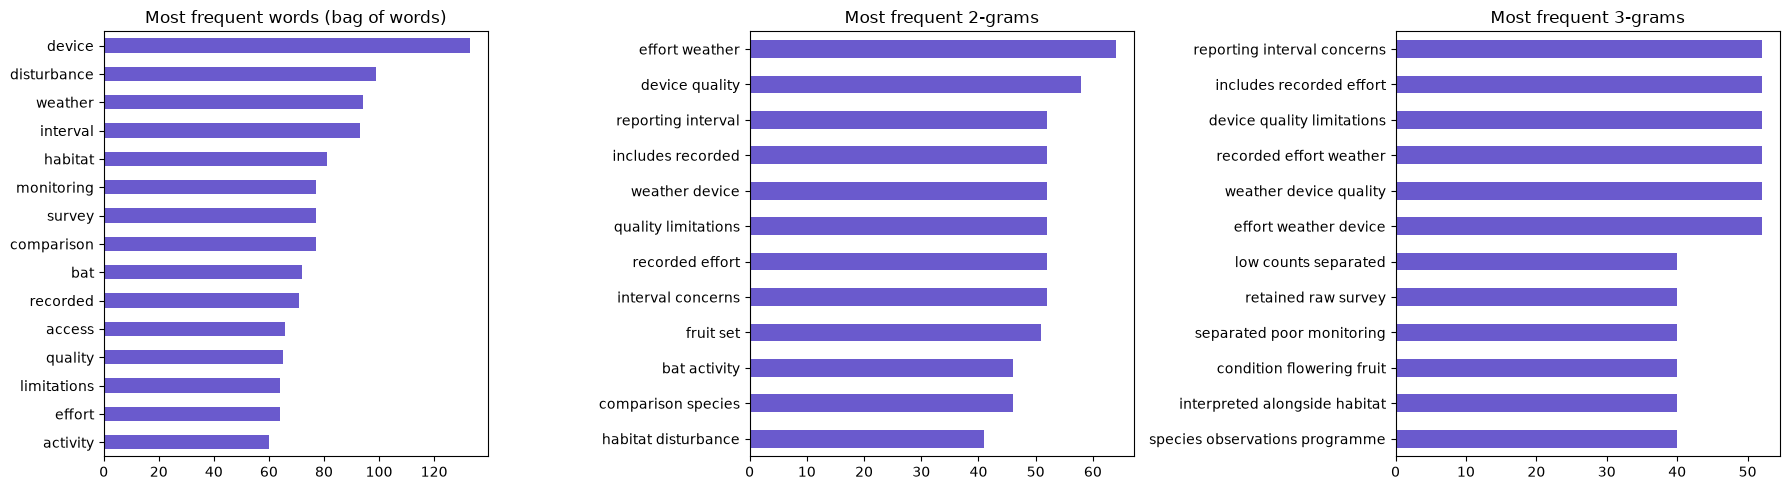

In [77]:
reports = dataframes["environmental_field_reports"].sort_values("document_date").reset_index(drop=True)
print("Encoding: non-ASCII characters present:", reports["text"].str.contains(r"[^\x00-\x7F]").sum(), "texts")
print("Length of the texts (words):", reports["text"].str.split().str.len().describe().round(0).to_dict())


def preprocess(text_):
    text_ = text_.lower()
    text_ = re.sub(r"[^a-z\s]", " ", text_)            # punctuation, digits and codes removed
    return [t for t in text_.split() if t not in ENGLISH_STOP_WORDS and len(t) > 2]

reports["tokens"] = reports["text"].apply(preprocess)
frequencies = Counter(t for tokens in reports["tokens"] for t in tokens)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pd.Series(dict(frequencies.most_common(15))).sort_values().plot.barh(ax=axes[0], color="slateblue")
axes[0].set_title("Most frequent words (bag of words)")
for ax, n in zip(axes[1:], [2, 3]):
    cv = CountVectorizer(ngram_range=(n, n), stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    counts = pd.Series(np.asarray(cv.fit_transform(reports["text"]).sum(axis=0)).ravel(),
                        index=cv.get_feature_names_out())
    counts.sort_values().tail(12).plot.barh(ax=ax, color="slateblue")
    ax.set_title(f"Most frequent {n}-grams")
plt.tight_layout()
plt.show()

**Word frequencies.** The most frequent words (*device, disturbance, weather, habitat, monitoring*…) and above all the groups of three words (*reporting interval concerns*, *device quality limitations*…, each 52 times) come from standard sentences repeated in almost all the reports. Counting words therefore only shows the **common vocabulary**. To find what is **particular** about a report, other tools are needed: the detection of repeated sentences and the TF-IDF.

**Spot the standard sentences.** A sentence is considered to be drawn from a template if **another** report contains an almost identical sentence, with at least 60% of words in common (Jaccard index ≥ 0.6). For each report, we compute the share of its sentences drawn from a template.

In [78]:
# Spot the "template": a sentence is considered a model if ANOTHER report contains a sentence
# almost identical (Jaccard index >= 0.6 on the words: only the site or survey codes change).
def sentences(text_):
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+|\n+", text_) if len(p.strip()) > 25]

all_sentences = [(i, p, set(re.findall(r"[a-z]+", p.lower())))
                  for i, text_ in enumerate(reports["text"]) for p in sentences(text_)]


def max_similarity_elsewhere(i, words):
    return max(len(words & m2) / len(words | m2) for j, _, m2 in all_sentences if j != i)


sentence_table = pd.DataFrame({"doc": [i for i, _, _ in all_sentences], "phrase": [p for _, p, _ in all_sentences],
                              "jaccard_max_autres": [max_similarity_elsewhere(i, m) for i, _, m in all_sentences]})
sentence_table["template"] = sentence_table["jaccard_max_autres"] >= 0.6
reports["template_share"] = sentence_table.groupby("doc")["template"].mean()
reports["own_sentences"] = sentence_table[~sentence_table["template"]].groupby("doc")["phrase"].apply(list)

print("Sentences analysed:", len(sentence_table), "| share drawn from a template:", round(sentence_table["template"].mean(), 3))
reports.sort_values("template_share")[["document_id", "site_code", "document_date", "document_type",
                                      "author_organization", "template_share"]].head(8).round(2)

Sentences analysed: 385 | share drawn from a template: 0.912


,document_id,site_code,document_date,document_type,author_organization,template_share
23,EFR-510088,KNT-KES,2024-04-02,ecological_incident_report,Horizon Field Research Cooperative,0.00
3,EFR-510082,KNT-JAK,2019-04-01,field_observation,Pollinator Justice Network,0.86
6,EFR-510122,KNT-QWU,2019-12-05,cave_access_note,Avelora Agricultural Resilience Agency,0.90
2,EFR-510011,KNT-DMJ,2018-09-11,cave_access_note,Pollinator Justice Network,0.90
15,EFR-510008,KNT-QWU,2022-05-12,cave_access_note,Threshold Earth Observatory,0.90
24,EFR-510109,KNT-GGN,2024-07-25,cave_access_note,Belen Agro-Industries,0.90
18,EFR-510032,KNT-DMJ,2023-04-04,cave_access_note,Threshold Earth Observatory,0.90
11,EFR-510098,KNT-GGN,2021-02-18,cave_access_note,Horizon Field Research Cooperative,0.90


For each report, we display the sentences that come from no template, starting with the most original reports.

In [79]:
for _, r in reports[reports["own_sentences"].notna()].sort_values("template_share").iterrows():
    print(f"=== {r['document_id']} | {r['site_code']} | {r['document_date'].date()} | {r['document_type']} "
          f"| {r['author_organization']} | part de template = {r['template_share']:.2f}")
    for p in r["own_sentences"]:
        print("   -", p)

=== EFR-510088 | KNT-KES | 2024-04-02 | ecological_incident_report | Horizon Field Research Cooperative | part de template = 0.00
   - A post-access inspection was conducted at KNT-KES after the March access window.
   - The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.
   - Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault.
   - Weather interference was moderate and does not account for the full change.
   - Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team.
   - No dead animals were found.
   - The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.
   - The entrance was photographed, the cut mate

**Reports written almost entirely from templates.** 91% of the 385 sentences have a near-copy in another report. The sentences specific to a report are almost always limited to the name of the site and to the subject of the month. Three reports stand out:

1. **EFR-510088 (KNT-KES, 2 April 2024, Horizon Field Research Cooperative)**: 0% of standard sentences. It is the **only** entirely original text. It describes:
   - **traces of handling** near a secondary entrance;
   - two **cut pieces of restraint cord**;
   - **disturbed sediments** on a path that the monitoring team does not use;
   - a drop in the activity of *Eonycteris spelaea*, whereas the device was working.

   It specifies that the access was authorised "although the declared purpose was routine maintenance", and asks to **keep the access file**.
2. **EFR-510082 (KNT-JAK, 2019)** adds a paragraph about an **authorised collection of bats** to ring them, before releasing them.
3. **EFR-510026 (KNT-CHP, 2021)** mentions an authorised collection on a neighbouring site.

Elsewhere, the same sentence comes back in 23 reports: the report "does not turn an unusual count into an accusation of organised removal".

**TF-IDF.** TF-IDF gives each word a high weight if it is frequent in a report but rare in the others: it brings out the vocabulary specific to each text. We then compare the reports two by two with the **cosine similarity**, which is 1 for two identical texts and 0 for two texts with no word in common.

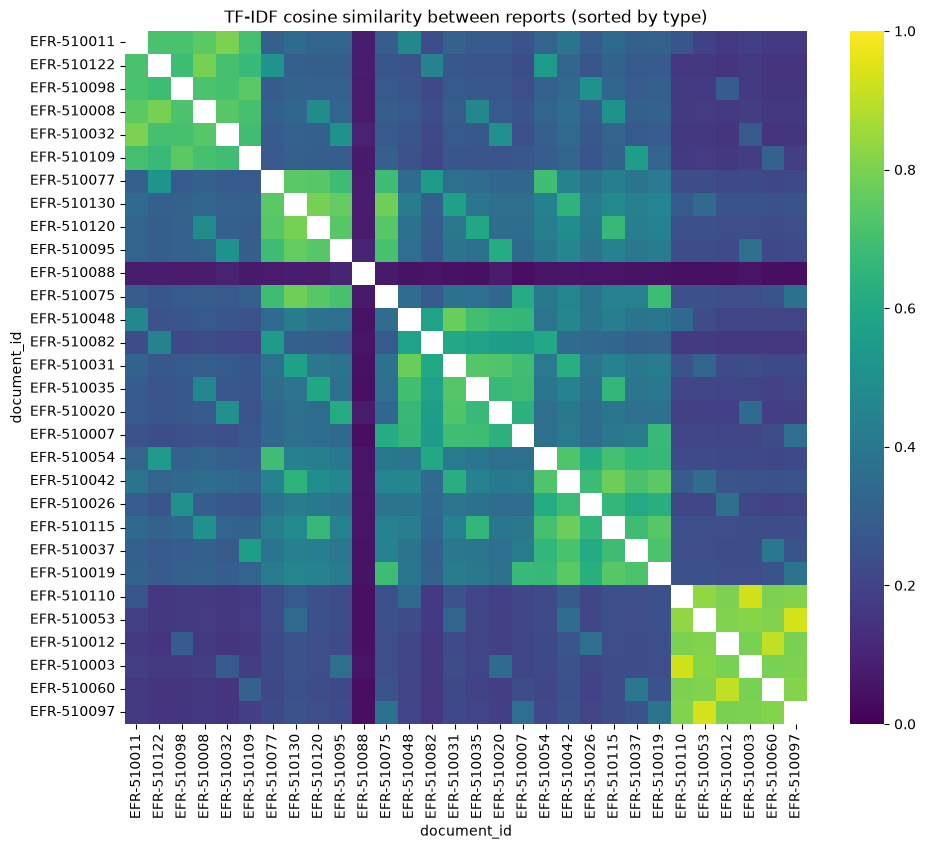

EFR-510088 - mean similarity to the others: 0.06 | main TF-IDF terms: conducted, cut, post, material, post access, record, handling, access, inspection, station
EFR-510060 - mean similarity to the others: 0.32 | main TF-IDF terms: device, review, vxr, knt vxr, dev kntvxr, kntvxr, kntvxr knt, vxr interval, cave microclimate, concerns cave
EFR-510012 - mean similarity to the others: 0.32 | main TF-IDF terms: device, vxr, kntvxr knt, dev kntvxr, kntvxr, knt vxr, vxr interval, orchard pollination, survey includes, concerns orchard


In [80]:
tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", ngram_range=(1, 2))
M_tfidf = tfidf.fit_transform(reports["text"])
similarities = cosine_similarity(M_tfidf)
np.fill_diagonal(similarities, np.nan)
reports["max_similarity"] = np.nanmax(similarities, axis=1)
reports["mean_similarity"] = np.nanmean(similarities, axis=1)

order = reports.sort_values(["document_type", "document_date"]).index
plt.figure(figsize=(11, 9))
sns.heatmap(pd.DataFrame(similarities, index=reports["document_id"], columns=reports["document_id"]).iloc[order, order],
            cmap="viridis", vmin=0, vmax=1)
plt.title("TF-IDF cosine similarity between reports (sorted by type)")
plt.show()

vocab = tfidf.get_feature_names_out()
for doc in reports.nsmallest(3, "mean_similarity")["document_id"]:
    i = reports.index[reports["document_id"] == doc][0]
    weights = M_tfidf[i].toarray().ravel()
    print(doc, "- mean similarity to the others:", round(reports.loc[i, "mean_similarity"], 2),
          "| main TF-IDF terms:", ", ".join(vocab[np.argsort(weights)[::-1][:10]]))

**Topics.** Two methods look for the main topics of the corpus: **LSA**, which summarises the TF-IDF matrix in a few axes, and **LDA**, which describes each text as a mixture of topics. We check whether a k-means on these topics finds the 5 document types again.

In [81]:
# Topic modelling: LSA (SVD on TF-IDF) and LDA (on the counts), 5 topics
lsa = TruncatedSVD(n_components=5, random_state=0)
docs_lsa = lsa.fit_transform(M_tfidf)
cv_lda = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
M_count = cv_lda.fit_transform(reports["text"])
lda = LatentDirichletAllocation(n_components=5, random_state=0)
docs_lda = lda.fit_transform(M_count)

for label, model, terms in [("LSA", lsa, vocab), ("LDA", lda, cv_lda.get_feature_names_out())]:
    print(f"--- {label}")
    for t, weights in enumerate(model.components_):
        print(f"  topic {t}:", ", ".join(terms[np.argsort(weights)[::-1][:8]]))

reports["topic_lsa"] = docs_lsa.argmax(axis=1)
reports["topic_lda"] = docs_lda.argmax(axis=1)
reports["text_cluster"] = KMeans(n_clusters=5, n_init=20, random_state=0).fit_predict(docs_lsa)
for col in ["topic_lsa", "topic_lda", "text_cluster"]:
    print(f"ARI {col} vs document_type: {adjusted_rand_score(reports['document_type'], reports[col]):.2f}")
pd.crosstab(reports["document_type"], reports["text_cluster"])

--- LSA
  topic 0: device, disturbance, interval, weather, habitat, monitoring, access, survey
  topic 1: invalidate entire, monitoring month, invalidate, periods, period remediation, synchronization compare, fault lower, month brief
  topic 2: visit, visit retain, checks, unauthorized equipment, unauthorized, continue, conditions entrance, close
  topic 3: completed, team, wind, dusk transect, weather recorded, time field, field observation, transect reviewed
  topic 4: temporary, evidence, incident, access path, path inspection, inspection, path, access noise
--- LDA
  topic 0: incident, temporary, evidence, access, cycle, sensor, survey, reduction
  topic 1: pollination, cycle, sensor, chp, site, access, seasonal, cave
  topic 2: device, disturbance, interval, weather, habitat, comparison, survey, effort
  topic 3: access, device, weather, disturbance, recorded, bat, interval, habitat
  topic 4: device, quality, monitoring, interval, review, set, fruit, bat
ARI topic_lsa vs document

text_cluster,0,1,2,3,4
document_type,,,,,
cave_access_note,0,6,0,0,0
ecological_incident_report,0,0,0,0,6
field_observation,6,0,0,0,0
monitoring_report,0,0,6,0,0
sensor_quality_report,0,0,0,6,0


We also directly look for the reports that speak of removal, handling or a specific species.

In [82]:
# Targeted search of terms: who talks about removal, handling or a named species?
patterns = {"named species": r"\*[A-Z][a-z]+ [a-z]+\*", "removal": r"\bremoval\b", "handling": r"\bhandling\b",
          "restraint": r"\brestraint\b", "bat collection": r"bat collection", "access register": r"access register",
          "secondary entrance": r"secondary entrance"}
presences = pd.DataFrame({m: reports["text"].str.contains(p, regex=True) for m, p in patterns.items()})
presences.index = reports["document_id"]
print(presences.sum())
display(presences[presences.drop(columns="removal").any(axis=1)])
print("Mentions of \"removal\": the standard sentence is",
      repr(reports.loc[reports["text"].str.contains("removal"), "text"].str.extract(r"([^.\n]*removal[^.\n]*)")[0].iloc[0]))

named species          1
removal               24
handling               2
restraint              1
bat collection         2
access register        1
secondary entrance     1
dtype: int64


,named species,removal,handling,restraint,bat collection,access register,secondary entrance
document_id,,,,,,,
EFR-510082,False,True,False,False,True,False,False
EFR-510026,False,True,True,False,True,False,False
EFR-510088,True,True,True,True,False,True,True


Mentions of "removal": the standard sentence is 'The report does not convert an unusual count into a claim about organized removal'


Finally, we look at who signs the reports: which organisations, and how many reports each.

In [83]:
# Metadata: who writes ecological reports?
display(pd.crosstab(reports["author_organization"], reports["document_type"], margins=True))

document_type,cave_access_note,ecological_incident_report,field_observation,monitoring_report,sensor_quality_report,All
author_organization,,,,,,
Asterion Clinical Institute,0,1,0,1,0,2
Avelora Agricultural Resilience Agency,1,1,1,1,1,5
Belen Agro-Industries,1,1,0,1,1,4
Bell Conservation Survey,0,0,1,0,0,1
Horizon Field Research Cooperative,1,2,1,1,1,6
Lantern Investigative Bureau,0,0,0,1,0,1
Marot Ecological Policy Office,0,0,1,0,0,1
Pollinator Justice Network,1,0,1,0,2,4
Threshold Earth Observatory,2,1,0,1,1,5


**TF-IDF and similarity.** The reports form 5 very homogeneous blocks, one per document type. **EFR-510088 has a mean similarity of 0.06** with the other reports, versus 0.32 for the least similar report after it: it is **the anomaly of the corpus**. Its most characteristic words are *cut, post access, material, handling, inspection*.

**Topics.** A k-means on the LSA finds **exactly** the 5 document types (ARI = 1.00), and the LDA finds them partially (0.57). The content of a report is therefore entirely dictated by its type, with one exception.

**Who writes?** 10 organisations sign reports, some of them unexpected for a bat monitoring programme:

- the **Asterion Clinical Institute**, a clinical institute (2 reports);
- **Belen Agro-Industries** (4);
- the **Lantern Investigative Bureau** (1).

The Horizon Field Research Cooperative signs 6, including the only detailed report.

# 9. Graphs and processes (course 4)

## 9.1 Who observes which sites?

A simple explanation for the drops would be an **observation team** that counts badly. To test it, we build a **bipartite** graph: on one side the teams, on the other the sites, with a link between a team and each site it has followed. We then **project** it onto the sites: two sites are linked if they have a team in common.

In [84]:
teams = (dataframes["bat_surveys"].dropna(subset=["observer_team"])
           .groupby(["observer_team", "site_code"]).size().reset_index(name="survey_count"))
G_eq = nx.Graph()
G_eq.add_nodes_from(teams["observer_team"].unique(), bipartite="team")
G_eq.add_nodes_from(teams["site_code"].unique(), bipartite="site")
G_eq.add_weighted_edges_from(teams[["observer_team", "site_code", "survey_count"]].itertuples(index=False, name=None))
print(f"Bipartite graph: {G_eq.number_of_nodes()} nodes, {G_eq.number_of_edges()} links, density = {nx.density(G_eq):.3f}")
deg_eq = pd.Series(dict(G_eq.degree(teams["observer_team"].unique())), name="sites followed").sort_values()
print("Degree of the teams (number of sites followed):", deg_eq.to_dict())

G_sites = bipartite.weighted_projected_graph(G_eq, teams["site_code"].unique())
print(f"\nProjection on the sites: {G_sites.number_of_nodes()} nodes, {G_sites.number_of_edges()} links, "
      f"density = {nx.density(G_sites):.3f}, connected components = {nx.number_connected_components(G_sites)}")
print("Mean clustering coefficient:", round(nx.average_clustering(G_sites), 3))

communities = nx.community.louvain_communities(G_sites, weight="weight", seed=0)
print("Louvain:", len(communities), "communities, modularity =",
      round(nx.community.modularity(G_sites, communities, weight="weight"), 3))
community_of_site = {s: i for i, c in enumerate(communities) for s in c}
display(pd.crosstab(site_profiles["region"], pd.Series(community_of_site, name="Louvain community")))

gn = next(nx.community.girvan_newman(G_sites))
print("Girvan-Newman, 1st split:", [len(c) for c in gn], "- modularity =",
      round(nx.community.modularity(G_sites, gn), 3))

Bipartite graph: 79 nodes, 64 links, density = 0.021
Degree of the teams (number of sites followed): {'TEAM-11-1': 3, 'TEAM-11-5': 4, 'TEAM-12-3': 4, 'TEAM-13-3': 4, 'TEAM-13-2': 4, 'TEAM-13-1': 4, 'TEAM-12-5': 4, 'TEAM-12-4': 4, 'TEAM-13-5': 4, 'TEAM-13-4': 4, 'TEAM-12-2': 5, 'TEAM-11-4': 5, 'TEAM-11-2': 5, 'TEAM-12-1': 5, 'TEAM-11-3': 5}

Projection on the sites: 64 nodes, 107 links, density = 0.053, connected components = 15
Mean clustering coefficient: 1.0
Louvain: 15 communities, modularity = 0.927


Louvain community,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
region,,,,,,,,,,,,,,,
Eastern Avelora Agricultural Cluster,0,0,0,0,0,5,5,4,4,4,0,0,0,0,0
Kintara Karst Cluster,3,5,5,5,4,0,0,0,0,0,0,0,0,0,0
Tembara Coastal Cluster,0,0,0,0,0,0,0,0,0,0,4,4,4,4,4


Girvan-Newman, 1st split: [1, 2, 5, 5, 5, 4, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4] - modularity = 0.909


We look in particular at the teams of the 8 sites that will come back in what follows (including KNT-KES, KNT-LUM and KNT-SEN), then we draw the graph.

Teams that worked on the 8 historical sites of the programme:
site_code
KNT-KES    [TEAM-11-2]
KNT-LUM    [TEAM-11-3]
KNT-SEN    [TEAM-11-4]
AVL-MAR    [TEAM-12-5]
AVL-VEL    [TEAM-12-1]
AVL-ORR    [TEAM-12-2]
TMB-NAC    [TEAM-13-3]
TMB-PEL    [TEAM-13-4]
Name: observer_team, dtype: object


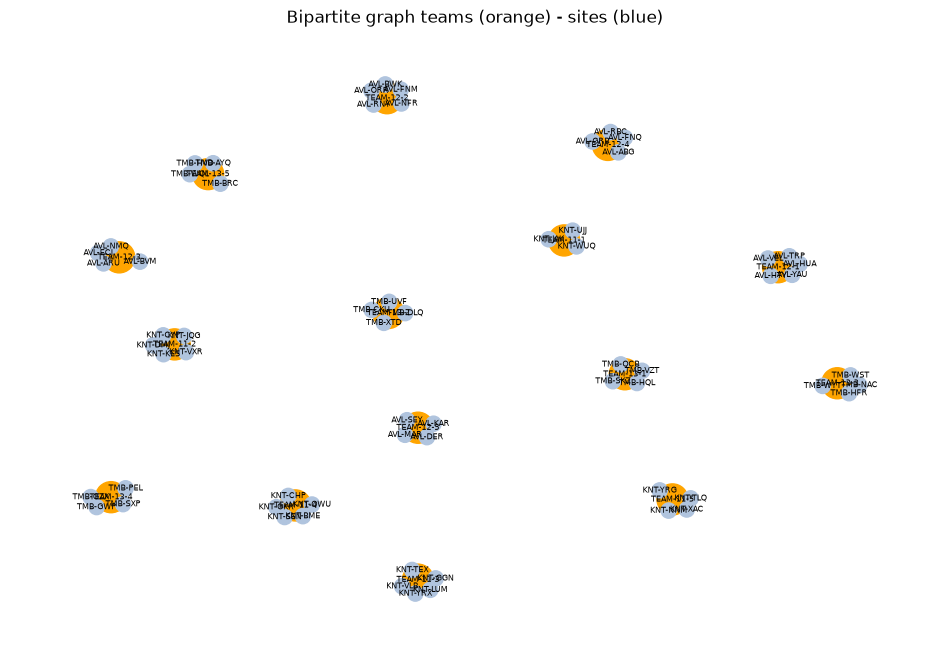

In [85]:
teams_per_site = teams.groupby("site_code")["observer_team"].apply(sorted)
core_sites = ["KNT-KES", "KNT-LUM", "KNT-SEN", "AVL-MAR", "AVL-VEL", "AVL-ORR", "TMB-NAC", "TMB-PEL"]
print("Teams that worked on the 8 historical sites of the programme:")
print(teams_per_site.loc[core_sites])

fig, ax = plt.subplots(figsize=(12, 8))
pos = nx.spring_layout(G_eq, seed=1, k=0.35)
colors = ["orange" if G_eq.nodes[n]["bipartite"] == "team" else "lightsteelblue" for n in G_eq.nodes]
nx.draw_networkx(G_eq, pos, node_color=colors, node_size=[500 if c == "orange" else 120 for c in colors],
                 font_size=6, width=0.4, ax=ax)
ax.set_title("Bipartite graph teams (orange) - sites (blue)")
ax.axis("off")
plt.show()

**Result.**

- **Each site is followed by a single team** (64 links for 64 sites), and each team follows 3 to 5 sites. The projection therefore splits into **15 separate groups**, one per team, in which all the sites are linked to each other.
- The community detection algorithms find these 15 groups: Louvain (modularity of 0.93) and Girvan-Newman (0.91). The **modularity** measures how much the links stay inside the groups; close to 1, the groups are very clear. The prefix of the teams matches the region: 11 for Kintara, 12 for Avelora, 13 for Tembara.
- The 8 highlighted sites each have **a different team**.

The drops therefore cannot come from a team that would count badly. This graph allows us to **rule out one explanation**.

## 9.2 The site access register

The incident report of KNT-KES (part 8) asks to keep the **access file** of the site. This register exists: `../public_records/site_access_case_events.csv`. Each case concerns one of our 64 sites and follows the steps of an access request: submission, reviews, authorisation, entry, exit, closure. This is exactly the shape of an **event log**, the raw material of *process mining* (course 4): a case, an activity, a date.

Before analysing it, we clean it as in part 3: capitalised activities harmonised, dates in mixed formats converted, extra spaces removed.

In [86]:
access_log = dataframes["site_access_case_events"].copy()
access_log["activity"] = normalize_category(access_log["activity"])
access_log["access_purpose"] = normalize_category(access_log["access_purpose"])
access_log["event_time"] = pd.to_datetime(access_log["event_time"], format="mixed")
access_log = access_log.sort_values(["access_case_number", "event_time"]).reset_index(drop=True)
print(access_log.shape, "-", access_log["access_case_number"].nunique(), "cases over", access_log["site_code"].nunique(), "sites")
print("All the sites of the register are ecological sites:",
      set(access_log["site_code"]) <= set(dataframes["monitoring_sites"]["site_code"]))

event_log = pm4py.format_dataframe(access_log, case_id="access_case_number", activity_key="activity",
                                 timestamp_key="event_time")
variants = pm4py.get_variants(event_log)
variants = pd.Series({" > ".join(v): (len(c) if isinstance(c, list) else c) for v, c in variants.items()},
                      name="n_cases").sort_values(ascending=False)
variants.to_frame()

(413, 15) - 60 cases over 50 sites
All the sites of the register are ecological sites: True


,n_cases
request_submitted > technical_review > wildlife_review > authorization_granted > access_started > access_completed > closure_recorded,28
request_submitted > technical_review > authorization_granted > access_started > access_completed > closure_recorded,11
request_submitted > technical_review > wildlife_review > security_review > authorization_granted > access_started > access_completed > closure_recorded,11
request_submitted > technical_review > wildlife_review > authorization_denied > closure_recorded,4
request_submitted > technical_review > authorization_denied > closure_recorded,2
request_submitted > technical_review > wildlife_review > authorization_denied > request_submitted > authorization_granted > access_started > access_completed > closure_recorded,2
request_submitted > technical_review > authorization_granted > access_started > access_completed > closure_recorded > closure_recorded,1
request_submitted > technical_review > wildlife_review > security_review > authorization_denied > request_submitted > authorization_granted > access_started > access_completed > closure_recorded,1


We discover the process from the log:

- the **directly-follows graph** (DFG) counts how many times each step is followed by each other;
- the **Heuristic Miner** only keeps the reliable successions. We recompute its dependency degree by hand to check the result of the pm4py library;
- the **Inductive Miner** produces a complete process model.

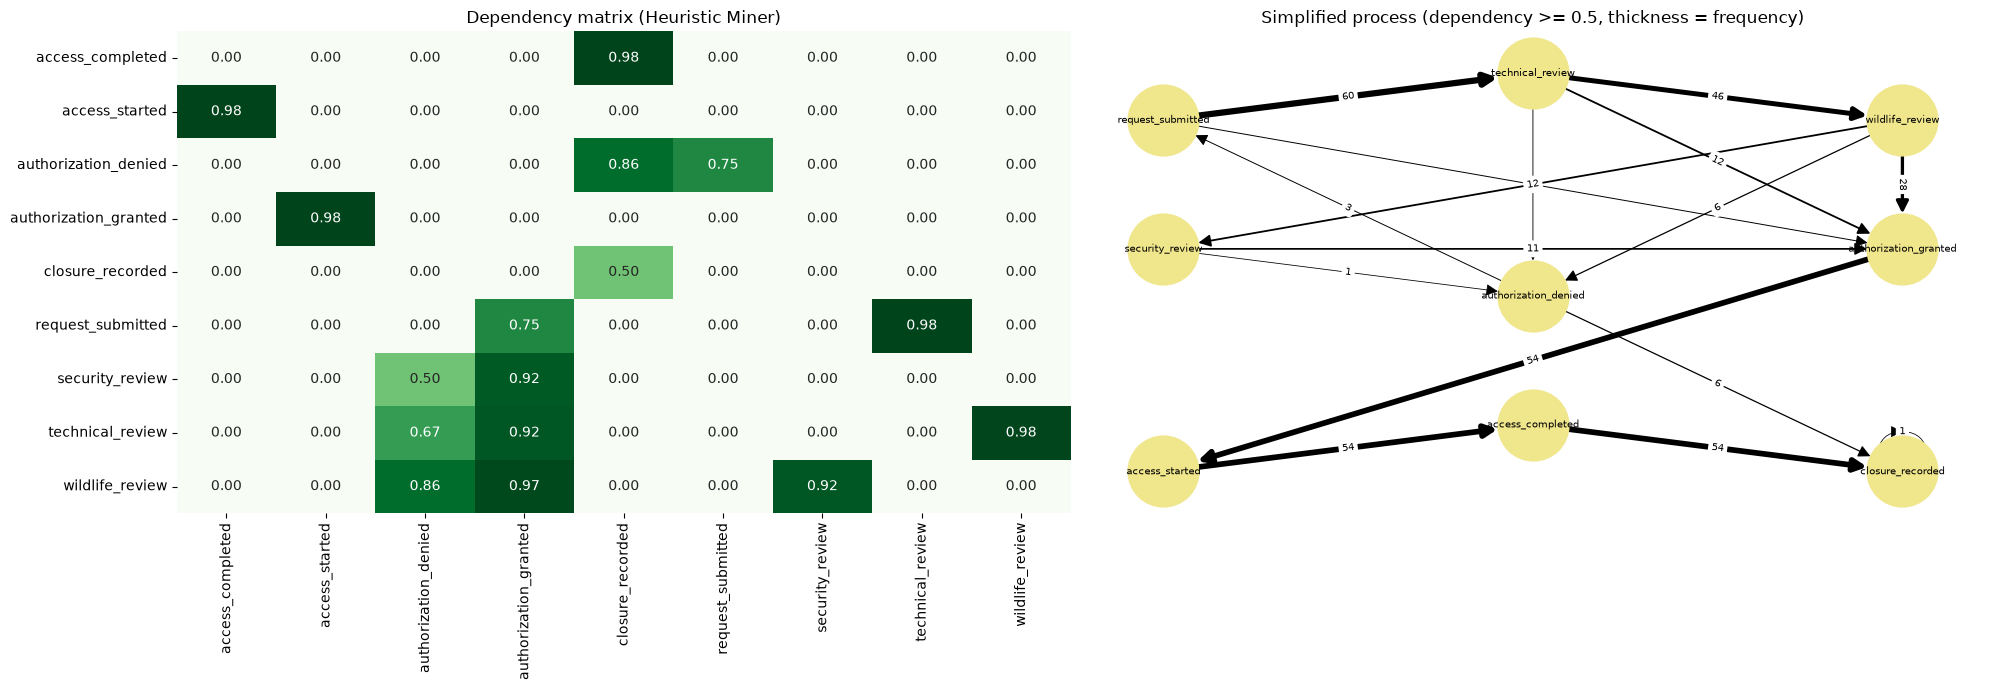

Retained links identical to those of pm4py: False
Links specific to pm4py: [] | specific to our computation: [('closure_recorded', 'closure_recorded')]

Process tree (Inductive Miner):
->( +( 'technical_review', *( 'request_submitted', tau ), X( tau, ->( X( tau, ->( 'wildlife_review', X( tau, 'security_review' ) ) ), X( tau, 'authorization_denied' ) ) ) ), X( tau, ->( 'authorization_granted', 'access_started', 'access_completed' ) ), *( 'closure_recorded', tau ) )


In [87]:
dfg, starts, ends = pm4py.discover_dfg(event_log)

# Heuristic Miner (slide 23): dependency degree a => b = (|a>b| - |b>a|) / (|a>b| + |b>a| + 1)
activities = sorted({a for a, _ in dfg} | {b for _, b in dfg})
dependency = pd.DataFrame(0.0, index=activities, columns=activities)
for (a, b), n_ab in dfg.items():
    n_ba = dfg.get((b, a), 0)
    # loop on a same activity: |a>a| / (|a>a| + 1), as in the original version of the algorithm
    dependency.loc[a, b] = n_ab / (n_ab + 1) if a == b else (n_ab - n_ba) / (n_ab + n_ba + 1)

lambda_threshold = 0.5
G_proc = nx.DiGraph()
for (a, b), n in dfg.items():
    if dependency.loc[a, b] >= lambda_threshold:
        G_proc.add_edge(a, b, weight=n)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
sns.heatmap(dependency, annot=True, fmt=".2f", cmap="Greens", ax=axes[0], cbar=False)
axes[0].set_title("Dependency matrix (Heuristic Miner)")
process_order = ["request_submitted", "technical_review", "wildlife_review", "security_review", "authorization_denied",
              "authorization_granted", "access_started", "access_completed", "closure_recorded"]
pos = {a: (i % 3 * 2.0, -(i // 3) * 1.5 + (0.4 if i % 2 else 0)) for i, a in enumerate(process_order)}
nx.draw_networkx(G_proc, pos, ax=axes[1], node_color="khaki", node_size=2600, font_size=7, arrowsize=18,
                 width=[0.5 + 4 * G_proc[a][b]["weight"] / max(dfg.values()) for a, b in G_proc.edges])
nx.draw_networkx_edge_labels(G_proc, pos, edge_labels={(a, b): G_proc[a][b]["weight"] for a, b in G_proc.edges},
                             font_size=7, ax=axes[1])
axes[1].set_title(f"Simplified process (dependency >= {lambda_threshold}, thickness = frequency)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

pm4py_net = pm4py.discover_heuristics_net(event_log, dependency_threshold=lambda_threshold)
pm4py_links = sorted((a, b) for a, d in pm4py_net.dependency_matrix.items() for b, v in d.items()
                     if v >= lambda_threshold)
print("Retained links identical to those of pm4py:", pm4py_links == sorted(G_proc.edges))
print("Links specific to pm4py:", sorted(set(pm4py_links) - set(G_proc.edges)),
      "| specific to our computation:", sorted(set(G_proc.edges) - set(pm4py_links)))
print("\nProcess tree (Inductive Miner):")
print(pm4py.discover_process_tree_inductive(event_log))

We then summarise each case (organisation, site, purpose, equipment, confidentiality, entry time…) to compare the organisations with each other.

In [88]:
# Characteristics of each case
cases = access_log.groupby("access_case_number").agg(
    site_code=("site_code", "first"), organisation=("requesting_organization_name", "first"),
    purpose=("access_purpose", "first"), equipment=("equipment_category", "first"),
    confidentiality=("confidentiality_class", "first"), start=("event_time", "min"), end=("event_time", "max"),
    n_events=("activity", "size"),
    denied=("activity", lambda a: (a == "authorization_denied").any()),
    granted=("activity", lambda a: (a == "authorization_granted").any()),
)
access_start = access_log[access_log["activity"] == "access_started"].groupby("access_case_number")["event_time"].first()
access_end = access_log[access_log["activity"] == "access_completed"].groupby("access_case_number")["event_time"].first()
cases["access_start"] = access_start
cases["case_duration_d"] = (cases["end"] - cases["start"]).dt.days
cases["access_duration_h"] = (access_end - access_start).dt.total_seconds() / 3600
cases["entry_hour"] = access_start.dt.hour
cases["horizon"] = cases["organisation"].eq("Horizon Field Research Cooperative")

print("Cases per organisation (top 5):")
print(cases["organisation"].value_counts().head(5))
summary_table = cases.groupby("horizon").agg(
    cases=("site_code", "size"), sites=("site_code", "nunique"),
    case_duration_d=("case_duration_d", "median"), access_duration_h=("access_duration_h", "median"),
    entree_18h=("entry_hour", lambda h: (h == 18).mean()),
    confidentiel_ou_restreint=("confidentiality", lambda c: c.isin(["confidential", "restricted"]).mean()),
    cold_storage=("equipment", lambda e: e.str.contains("cold-storage").mean()),
    refus_puis_accord=("denied", lambda r: (r & cases.loc[r.index, "granted"]).mean()),
).rename(index={True: "Horizon Field Research Coop.", False: "others organisations"})
display(summary_table.round(2))
print("Sites visited by Horizon:", sorted(cases.loc[cases["horizon"], "site_code"].unique()))

Cases per organisation (top 5):
organisation
Horizon Field Research Cooperative       18
Nordhaven Maritime Safety Agency          2
Valenne Laboratory Materials              2
Interregional Procurement Cooperative     2
Nordhaven Refrigeration Works             2
Name: count, dtype: int64


,cases,sites,case_duration_d,access_duration_h,entree_18h,confidentiel_ou_restreint,cold_storage,refus_puis_accord
horizon,,,,,,,,
others organisations,42,42,17.0,18.0,0.0,0.26,0.00,0.00
Horizon Field Research Coop.,18,8,34.0,9.0,1.0,0.78,0.39,0.17


Sites visited by Horizon: ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']


**The access process.**

- The normal path is: request → technical review → (wildlife review) → (security review) → authorisation → entry → exit → closure. It covers 50 of the 60 cases.
- The rare paths contain a **denial followed by a new request**, then an authorisation. The Inductive Miner represents this backtracking by a **loop**.
- Our manual computation of the Heuristic Miner gives the same graph as pm4py, except for one loop, which comes from a single case closed twice.

**Horizon versus the other organisations.** The Horizon Field Research Cooperative holds **18 of the 60 cases**; no other organisation has more than 2.

| | Horizon | Other organisations |
|---|---|---|
| Sites | 8 sites, visited repeatedly | 42 sites, each once |
| Case duration (median) | 34 days | 17 days |
| Entry on the site | **always at 6 pm, at night**, 9 h on site | never at night, 18 h on site |
| Confidential or restricted | **78%** | 26% |
| Refrigerated equipment (*cold-storage*) | **39%** | 0% |
| Denial, then approval | 17% (3 cases) | 0% |

Now, night is when the bats are active, and the refrigerated equipment is used to keep samples. **The 8 sites of Horizon include KNT-KES, KNT-LUM and KNT-SEN**, the three caves that dropped in part 2, as well as AVL-MAR, AVL-ORR, AVL-VEL, TMB-NAC and TMB-PEL.

**A contradiction between two sources.** According to the EFR-510088 report, the March 2024 access was for "routine maintenance". The register (case ACC-2024-0014) indicates a **"night wildlife monitoring programme"**, with acoustic equipment and a camera.

**The network of actors.** We build a graph that links the organisations, the people and the sites, from the reports and the access register. The **centrality** measures indicate which actors occupy a key position: the **degree** (number of links), the **betweenness** (how many paths go through the actor) and the **closeness** (how close the actor is to all the others).

In [89]:
# Graph of the actors: organisations, people and sites, from the reports AND the access register
G_act = nx.Graph()
for _, r in reports.iterrows():
    G_act.add_edge(("org", r["author_organization"]), ("site", r["site_code"]), source="report")
    if pd.notna(r["author_name"]):
        G_act.add_edge(("pers", r["author_name"]), ("org", r["author_organization"]), source="report")
        G_act.add_edge(("pers", r["author_name"]), ("site", r["site_code"]), source="report")
for _, r in access_log.iterrows():
    G_act.add_edge(("org", r["requesting_organization_name"]), ("site", r["site_code"]), source="access")
    if pd.notna(r["authorized_person_name"]):
        G_act.add_edge(("pers", r["authorized_person_name"]), ("site", r["site_code"]), source="access")

print(f"{G_act.number_of_nodes()} nodes, {G_act.number_of_edges()} links, "
      f"{nx.number_connected_components(G_act)} component(s) connexe(s)")
centralities = pd.DataFrame({"degree": dict(G_act.degree()), "betweenness": nx.betweenness_centrality(G_act),
                            "closeness": nx.closeness_centrality(G_act)})
centralities["type"] = [n[0] for n in centralities.index]
centralities.index = [n[1] for n in centralities.index]
print("Most central organisations:")
display(centralities[centralities["type"] == "org"].sort_values("betweenness", ascending=False).head(6).round(3))

report_people = set(reports["author_name"].dropna())
access_people = set(access_log["authorized_person_name"].dropna())
print("Report authors who also appear as authorised people in the access register:",
      sorted(report_people & access_people))

145 nodes, 496 links, 1 component(s) connexe(s)
Most central organisations:


,degree,betweenness,closeness,type
Horizon Field Research Cooperative,18,0.044,0.413,org
Avelora Agricultural Resilience Agency,10,0.034,0.371,org
Belen Agro-Industries,8,0.018,0.326,org
Threshold Earth Observatory,9,0.018,0.386,org
Pollinator Justice Network,8,0.014,0.378,org
Asterion Clinical Institute,4,0.003,0.336,org


Report authors who also appear as authorised people in the access register: ['Amina Elen', 'Anika Dren', 'Calen Jaren', 'Daria Zaven', 'Doran Norel', 'Doran Wessen', 'Farah Norel', 'Ilyan Rho', 'J. Varlan', 'Jalen Zorin', 'Jonah Bell', 'Jora Vela', 'Julien Marot', 'Mara Venn', 'Nadia Istra', 'Ravin Palen', 'Selene Aras', 'Uma Wessen', 'Vera Waren', 'Zalia Dalen']


**The network of actors** (145 nodes, 496 links, all connected to each other). The **Horizon Field Research Cooperative is the most central organisation** (18 links, betweenness of 0.044, closeness of 0.41), ahead of the Avelora agricultural resilience agency.

20 report authors are also **authorised people** in the access register: those who write the reports and those who work in the field form a single small network. One organisation requests the accesses, works at night on the sites, and signs the only report that describes a possible removal.

# 10. What happens to the bats after each access?

This is the central test of our hypothesis. If Horizon's accesses come with bat removals, then we should observe:

1. a drop in activity **right after each Horizon access**;
2. **no** drop after the accesses of the other organisations;
3. **no** drop for the comparison species;
4. a drop that is explained neither by a **broken device** nor by a **change in the habitat**.

**Method: an event study.** For each access, we follow the seasonal gap of the site (part 7.2) from 3 months before to 6 months after the month of entry on the site, noted k = 0. We then take the mean, separately for Horizon and for the other organisations.

Accesses covered by the surveys: {'others': 26, 'Horizon': 15}


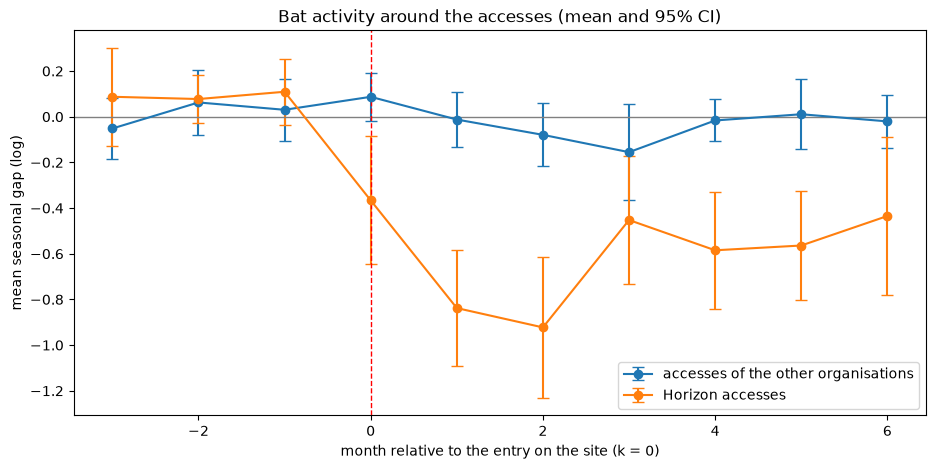

In [90]:
events = cases.dropna(subset=["access_start"]).copy()
events["access_month"] = events["access_start"].dt.to_period("M").dt.to_timestamp()
events = events[(events["access_month"] >= eco["reporting_month"].min())
                        & (events["access_month"] <= eco["reporting_month"].max())]
print("Accesses covered by the surveys:", events["horizon"].value_counts().rename({True: "Horizon", False: "others"}).to_dict())

log_comp = np.log1p(eco["comparison_species_count"])
log_acou = np.log1p(eco["acoustic_detection_count"])
eco["comparison_species_gap"] = log_comp - log_comp.groupby([eco["site_code"], eco["calendar_month"]]).transform("median")
eco["acoustic_gap"] = log_acou - log_acou.groupby([eco["site_code"], eco["calendar_month"]]).transform("median")
for col in ["uptime_pct", "weather_interference", "habitat_disturbance_index"]:
    eco[f"gap_{col}"] = eco[col] - eco.groupby("site_code")[col].transform("median")

indicators = ["seasonal_gap", "acoustic_gap", "comparison_species_gap", "gap_uptime_pct",
               "gap_weather_interference", "gap_habitat_disturbance_index"]
eco_idx = eco.set_index(["site_code", "reporting_month"])
rows = []
for case_id, ev in events.iterrows():
    for k in range(-3, 7):
        key = (ev["site_code"], ev["access_month"] + pd.DateOffset(months=k))
        if key in eco_idx.index:
            rows.append({"case_id": case_id, "site_code": ev["site_code"], "horizon": ev["horizon"], "k": k,
                           "count": eco_idx.loc[key, "observed_bat_count"], **eco_idx.loc[key, indicators].to_dict()})
study = pd.DataFrame(rows)

summary = study.groupby(["horizon", "k"])["seasonal_gap"].agg(["mean", "sem", "count"]).reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
for horizon, group in summary.groupby("horizon"):
    label = "Horizon accesses" if horizon else "accesses of the other organisations"
    ax.errorbar(group["k"], group["mean"], yerr=1.96 * group["sem"], marker="o", capsize=4, label=label)
ax.axhline(0, color="grey", lw=1)
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_xlabel("month relative to the entry on the site (k = 0)")
ax.set_ylabel("mean seasonal gap (log)")
ax.set_title("Bat activity around the accesses (mean and 95% CI)")
ax.legend()
plt.show()

**Controls.** We redo the same computation on other indicators: comparison species, acoustic detections, device uptime, weather interference and habitat disturbance.

In [91]:
# Controls: does the drop also affect the comparison species, the device, the weather, the habitat?
after = study[study["k"].isin([1, 2])].groupby("horizon")[indicators].mean()
before = study[study["k"].isin([-3, -2, -1])].groupby("horizon")[indicators].mean()
controls = pd.concat({"before (k = -3 to -1)": before, "after (k = 1 and 2)": after}).T
controls.columns = [f"{p} | {'Horizon' if h else 'others'}" for p, h in controls.columns]
controls.round(2)

,before (k = -3 to -1) | others,before (k = -3 to -1) | Horizon,after (k = 1 and 2) | others,after (k = 1 and 2) | Horizon
seasonal_gap,0.01,0.09,-0.05,-0.88
acoustic_gap,-0.03,0.13,-0.07,-0.74
comparison_species_gap,0.01,0.01,-0.07,-0.09
gap_uptime_pct,-1.00,-0.55,-1.58,0.40
gap_weather_interference,7.71,-4.84,-2.76,3.68
gap_habitat_disturbance_index,1.03,-0.24,-0.76,-0.76


**Placebo test.** Could such a strong drop happen by chance? We draw 2,000 times "fake accesses", at random dates on the same sites, and redo the same computation. If the real accesses give a stronger drop than all the fake ones, chance is ruled out.

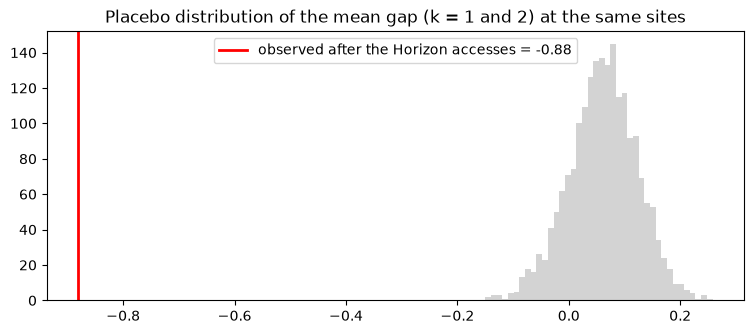

Observed gap = -0.88 (i.e. -59% activity), placebo: mean 0.06, min -0.15; p = 0.0005


In [92]:
# Permutation (placebo) test: do "fake accesses" drawn at random at the same sites give an equally strong drop?
horizon_ev = events[events["horizon"]]
obs = study[study["horizon"] & study["k"].isin([1, 2])]["seasonal_gap"].mean()

gap_by_key = eco.set_index(["site_code", "reporting_month"])["seasonal_gap"].to_dict()
available_months = [pd.Timestamp(m) for m in sorted(eco["reporting_month"].unique())][3:-3]
real = {(s, m + pd.DateOffset(months=k)) for s, m in zip(events["site_code"], events["access_month"])
         for k in range(-3, 7)}
rng = np.random.default_rng(0)
null_dist = []
for _ in range(2000):
    values = []
    for s in horizon_ev["site_code"]:
        while True:                       # placebo month outside the windows of the real accesses
            m = available_months[rng.integers(len(available_months))]
            if (s, m) not in real:
                break
        values += [gap_by_key[(s, m + pd.DateOffset(months=k))] for k in (1, 2)
                    if (s, m + pd.DateOffset(months=k)) in gap_by_key]
    null_dist.append(np.mean(values))
null_dist = np.array(null_dist)
p_value = (1 + (null_dist <= obs).sum()) / (len(null_dist) + 1)

plt.figure(figsize=(9, 3.5))
plt.hist(null_dist, bins=40, color="lightgrey")
plt.axvline(obs, color="red", lw=2, label=f"observed after the Horizon accesses = {obs:.2f}")
plt.legend()
plt.title("Placebo distribution of the mean gap (k = 1 and 2) at the same sites")
plt.show()
print(f"Observed gap = {obs:.2f} (i.e. {100 * (np.exp(obs) - 1):.0f}% activity), "
      f"placebo: mean {null_dist.mean():.2f}, min {null_dist.min():.2f}; p = {p_value:.4f}")

We then look at each Horizon access separately, and check whether it was the subject of a field report within 3 months.

In [93]:
# The episodes one by one, and those that were documented in a field report
episodes = study[study["horizon"]].pivot_table(index=["case_id", "site_code"], columns="k", values="count")
episodes = episodes[[c for c in [-1, 0, 1, 2] if c in episodes.columns]]
episodes.columns = [f"count k={c}" for c in episodes.columns]
episodes = episodes.join(events[["purpose", "equipment", "confidentiality"]], on="case_id")
deficit = (study[study["horizon"] & study["k"].isin([1, 2])].groupby("case_id")["seasonal_gap"].mean()
           .rename("deficit_k1_k2"))
episodes = episodes.join(deficit, on="case_id")

def documented(row):
    m = events.loc[row.name[0], "access_month"]
    r = reports[(reports["site_code"] == row.name[1]) & (reports["document_date"] >= m)
                 & (reports["document_date"] <= m + pd.DateOffset(months=3))]
    return ", ".join(r["document_id"] + " (" + r["document_type"] + ")") or "no report"

episodes["report within 3 months"] = episodes.apply(documented, axis=1)
print("Episodes with a deficit (mean gap k=1-2 < -0.3):", (episodes["deficit_k1_k2"] < -0.3).sum(), "over", len(episodes))
episodes.round(2)

Episodes with a deficit (mean gap k=1-2 < -0.3): 14 over 15


,,count k=-1,count k=0,count k=1,count k=2,purpose,equipment,confidentiality,deficit_k1_k2,report within 3 months
case_id,site_code,,,,,,,,,
ACC-2019-0004,TMB-PEL,11.0,5.0,5.0,3.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,confidential,-0.45,no report
ACC-2019-0005,KNT-LUM,15.0,4.0,3.0,1.0,night wildlife monitoring programme,protective field equipment,confidential,-1.55,no report
ACC-2019-0006,AVL-VEL,18.0,10.0,4.0,10.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted,-0.88,no report
ACC-2020-0007,KNT-SEN,15.0,4.0,9.0,6.0,habitat survey and sample documentation,protective field equipment,restricted,-0.51,no report
ACC-2020-0008,AVL-ORR,23.0,15.0,9.0,8.0,acoustic monitoring and equipment maintenance,acoustic and camera equipment,confidential,-0.51,no report
ACC-2021-0009,KNT-KES,25.0,38.0,9.0,11.0,acoustic monitoring and equipment maintenance,protective field equipment,standard,-0.76,no report
ACC-2021-0010,AVL-MAR,36.0,30.0,3.0,5.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted,-1.21,no report
ACC-2022-0011,TMB-NAC,16.0,8.0,3.0,2.0,habitat survey and sample documentation,acoustic and camera equipment,confidential,-1.72,no report
ACC-2023-0012,KNT-LUM,6.0,3.0,3.0,3.0,habitat survey and sample documentation,portable monitoring and cold-storage equipment,standard,-1.21,no report


**Reverse reading.** Let us start this time from the 72 deficits found without a priori in part 7.2: how many fall within the 3 months following an access?

In [94]:
# Reverse reading: among the deficits detected without a priori by the STL (part 7.2), how many follow an access?
windows = {"Horizon": set(), "others": set()}
for _, ev in events.iterrows():
    for k in range(0, 3):
        windows["Horizon" if ev["horizon"] else "others"].add((ev["site_code"], ev["access_month"] + pd.DateOffset(months=k)))
deficit_keys = list(zip(retained_deficits["site_code"], retained_deficits["reporting_month"]))
print(f"STL deficits retained: {len(deficit_keys)}")
for label, f in windows.items():
    n = sum(c in f for c in deficit_keys)
    print(f"  within the 0-2 months following an access {label}: {n} ({100 * n / len(deficit_keys):.0f}%) "
          f"whereas these windows only cover {100 * len(f) / len(eco):.1f}% of the surveys")
print("\nSites of the 8 Horizon accesses: STL deficits retained outside the access window")
outside = retained_deficits[retained_deficits["site_code"].isin(core_sites)
                        & ~pd.Series(deficit_keys, index=retained_deficits.index).isin(windows["Horizon"])]
outside[["site_code", "reporting_month", "observed_bat_count", "z_stl"]].round(2)

STL deficits retained: 72
  within the 0-2 months following an access Horizon: 6 (8%) whereas these windows only cover 0.9% of the surveys
  within the 0-2 months following an access others: 1 (1%) whereas these windows only cover 1.6% of the surveys

Sites of the 8 Horizon accesses: STL deficits retained outside the access window


,site_code,reporting_month,observed_bat_count,z_stl
1575,AVL-VEL,2020-04-01,6.0,-3.15
1621,AVL-VEL,2024-02-01,4.0,-3.27
2369,KNT-KES,2021-06-01,5.0,-3.38
2695,KNT-SEN,2022-08-01,1.0,-5.06
4225,TMB-PEL,2020-02-01,1.0,-3.83


**The central result.**

- **After the Horizon accesses, the activity drops.** The seasonal gap goes from about +0.1 before the access to **−0.84 then −0.92** one and two months after, i.e. about **59% fewer bats** than usual at this period. The drop is clear from the month of the access. Six months later, the gap is still −0.4 to −0.6: the population does not recover.
- **After the accesses of the 26 other organisations, nothing happens**: the gap stays between −0.15 and +0.09.
- **The controls**:
  - the **comparison species** do not move (−0.09);
  - the **device** works normally (uptime of +0.4 point), without failure, with a quality that is always good;
  - the **habitat disturbance** does not change;
  - the **weather interference** increases a little (+3.7 points), but it has no link with the activity (part 4);
  - the **acoustic detections**, measured independently of the visual count, also drop (−0.74).

  The drop therefore affects **only the bats**: it is neither a measurement error nor a change in the habitat.
- **Placebo test.** Over 2,000 draws of fake accesses, the mean gap is +0.06 and never goes below −0.15. The observed gap (−0.88) is **outside the whole distribution**: p ≈ 0.0005, the smallest possible value with 2,000 draws.
- **Access by access.** **The 14 observable Horizon accesses are all followed by a drop**, from −0.45 to −1.72. The 15th (June 2025, last month of the data) is too recent to be evaluated. **Only one gave rise to a report**: KNT-KES in 2024. The other 13 went unnoticed.
- **Reverse reading.** 8% of the 72 deficits fall within the 3 months following a Horizon access, whereas these periods only represent 0.9% of the surveys: this is **9 times more than chance**. For the other organisations, there is no excess (1% of the deficits for 1.6% of the surveys).

*A correlation is not a causation.* We show a **systematic, specific and robust** coincidence, not *who* removes them nor *why*. But all the other explanations tested are ruled out: season, weather, device, team, habitat, geography.

**And the orchards?** Some bats pollinate the durian flowers. If they disappear, the formation of the fruits (the **fruit set**) could suffer. We first look at which variables are related to the fruit set, then at its evolution after the accesses.

Spearman correlation (orchard surveys):
fruit_set_rate_pct           0.49
durian_yield_kg              0.07
durian_flower_density        0.27
other_pollinator_activity    0.31
Name: hourly_rate, dtype: float64


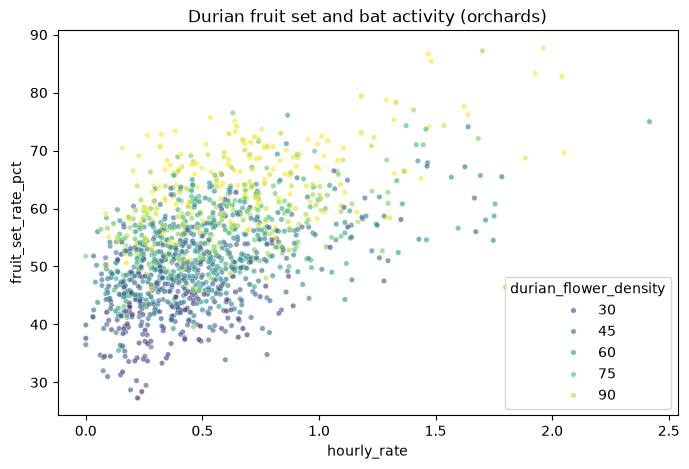

mean       count      
horizon False True  False True 
k                              
-2       2.55  3.03     7     6
-1       1.84  2.83     7     6
 0      -0.54 -1.43     7     6
 1       1.41 -3.09     7     5
 2      -4.83 -5.07     7     5
 3      -1.08  1.96     7     5

In [95]:
# And the orchards? Nectar-feeding bats pollinate the durian
print("Spearman correlation (orchard surveys):")
print(orchard[["fruit_set_rate_pct", "durian_yield_kg", "durian_flower_density", "other_pollinator_activity",
              "hourly_rate"]].corr(method="spearman")["hourly_rate"].drop("hourly_rate").round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=orchard, x="hourly_rate", y="fruit_set_rate_pct", hue="durian_flower_density",
                palette="viridis", s=15, alpha=0.6, ax=ax)
ax.set_title("Durian fruit set and bat activity (orchards)")
plt.show()

orchard["calendar_month"] = orchard["reporting_month"].dt.month
orchard["fruit_set_gap"] = orchard["fruit_set_rate_pct"] - orchard.groupby(["site_code", "calendar_month"])["fruit_set_rate_pct"].transform("median")
v_idx = orchard.set_index(["site_code", "reporting_month"]).sort_index()
rows = []
for case_id, ev in events[events["site_code"].isin(orchard["site_code"].unique())].iterrows():
    for k in range(-2, 4):
        key = (ev["site_code"], ev["access_month"] + pd.DateOffset(months=k))
        if key in v_idx.index:
            rows.append({"horizon": ev["horizon"], "k": k, "fruit_set_gap": v_idx.loc[key, "fruit_set_gap"]})
pd.DataFrame(rows).pivot_table(index="k", columns="horizon", values="fruit_set_gap", aggfunc=["mean", "count"]).round(2)

**The orchards.** In the durian orchards, the bat activity is the variable most related to the **fruit-set rate** (Spearman of **0.49**), ahead of the other pollinators (0.31) and the flower density (0.27). This is consistent with the pollinator role of *Eonycteris spelaea*, the species cited in the report. The yield, for its part, is not related to the activity (0.07).

In the three orchards visited by Horizon (AVL-MAR, AVL-ORR, AVL-VEL), the fruit set drops a little in the month following the access (−3.1 points, versus +1.4 for the other accesses in orchards). But there are **too few cases** (5 to 7 episodes) to conclude. We retain a **plausible but undemonstrated link** between these removals and the pollination.

# 11. Synthesis: what the ecological data hide

## The story in five steps

1. **In appearance**, an ordinary monitoring programme: 64 sites, 78 months, a marked season, and a lower activity where the habitat is disturbed or treated (Spearman of −0.40 and −0.25). A few device failures. Field reports written from templates, which almost never report anything.
2. **A single report stands out** (EFR-510088, KNT-KES, April 2024): traces of handling, cut restraint cords, a drop of *Eonycteris spelaea* right after an "access window".
3. **The access register**, which this report asks to keep, shows that one organisation, the **Horizon Field Research Cooperative**, obtained 18 accesses from 2018 to 2025 on **8 sites, always the same**. These accesses take place at night and are often confidential or restricted (78%). 39% of them use refrigerated equipment, and three were obtained after a denial.
4. **Each of these accesses is followed by a drop in bat activity**: −59% on average (p ≈ 0.0005). The other species are not affected, and neither the device, nor the weather, nor the habitat explain the drop. Nothing similar after the accesses of the other organisations.
5. **Only one of these 14 episodes was reported.** The other 13 went unnoticed, hidden by the standard reports and by the seasonal variations.

**The hypothesis most consistent with the data**: repeated and discreet removals of bats, carried out under cover of authorised accesses for "monitoring" or "maintenance", with a possible but undemonstrated effect on the pollination of the durian orchards.

## What each course brought

| Course | Methods | What they brought |
|---|---|---|
| 1 | cleaning, descriptive statistics, Pearson and Spearman | reliable data; the role of disturbance and pesticides |
| 2 | scalings, distances, PCA, t-SNE, HAC, k-means, DBSCAN | no natural groups; an ecological quality axis; the choice of the control sites |
| 3 | co-occurrences, Apriori, IQR, z-scores, Isolation Forest, LOF, DBSCAN, ABOD | the drops are not repeated situations; an outlier is not necessarily an anomaly |
| 4 | bipartite graph, actor graph, Louvain, Girvan-Newman, Heuristic and Inductive Miner | observation team ruled out; Horizon at the centre of the network; atypical accesses |
| 5 | decomposition, ACF, STL, rolling window, Haversine, Moran, LISA, Voronoi, regionalisation | season removed; local and non-regional deficits |
| 6 | preprocessing, bag of words, n-grams, standard sentences, TF-IDF, LSA, LDA | EFR-510088, the only original report |

## Limits

- **A correlation is not a causation.** We show a systematic coincidence, not the author nor the purpose of the removals.
- **Few cases**: 14 Horizon episodes, and 5 to 7 for the orchards. The placebo test partly compensates for this lack for the main result, but not for the fruit set.
- **Cleaning and threshold choices** (median for filling, tertiles, z = −3, λ = 0.5) can introduce biases. We justified them and, when possible, compared them: MAD versus standard deviation, standardisation versus min-max, four anomaly detectors, three perplexities for the t-SNE.
- **Text**: no lemmatisation (choice explained in part 8).
- **Synthetic data**: the story is fictional (README).

## Leads outside the ecology dataset

- The procedure register (`regulatory_case_events`) contains two environmental complaints targeting KNT-KES, in March 2019 and April 2023. They are attached to the shipments `SHP-2018-00007` and `SHP-2024-00007`. The second involves **Meridian BioLogistics**, a biological logistics and cold-chain company.
- The **Asterion Clinical Institute**, which signs 2 ecological reports, has the same name as the "Asterion Central Clinical Campus" of the `health` dataset, where we find "metabolic resilience administration" procedures.

These leads are followed in `../logistics/02_analysis.ipynb`, `../health/03_report.ipynb` and `../00_synthesis.ipynb`.

# Appendix: use of generative AI

The README and course 0 ask for honesty and transparency about the use of generative AI. We used a generative AI assistant, Claude (Anthropic).

- **Why and for what**: we used the assistant to obtain **guidelines** and to **propose the analysis steps**, relying on the materials of courses 0 to 6: which methods to apply to our data, in which order, and with which checks. We called on it after our initial work of part 1.